# Structural Steel MFA 1931-2100

## Imports

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit
import weibull
from scipy.stats import linregress 
from scipy.optimize import curve_fit
from scipy.stats import pearsonr, spearmanr
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

## Read in Data

In [2]:
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
# df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)

In [3]:
df_recycling = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_recycling.csv", index_col=0)

In [4]:
df_recycling

,scrap,Exports,Imports
1998,73000,5950,3370
1999,71000,5560,4020
2000,74000,5810,3630
2001,71000,7530,2810
2002,69000,9000,3320
2003,65000,10900,3690
2004,66600,11800,4790
2005,65600,13000,4000
2006,65300,14100,5000
2007,65000,16700,3780


In [5]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,124039648.0,124039648.0,124039648.0,124039648.0,124039648.0,U.S. Censusu Bureau
1932,124840471.0,124840471.0,124840471.0,124840471.0,124840471.0,U.S. Censusu Bureau
1933,125578763.0,125578763.0,125578763.0,125578763.0,125578763.0,U.S. Censusu Bureau
1934,126373773.0,126373773.0,126373773.0,126373773.0,126373773.0,U.S. Censusu Bureau
1935,127250232.0,127250232.0,127250232.0,127250232.0,127250232.0,U.S. Censusu Bureau
...,...,...,...,...,...,...
2080,392501973.0,404260551.0,420497001.0,348010415.0,448127860.0,IIASA
2085,392186330.0,406044541.0,429693201.0,341897990.0,450578954.0,IIASA
2090,390155587.0,406645230.0,439152913.0,334254837.0,450632128.0,IIASA
2095,386290251.0,406411009.0,449283549.0,325383215.0,448101727.0,IIASA


## Clean / Prep Data

In [6]:
# ## Clean up floorspace DF ##
# df_floorspace = df_floorspace.iloc[0]
# df_floorspace = pd.DataFrame([df_floorspace])
# df_floorspace = df_floorspace.T

In [6]:
df_gdp

,gdp_ssp1,gdp_ssp2,gdp_ssp3,gdp_ssp4,gdp_ssp5,Source
1931,9931.00,9931.00,9931.00,9931.00,9931.00,Maddison Project
1932,8381.00,8381.00,8381.00,8381.00,8381.00,Maddison Project
1933,8048.00,8048.00,8048.00,8048.00,8048.00,Maddison Project
1934,8667.00,8667.00,8667.00,8667.00,8667.00,Maddison Project
1935,9681.00,9681.00,9681.00,9681.00,9681.00,Maddison Project
...,...,...,...,...,...,...
2080,119442.20,106697.52,83008.20,114520.71,157204.91,IIASA
2085,124303.92,110592.55,83593.36,118310.73,169937.36,IIASA
2090,129375.05,114706.62,84227.38,122246.85,183727.02,IIASA
2095,134619.76,118978.81,84841.97,126292.32,198572.54,IIASA


In [7]:
## Get gpd DF
df_gdp.index = df_gdp.index.astype(int)  # ensure index is numeric
df_gdp = df_gdp.sort_index()
df_gdp = df_gdp.reindex(
    range(df_gdp.index.min(), df_gdp.index.max() + 1)
)

cols = ['gdp_ssp1','gdp_ssp2','gdp_ssp3','gdp_ssp4','gdp_ssp5']

df_gdp[cols] = (
    df_gdp[cols]
      .apply(pd.to_numeric, errors='coerce')
      .interpolate(method='cubic')
)

df_gdp= df_gdp.loc[df_gdp.index >= 1931]

In [8]:
df_gdp

,gdp_ssp1,gdp_ssp2,gdp_ssp3,gdp_ssp4,gdp_ssp5,Source
1931,9931.000000,9931.000000,9931.000000,9931.000000,9931.000000,Maddison Project
1932,8381.000000,8381.000000,8381.000000,8381.000000,8381.000000,Maddison Project
1933,8048.000000,8048.000000,8048.000000,8048.000000,8048.000000,Maddison Project
1934,8667.000000,8667.000000,8667.000000,8667.000000,8667.000000,Maddison Project
1935,9681.000000,9681.000000,9681.000000,9681.000000,9681.000000,Maddison Project
...,...,...,...,...,...,...
2096,135685.626691,119845.660276,84960.532000,127108.928937,201666.721758,NaN
2097,136756.375509,120715.274883,85077.573401,127926.765039,204802.294777,NaN
2098,137831.680982,121587.065352,85193.064801,128745.280673,207979.129917,NaN
2099,138911.217636,122460.443214,85306.976801,129563.928205,211197.098038,NaN


In [9]:
## Get pop DF
df_population.index = df_population.index.astype(int)  # ensure index is numeric
df_population = df_population.sort_index()
df_population = df_population.reindex(
    range(1931, 2100+1)
)

cols = ['pop_ssp1','pop_ssp2','pop_ssp3','pop_ssp4','pop_ssp5']

df_population[cols] = (
    df_population[cols]
      .interpolate(method='cubic')
)


In [10]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,U.S. Censusu Bureau
1932,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,U.S. Censusu Bureau
1933,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,U.S. Censusu Bureau
1934,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,U.S. Censusu Bureau
1935,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,U.S. Censusu Bureau
...,...,...,...,...,...,...
2096,3.852488e+08,4.062801e+08,4.514007e+08,3.234784e+08,4.472286e+08,NaN
2097,3.841043e+08,4.061230e+08,4.535483e+08,3.215325e+08,4.462173e+08,NaN
2098,3.828507e+08,4.059405e+08,4.557263e+08,3.195466e+08,4.450611e+08,NaN
2099,3.814823e+08,4.057335e+08,4.579347e+08,3.175217e+08,4.437532e+08,NaN


In [12]:
## Identify 1931 Base stock ## 
# base_stock = df_floorspace.loc[1931,'Total U.S. floor space (million sq ft)']*0.101818*0.25*68

For now, base stock is calculated from Levesque et al (2016) estimate of floorespace in 1931, percentage of structural steel calculated given the AISC white paper data, Pomponi et al's finding that structural steel is about 68 kg / ft^2 MI, and a rough estimation of the amount of buldings in 1931 one that had steel structures (currently assumed to be 25%) **TO BE VERIFIED IN FUTURE MODEL** 

## Get elasticities of Populatiopn and steel and GDP/cap and steel

In [11]:
## Create Elasticities df
df_elasticities = pd.concat([df_population['pop_ssp2'],df_gdp['gdp_ssp2'],df_steel['total-production']],axis = 1)

In [12]:
df_elasticities

,pop_ssp2,gdp_ssp2,total-production
1931,1.240396e+08,9931.000000,23536.93607
1932,1.248405e+08,8381.000000,12411.20919
1933,1.255788e+08,8048.000000,21075.74094
1934,1.263738e+08,8667.000000,23636.72651
1935,1.272502e+08,9681.000000,30928.68612
...,...,...,...
2096,4.062801e+08,119845.660276,NaN
2097,4.061230e+08,120715.274883,NaN
2098,4.059405e+08,121587.065352,NaN
2099,4.057335e+08,122460.443214,NaN


In [13]:
df_elasticities = df_elasticities.loc[1931:2023]

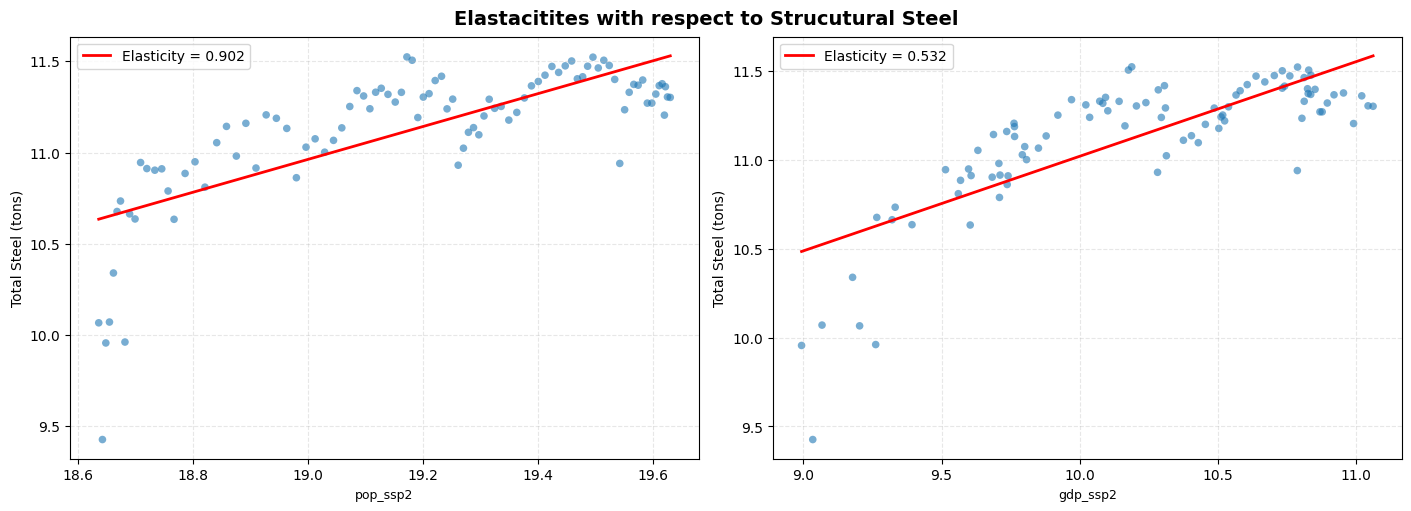

In [14]:
### Graph Relationship 

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)
axes = axes.flatten()

xcols = ['pop_ssp2', 'gdp_ssp2']

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_elasticities['total-production'].loc[1931:2023])
    ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')

    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() > 1:
        slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

        # slope = elasticity
        X_sorted = np.sort(x[mask])
        ax.plot(X_sorted, intercept + slope*X_sorted, 
                color='red', lw=2, 
                label=f"Elasticity = {slope:.3f}")
    ax.set_xlabel(xcol,fontsize = 9)
    ax.set_ylabel('Total Steel (tons)')
    ax.grid(True, linestyle = '--', alpha = 0.3)
    ax.legend(loc = 'upper left')

for ax in axes[len(xcols):]:
    ax.set_visible(False)

fig.suptitle('Elastacitites with respect to Strucutural Steel', fontsize = 14, fontweight = 'bold')
plt.show()

pop_ssp2: Elasticity = 0.902, R² = 0.5529
gdp_ssp2: Elasticity = 0.532, R² = 0.6068


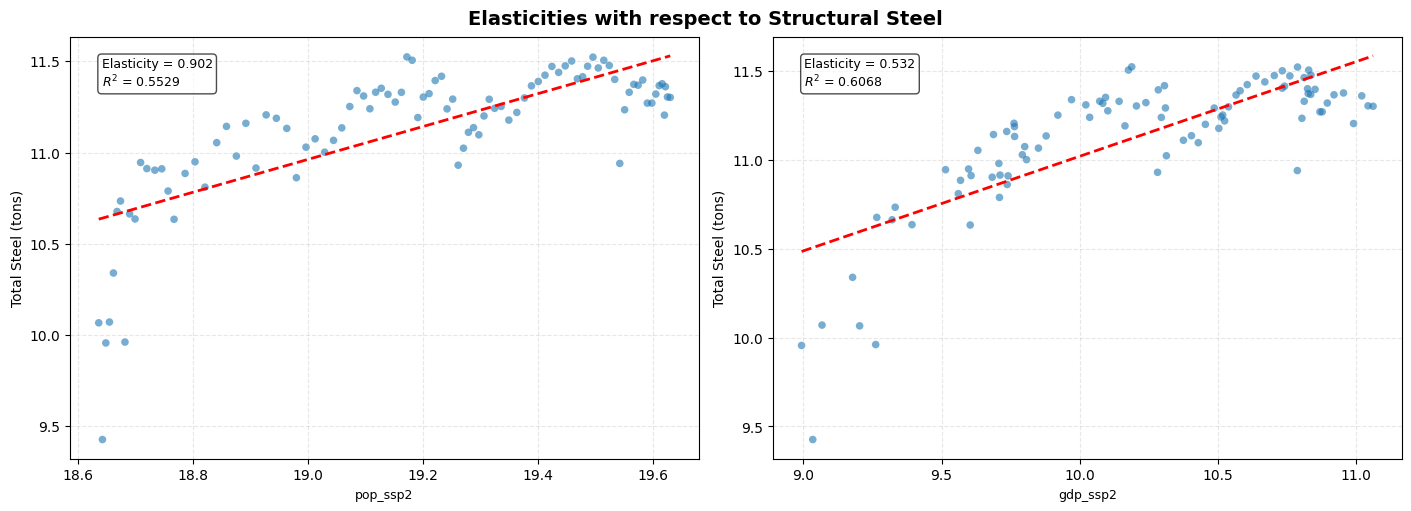

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), constrained_layout=True)
axes = axes.flatten()

xcols = ['pop_ssp2', 'gdp_ssp2']

def power_law(x, a, b):
    return a + b * x  # linear in log-log space (equivalent to power law)

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_elasticities['total-production'].loc[1931:2023])

    mask = np.isfinite(x) & np.isfinite(y)
    x_clean = x[mask].values
    y_clean = y[mask].values

    ax.scatter(x_clean, y_clean, alpha=0.6, s=30, color='tab:blue', edgecolor='none')

    if len(x_clean) > 1:
        popt, _ = curve_fit(power_law, x_clean, y_clean)
        intercept, slope = popt  # a=intercept, b=slope (elasticity)

        r_value, _ = pearsonr(x_clean, y_clean)
        r_squared = r_value ** 2

        print(f"{xcol}: Elasticity = {slope:.3f}, R² = {r_squared:.4f}")

        X_sorted = np.sort(x_clean)
        ax.plot(X_sorted, power_law(X_sorted, *popt),
            color='red', lw=2, linestyle='--')

        ax.set_xlabel(xcol, fontsize=9)
        ax.set_ylabel('Total Steel (tons)')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.text(0.05, 0.95, f"Elasticity = {slope:.3f}\n$R^2$ = {r_squared:.4f}",
                transform=ax.transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

for ax in axes[len(xcols):]:
    ax.set_visible(False)

fig.suptitle('Elasticities with respect to Structural Steel', fontsize=14, fontweight='bold')
plt.show()

pop_ssp2: Elasticity = 0.902 | R² = 0.5529 | Spearman r = 0.744 (p=0.0000)
gdp_ssp2: Elasticity = 0.532 | R² = 0.6068 | Spearman r = 0.759 (p=0.0000)


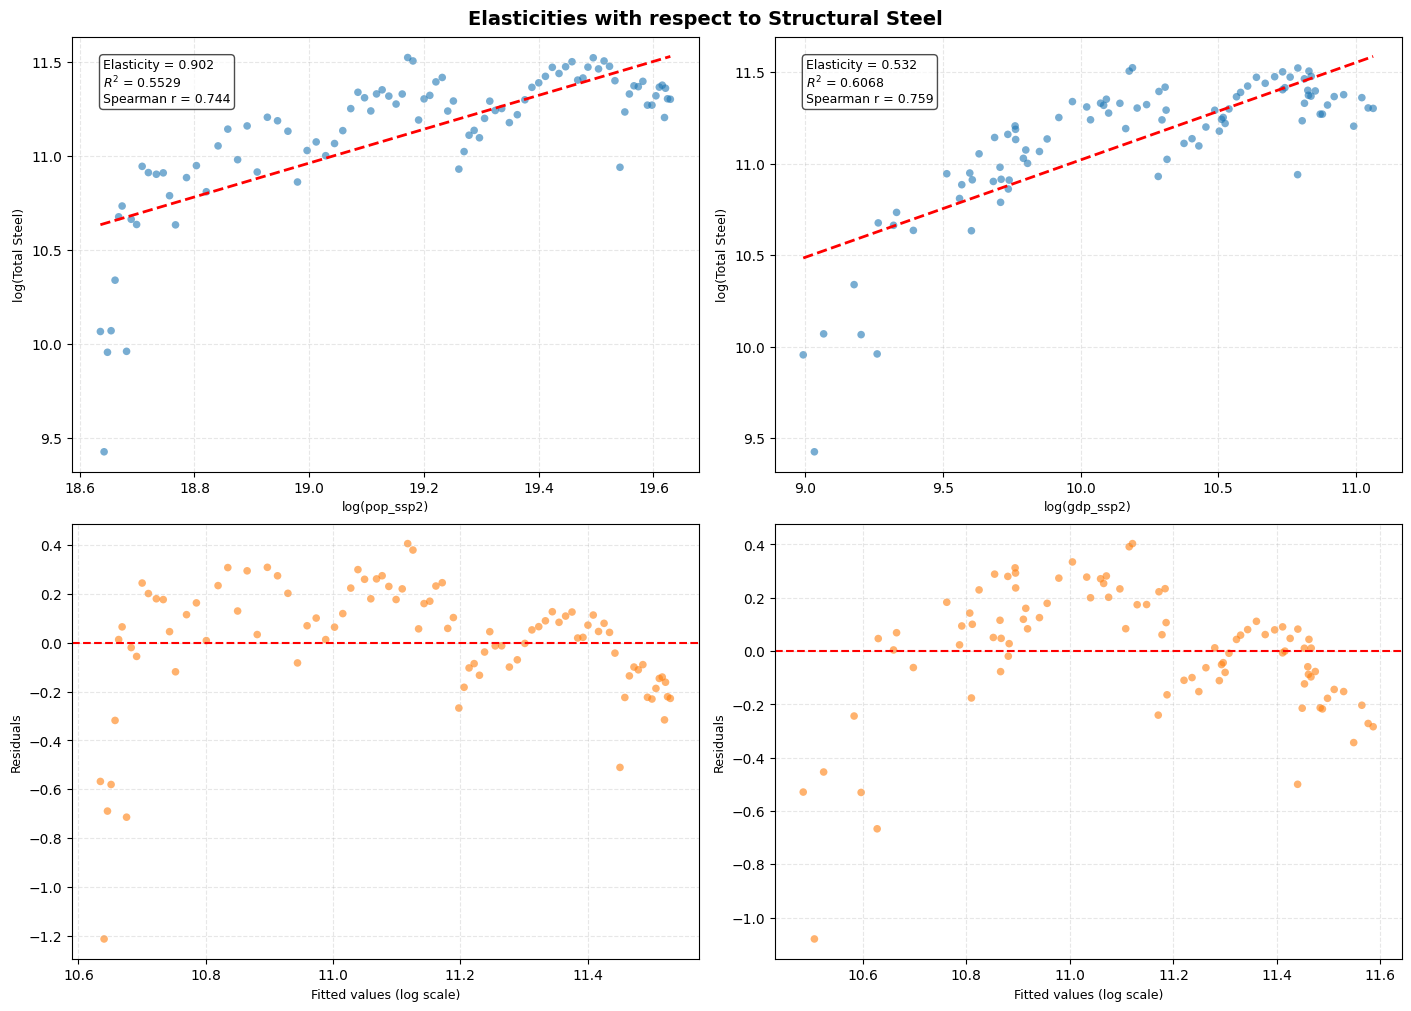

In [22]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), constrained_layout=True)

xcols = ['pop_ssp2', 'gdp_ssp2']

def power_law(x, a, b):
    return a + b * x

for i, xcol in enumerate(xcols):
    ax_fit = axes[0, i]
    ax_resid = axes[1, i]

    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_elasticities['total-production'].loc[1931:2023])

    mask = np.isfinite(x) & np.isfinite(y)
    x_clean = x[mask].values
    y_clean = y[mask].values

    popt, _ = curve_fit(power_law, x_clean, y_clean)
    intercept, slope = popt

    y_fitted = power_law(x_clean, *popt)
    residuals = y_clean - y_fitted

    r_value, _ = pearsonr(x_clean, y_clean)
    r_squared = r_value ** 2
    spearman_r, spearman_p = spearmanr(x_clean, y_clean)

    print(f"{xcol}: Elasticity = {slope:.3f} | R² = {r_squared:.4f} | "
          f"Spearman r = {spearman_r:.3f} (p={spearman_p:.4f})")

    # --- Top row: scatter + fit ---
    X_sorted = np.sort(x_clean)
    ax_fit.scatter(x_clean, y_clean, alpha=0.6, s=30, color='tab:blue', edgecolor='none')
    ax_fit.plot(X_sorted, power_law(X_sorted, *popt), color='red', lw=2, linestyle='--')
    ax_fit.set_xlabel(f'log({xcol})', fontsize=9)
    ax_fit.set_ylabel('log(Total Steel)', fontsize=9)
    ax_fit.grid(True, linestyle='--', alpha=0.3)
    ax_fit.text(0.05, 0.95,
                f"Elasticity = {slope:.3f}\n$R^2$ = {r_squared:.4f}\nSpearman r = {spearman_r:.3f}",
                transform=ax_fit.transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # --- Bottom row: residuals vs fitted ---
    ax_resid.scatter(y_fitted, residuals, alpha=0.6, s=30, color='tab:orange', edgecolor='none')
    ax_resid.axhline(0, color='red', lw=1.5, linestyle='--')
    ax_resid.set_xlabel('Fitted values (log scale)', fontsize=9)
    ax_resid.set_ylabel('Residuals', fontsize=9)
    ax_resid.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Elasticities with respect to Structural Steel', fontsize=14, fontweight='bold')
plt.show()

## Forecasting Population and Economic Data

In [20]:
#### Get Variables and Constants for Forecast ####
# Percantage of structural steel 


### GDP linear regression
# X_gdp = np.array(df_gdp_SSP2.index).reshape(-1, 1)
# # y_gdp = df_gdp_SSP2["SSP2"].values
# gdp_model = LinearRegression()
# gdp_model.fit(X_gdp, y_gdp)

# # Get GDP elasticity approx 
# gdp_elast = gdp_model.coef_[0]


# ### Population Regression
# def logistic(t, K, r, t0):
#     return K / (1 + np.exp(-r * (t - t0)))

# ## Fit model
# t = df_population.index.values.astype(float)
# P = df_population["Population (Thousands)"].values

# p0 = [P.max() * 1.1, 0.03, 2000]

# params, covariance = curve_fit(logistic, t, P, p0=p0, maxfev=10000)
# K, r, t0 = params

# ## Population elasticity Approx
# P_hat = logistic(t, K, r, t0)
# pop_elast = r * (1 - P_hat / K) * t
# pop_elast_series = pd.Series(pop_elast, index=df_population.index, name="pop_elasticity")

In [ ]:
## Define elasticities

pop_elast = 0.902
gdp_elast = 0.528
stuctural_constant = (6100/82500)^2

In [41]:
stuctural_constant 

0.05175757575757576

## Forecast Structural Steel Inflows 

In [53]:
### Validate
df_steel.index = df_steel.index.astype(int)
df_population.index = df_population.index.astype(int)
df_gdp.index = df_gdp.index.astype(int)

#build forecast years
# forecast_years = np.arange(2024, 2101)
validation_years = np.arange(1931,2024)

pop_valid = df_population.loc[validation_years, "pop_ssp1"]
gdp_valid = df_gdp.loc[validation_years, "gdp_ssp1"]


steel_valid_vals = stuctural_constant * (gdp_valid ** gdp_elast) * (pop_valid ** pop_elast) 


df_steel_valid = pd.DataFrame({
    "structural-total": steel_valid_vals/1e5,
}, index=validation_years)

In [48]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [54]:
df_steel_valid

,structural-total
1931,1332.839376
1932,1225.707094
1933,1206.145182
1934,1261.430193
1935,1345.680144
...,...
2019,8130.558776
2020,8317.874297
2021,8462.346123
2022,8592.831980


In [ ]:
## Validation
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(7, 10), constrained_layout=True)

xcol = 'structural-total'

def power_law(x, a, b):
    return a + b * x

x = np.log(df_steel[xcol].loc[1931:2023])
y = np.log(df_steel_valid[xcol].loc[1931:2023])

mask = np.isfinite(x) & np.isfinite(y)
x_clean = x[mask].values
y_clean = y[mask].values

# Fit line
coeffs = np.polyfit(x_clean, y_clean, deg=1)
y_fitted = np.polyval(coeffs, x_clean)
residuals = y_clean - y_fitted

r_value, _ = pearsonr(x_clean, y_clean)
r_squared = r_value ** 2
spearman_r, spearman_p = spearmanr(x_clean, y_clean)

print(f"{xcol}: R² = {r_squared:.4f} | Spearman r = {spearman_r:.3f} (p={spearman_p:.4f})")

# --- Top: scatter + fit ---
X_sorted = np.sort(x_clean)
axes[0].scatter(x_clean, y_clean, alpha=0.6, s=30, color='tab:blue', edgecolor='none')
axes[0].plot(X_sorted, np.polyval(coeffs, X_sorted), color='red', lw=2, linestyle='--')
axes[0].set_xlabel(f'log({xcol})', fontsize=9)
axes[0].set_ylabel('log(Total Steel)', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.3)
axes[0].text(0.05, 0.95,
             f"$R^2$ = {r_squared:.4f}",
             transform=axes[0].transAxes, fontsize=9, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# --- Bottom: residuals vs fitted ---
axes[1].scatter(y_fitted, residuals, alpha=0.6, s=30, color='tab:orange', edgecolor='none')
axes[1].axhline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Fitted values (log scale)', fontsize=9)
axes[1].set_ylabel('Residuals', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Validation: Structural Steel', fontsize=14, fontweight='bold')
plt.show()

KeyError: 'log_gdp'

structural-total: Linear R² = 0.5835 | Quadratic R² = 0.6602 | Spearman r = 0.747 (p=0.0000)


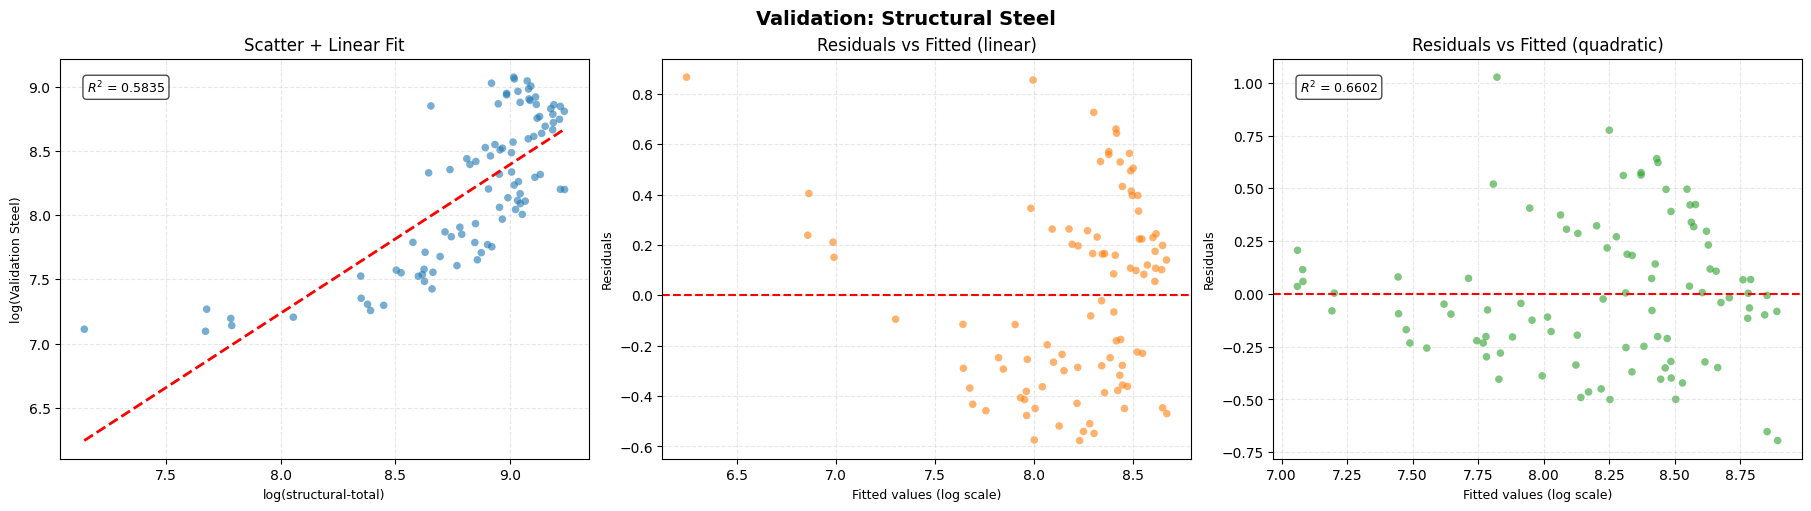

In [343]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), constrained_layout=True)

xcol = 'structural-total'

x = np.log(df_steel[xcol].loc[1931:2023])
y = np.log(df_steel_valid[xcol].loc[1931:2023])

mask = np.isfinite(x) & np.isfinite(y)
x_clean = x[mask].values
y_clean = y[mask].values

# Linear fit
coeffs_lin = np.polyfit(x_clean, y_clean, deg=1)
y_fitted_lin = np.polyval(coeffs_lin, x_clean)
residuals_lin = y_clean - y_fitted_lin

# Quadratic fit
coeffs_quad = np.polyfit(x_clean, y_clean, deg=2)
y_fitted_quad = np.polyval(coeffs_quad, x_clean)
residuals_quad = y_clean - y_fitted_quad

# Stats (linear)
r_value, _ = pearsonr(x_clean, y_clean)
r_squared_lin = r_value ** 2
spearman_r, spearman_p = spearmanr(x_clean, y_clean)

# R² for quadratic (manual calculation)
ss_res = np.sum(residuals_quad ** 2)
ss_tot = np.sum((y_clean - np.mean(y_clean)) ** 2)
r_squared_quad = 1 - (ss_res / ss_tot)

print(f"{xcol}: Linear R² = {r_squared_lin:.4f} | Quadratic R² = {r_squared_quad:.4f} | "
      f"Spearman r = {spearman_r:.3f} (p={spearman_p:.4f})")

# --- Left: scatter + linear fit ---
X_sorted = np.sort(x_clean)
axes[0].scatter(x_clean, y_clean, alpha=0.6, s=30, color='tab:blue', edgecolor='none')
axes[0].plot(X_sorted, np.polyval(coeffs_lin, X_sorted), color='red', lw=2, linestyle='--')
axes[0].set_xlabel(f'log({xcol})', fontsize=9)
axes[0].set_ylabel('log(Validation Steel)', fontsize=9)
axes[0].set_title('Scatter + Linear Fit')
axes[0].grid(True, linestyle='--', alpha=0.3)
axes[0].text(0.05, 0.95, f"$R^2$ = {r_squared_lin:.4f}",
             transform=axes[0].transAxes, fontsize=9, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# --- Middle: residuals vs fitted (linear) ---
axes[1].scatter(y_fitted_lin, residuals_lin, alpha=0.6, s=30, color='tab:orange', edgecolor='none')
axes[1].axhline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Fitted values (log scale)', fontsize=9)
axes[1].set_ylabel('Residuals', fontsize=9)
axes[1].set_title('Residuals vs Fitted (linear)')
axes[1].grid(True, linestyle='--', alpha=0.3)

# --- Right: residuals vs fitted (quadratic) ---
axes[2].scatter(y_fitted_quad, residuals_quad, alpha=0.6, s=30, color='tab:green', edgecolor='none')
axes[2].axhline(0, color='red', lw=1.5, linestyle='--')
axes[2].set_xlabel('Fitted values (log scale)', fontsize=9)
axes[2].set_ylabel('Residuals', fontsize=9)
axes[2].set_title('Residuals vs Fitted (quadratic)')
axes[2].grid(True, linestyle='--', alpha=0.3)
axes[2].text(0.05, 0.95, f"$R^2$ = {r_squared_quad:.4f}",
             transform=axes[2].transAxes, fontsize=9, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

fig.suptitle('Validation: Structural Steel', fontsize=14, fontweight='bold')
plt.show()

In [77]:
## Forecast Structural steel for different SSPs

def forecast_structural_steel(
    df_population,
    df_gdp,
    df_historical_steel,        # NEW: actual observed steel demand history
    structural_constant,
    gdp_elast,
    pop_elast,
    arima_order=(1, 1, 1),      # (p, d, q) — tune this
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)
    historical_years = df_historical_steel.index.astype(int)

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"gdp_ssp{s}"

        # --- Step 1: Structural fitted values over historical period ---
        pop_hist = df_population.loc[historical_years, pop_col]
        gdp_hist = df_gdp.loc[historical_years, gdp_col]
        structural_hist = (
            structural_constant * (gdp_hist ** gdp_elast) * (pop_hist ** pop_elast)
        ) / scale

        # --- Step 2: Compute residuals (actual - structural) ---
        residuals = df_historical_steel - structural_hist

        # --- Step 3: Fit ARIMA on residuals ---
        arima_model = ARIMA(residuals, order=arima_order).fit()

        # --- Step 4: Forecast residuals forward ---
        n_steps = len(forecast_years)
        residual_forecast = arima_model.forecast(steps=n_steps)
        residual_forecast.index = forecast_years

        # --- Step 5: Structural forecast over future period ---
        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]
        structural_fore = (
            structural_constant * (gdp_fore ** gdp_elast) * (pop_fore ** pop_elast)
        ) / scale

        # --- Step 6: Combined forecast = structural + ARIMA residual ---
        data[f"structural_ssp{s}"] = structural_fore + residual_forecast

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"
    return df_steel_forecast

In [76]:
df_steel['structural-total']

1931    2396.48
1932    1263.68
1933    2145.89
1934    2406.64
1935    3149.10
         ...   
2019    8888.71
2020    7483.62
2021    8746.17
2022    8267.62
2023    8247.26
Name: structural-total, Length: 93, dtype: float64

In [78]:
df_steel_forecast = forecast_structural_steel(
    df_population=df_population,
    df_gdp=df_gdp,
    df_historical_steel = df_steel['structural-total'],
    structural_constant=stuctural_constant,  
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    scenarios=range(1, 6),    
    start_year=2024,
    end_year=2100,
    scale=1e5
)


c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\aorga\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index begi

In [79]:
df_steel_forecast

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
year,,,,,
2024,8522.335504,8522.584699,8529.858514,8526.867583,8503.722992
2025,8762.411317,8761.894991,8741.742025,8750.325503,8813.781099
2026,8947.458842,8946.542367,8904.586360,8921.459668,9055.288841
2027,9075.064821,9073.739303,9024.196645,9043.362855,9203.215254
2028,9167.435202,9164.657603,9115.946585,9135.244791,9293.139329
...,...,...,...,...,...
2096,14488.136793,14231.100943,13023.327638,11909.739051,20548.419477
2097,14509.758840,14281.399071,13089.972737,11884.767213,20675.642745
2098,14527.279917,14330.786455,13157.346662,11857.851342,20796.972289


In [80]:
## Create single dataset ##
historic_years = df_steel.index
historic = df_steel.iloc[:,1]

historic.index = historic.index.astype(int)
df_steel_forecast.index = df_steel_forecast.index.astype(int)

historic = pd.DataFrame(
    {col: historic for col in df_steel_forecast.columns}
)

MFA_Data_Total = pd.concat([historic, df_steel_forecast], axis=0)

In [81]:
MFA_Data_Total.loc[2020:2025]

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
2020,7483.620000,7483.620000,7483.620000,7483.620000,7483.620000
2021,8746.170000,8746.170000,8746.170000,8746.170000,8746.170000
2022,8267.620000,8267.620000,8267.620000,8267.620000,8267.620000
2023,8247.260000,8247.260000,8247.260000,8247.260000,8247.260000
2024,8522.335504,8522.584699,8529.858514,8526.867583,8503.722992
2025,8762.411317,8761.894991,8741.742025,8750.325503,8813.781099


## Perform MFA

In [82]:
## Define survival Function
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        # Normal
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull':
        # Weibull 
            lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

Text(0.5, 0, 'Age to Failuire')

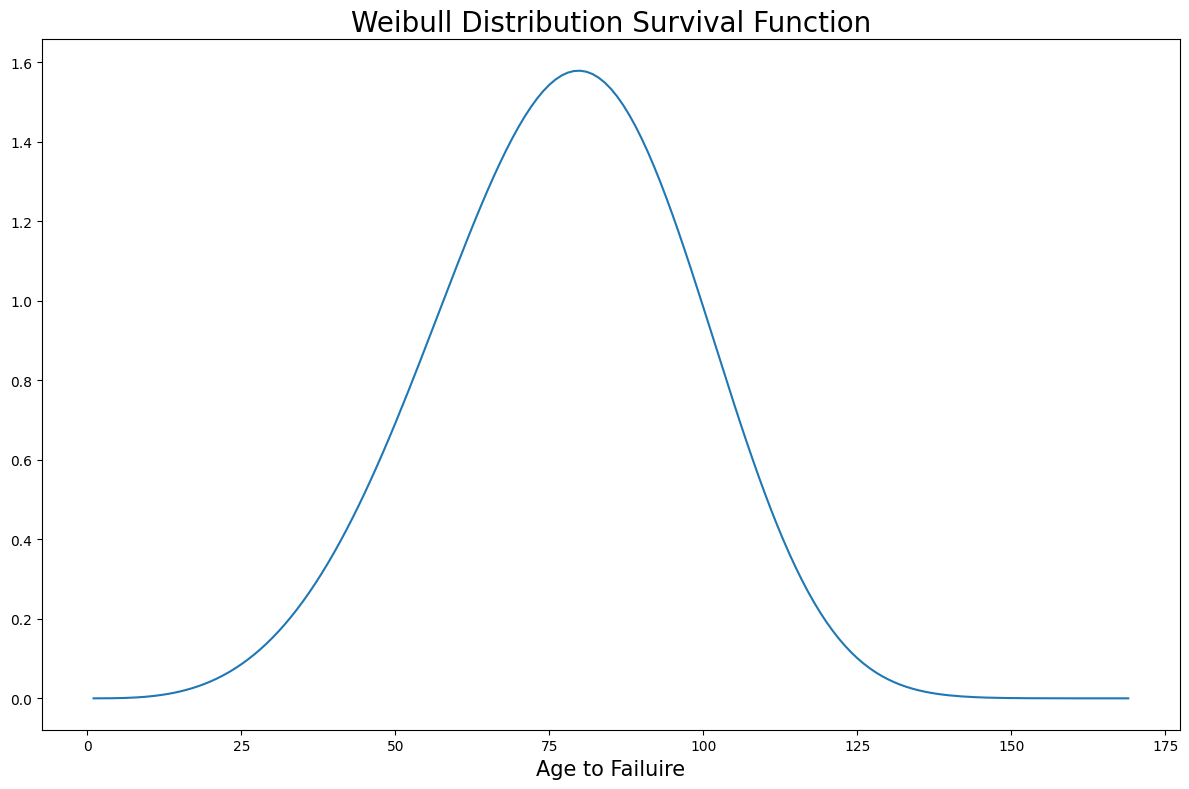

In [83]:
## See weibull shapes
lt_buildings = generate_lt('Weibull',par1=4.16,par2=85.19)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [84]:
MFA_Data_Total

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
1931,2396.480000,2396.480000,2396.480000,2396.480000,2396.480000
1932,1263.680000,1263.680000,1263.680000,1263.680000,1263.680000
1933,2145.890000,2145.890000,2145.890000,2145.890000,2145.890000
1934,2406.640000,2406.640000,2406.640000,2406.640000,2406.640000
1935,3149.100000,3149.100000,3149.100000,3149.100000,3149.100000
...,...,...,...,...,...
2096,14488.136793,14231.100943,13023.327638,11909.739051,20548.419477
2097,14509.758840,14281.399071,13089.972737,11884.767213,20675.642745
2098,14527.279917,14330.786455,13157.346662,11857.851342,20796.972289
2099,14540.425132,14379.243000,13225.446852,11828.985628,20911.928417


In [85]:
## Perform MFA ssp1
years = MFA_Data_Total.index

steel_DSM_ssp1 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp1']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

In [86]:
## Define aspects of MFA
stock_by_cohort =  steel_DSM_ssp1.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp1.dimension_check()
S_steel = steel_DSM_ssp1.compute_stock_total() 
O_C = steel_DSM_ssp1.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp1.compute_stock_change()
O_steel = steel_DSM_ssp1.compute_outflow_total()

In [87]:
## Perform MFA ssp2

steel_DSM_ssp2 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp2']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp2.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp2.dimension_check()
S_steel = steel_DSM_ssp2.compute_stock_total() 
O_C = steel_DSM_ssp2.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp2.compute_stock_change()
O_steel = steel_DSM_ssp2.compute_outflow_total()

In [89]:
## Perform MFA ssp3

steel_DSM_ssp3 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp3']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp3.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp3.dimension_check()
S_steel = steel_DSM_ssp3.compute_stock_total() 
O_C = steel_DSM_ssp3.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp3.compute_stock_change()
O_steel = steel_DSM_ssp3.compute_outflow_total()

In [88]:
## Perform MFA ssp4

steel_DSM_ssp4 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp4']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp4.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp4.dimension_check()
S_steel = steel_DSM_ssp4.compute_stock_total() 
O_C = steel_DSM_ssp4.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp4.compute_stock_change()
O_steel = steel_DSM_ssp4.compute_outflow_total()

In [90]:
## Perform MFA ssp5

steel_DSM_ssp5 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp5']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp5.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp5.dimension_check()
S_steel = steel_DSM_ssp5.compute_stock_total() 
O_C = steel_DSM_ssp5.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp5.compute_stock_change()
O_steel = steel_DSM_ssp5.compute_outflow_total()

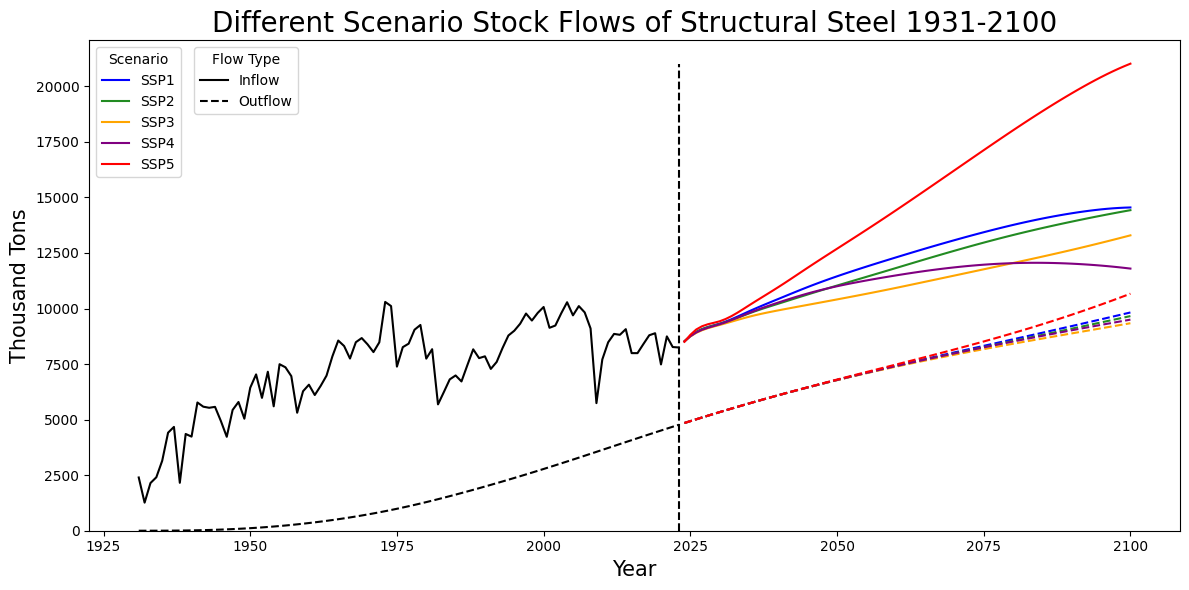

In [91]:
fig, ax = plt.subplots(figsize = (12,6))


ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color = 'black')
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color = 'blue')
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color = 'forestgreen')
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color = 'orange')
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color = 'purple')
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color = 'red')
ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color = 'black', ls = "--")
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color = 'blue', ls = "--")
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color = 'forestgreen', ls = "--")
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color = 'orange', ls = "--")
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color = 'purple', ls = "--")
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color = 'red', ls = "--")
ax.plot([2023,2023],[0,21000], color = 'k', linestyle = '--')
plt.xlabel('Year', fontsize = 15)
plt.ylabel('Thousand Tons',fontsize = 15)
plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100', fontsize = 20)
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

ax.set_ylim(0,)
ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor = (0.09,1))
plt.show()

Text(0.5, 1.0, 'Sample Example')

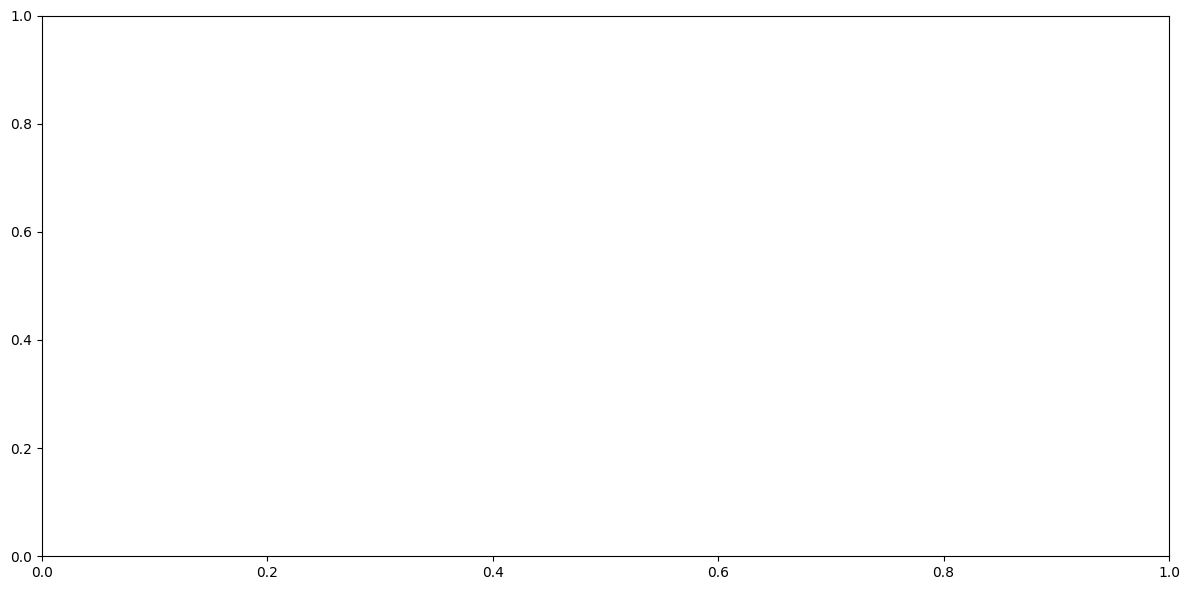

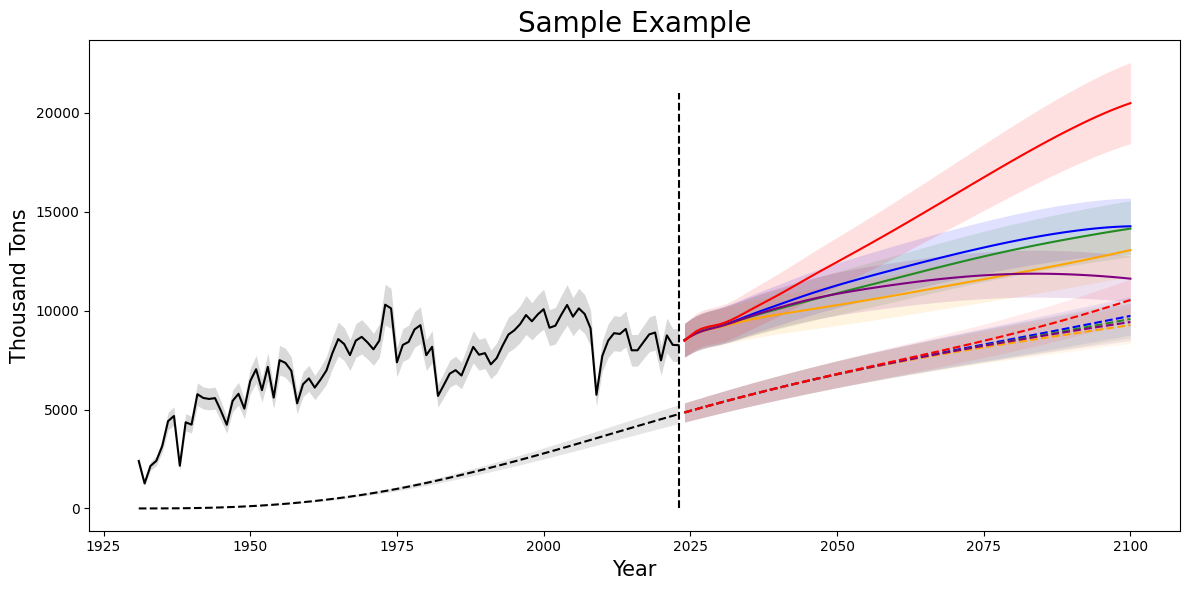

In [44]:
### DUMMY BANDS ####

def dummy_band(y, frac=0.10):
    y = np.asarray(y)
    low = np.clip(y * (1 - frac), 0, None)
    high = y * (1 + frac)
    return low, high

fig, ax = plt.subplots(figsize = (12,6))

def plot_with_dummy_band(ax, x, y, color, frac=0.10, alpha=0.12, **plot_kwargs):
    ax.plot(x, y, color=color, **plot_kwargs)
    low, high = dummy_band(y, frac=frac)
    ax.fill_between(x, low, high, color=color, alpha=alpha, linewidth=0)

fig, ax = plt.subplots(figsize=(12,6))

# SSP1 inflow
plot_with_dummy_band(ax, steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color='black', frac=0.10, alpha=0.15)
plot_with_dummy_band(ax, steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color='blue',  frac=0.10, alpha=0.12)

# SSP2–SSP5 inflow
plot_with_dummy_band(ax, steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color='forestgreen', frac=0.10, alpha=0.12)
plot_with_dummy_band(ax, steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color='orange',      frac=0.10, alpha=0.12)
plot_with_dummy_band(ax, steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color='purple',      frac=0.10, alpha=0.12)
plot_with_dummy_band(ax, steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color='red',         frac=0.10, alpha=0.12)

# SSP1 outflow (dashed)
plot_with_dummy_band(ax, steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color='black', frac=0.10, alpha=0.10, ls='--')
plot_with_dummy_band(ax, steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color='blue',  frac=0.10, alpha=0.08, ls='--')

# SSP2–SSP5 outflow (dashed)
plot_with_dummy_band(ax, steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color='forestgreen', frac=0.10, alpha=0.08, ls='--')
plot_with_dummy_band(ax, steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color='orange',      frac=0.10, alpha=0.08, ls='--')
plot_with_dummy_band(ax, steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color='purple',      frac=0.10, alpha=0.08, ls='--')
plot_with_dummy_band(ax, steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color='red',         frac=0.10, alpha=0.08, ls='--')

ax.plot([2023,2023],[0,21000], color='k', linestyle='--')

plt.xlabel('Year', fontsize=15)
plt.ylabel('Thousand Tons', fontsize=15)
plt.title('Sample Example', fontsize=20)

In [45]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [46]:
# fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)

# xcols = ['pop_ssp2', 'gdp_ssp2']

# for xcol, ax in zip(xcols, axes):
#     x = np.log(df_elasticities[xcol].loc[1931:2023])
#     y = np.log(df_steel['structural-total'].loc[1931:2023])
#     ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')
#     x1 = np.log(all_flows[xcols].loc[2024:2100])
#     ax.plot(x1, steel_DSM_ssp1.i[93:], color = 'blue')
#     ax.plot(x1, steel_DSM_ssp2.i[93:],color = 'forestgreen')
#     ax.plot(x1, steel_DSM_ssp3.i[93:],color = 'orange')
#     ax.plot(x1, steel_DSM_ssp4.i[93:],color = 'purple')
#     ax.plot(x1, steel_DSM_ssp5.i[93:],color = 'red')
#     ax.set_xlabel(xcol,fontsize = 9)
#     ax.set_ylabel('Structural Steel (kt)')
#     ax.grid(True, linestyle = '--', alpha = 0.3)


    
# scenario_handles = [
#     mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
#     mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
#     mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
#     mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
#     mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
# ]

# leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
# ax.add_artist(leg1)

# plt.show()

In [47]:
## Create Dataframe of Flows ssp1
total_inflows_ssp1 = steel_DSM_ssp1.i
total_outflows_ssp1 = steel_DSM_ssp1.o
years = steel_DSM_ssp1.t

total_flows = pd.DataFrame({"inflow_ssp1":total_inflows_ssp1, 'outflow_ssp1':total_outflows_ssp1}, index=years)



In [92]:
start_year = 1931
n_years = len(steel_DSM_ssp1.t)
years = np.arange(start_year, start_year + n_years)

# Build all SSP flow dataframes
flow_dfs = {}

for s in range(1, 6):   # SSP1–SSP5
    model = globals()[f"steel_DSM_ssp{s}"]   # get steel_DSM_ssp1, etc.

    df = pd.DataFrame({
        f"inflow_ssp{s}":  model.i,
        f"outflow_ssp{s}": model.o,
    }, index=years)

    df.index.name = "Year"

    flow_dfs[f"ssp{s}"] = df

all_flows = pd.concat(flow_dfs.values(), axis=1)

In [93]:
all_flows.loc[2024]

inflow_ssp1     8522.335504
outflow_ssp1    4848.730711
inflow_ssp2     8522.584699
outflow_ssp2    4848.730711
inflow_ssp3     8529.858514
outflow_ssp3    4848.730711
inflow_ssp4     8526.867583
outflow_ssp4    4848.730711
inflow_ssp5     8503.722992
outflow_ssp5    4848.730711
Name: 2024, dtype: float64

In [50]:
## ECCs
production_emissions = .898+.109
reuse_emissions = .109

Deconstruction / demolition emissions excluded, assumed to be the same for this. However, future versions of this model should note that deconstruction seemingly tends to have lower emissions associated with it

In [51]:
# total_flows['flows delta'] = total_flows['Total Inflow'] - total_flows['Total Outflow']
# total_flows['demand percentage'] = total_flows['Total Outflow'] / total_flows['Total Inflow']

In [94]:
all_flows['demand percentage_ssp1'] = all_flows['outflow_ssp1'] / all_flows['inflow_ssp1']
all_flows['demand percentage_ssp2'] = all_flows['outflow_ssp2'] / all_flows['inflow_ssp2']
all_flows['demand percentage_ssp3'] = all_flows['outflow_ssp3'] / all_flows['inflow_ssp3']
all_flows['demand percentage_ssp4'] = all_flows['outflow_ssp4'] / all_flows['inflow_ssp4']
all_flows['demand percentage_ssp5'] = all_flows['outflow_ssp5'] / all_flows['inflow_ssp5']


In [95]:
all_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5
Year,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14488.136793,9576.135461,14231.100943,9431.901240,13023.327638,9155.430387,11909.739051,9312.175139,20548.419477,10274.619955,0.660964,0.662767,0.703002,0.781896,0.500020
2097,14509.758840,9637.622512,14281.399071,9488.735330,13089.972737,9201.161115,11884.767213,9359.652173,20675.642745,10371.126041,0.664217,0.664412,0.702917,0.787533,0.501611
2098,14527.279917,9699.286227,14330.786455,9545.753564,13157.346662,9246.915032,11857.851342,9406.820366,20796.972289,10468.912800,0.667660,0.666101,0.702795,0.793299,0.503386


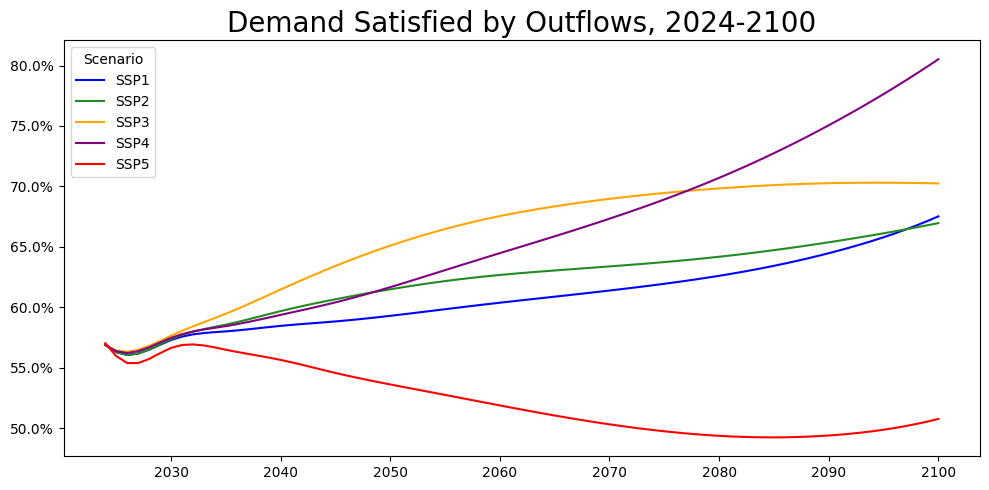

In [96]:
fig,ax = plt.subplots(figsize = (10,5))

years = all_flows.loc[2024:2100].index
ax.plot(years, all_flows['demand percentage_ssp1'].loc[2024:2100], color = 'blue')
ax.plot(years, all_flows['demand percentage_ssp2'].loc[2024:2100], color = 'forestgreen')
ax.plot(years, all_flows['demand percentage_ssp3'].loc[2024:2100], color = 'orange')
ax.plot(years, all_flows['demand percentage_ssp4'].loc[2024:2100], color = 'purple')
ax.plot(years, all_flows['demand percentage_ssp5'].loc[2024:2100], color = 'red')


plt.title('Demand Satisfied by Outflows, 2024-2100', fontsize = 20)
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')

In [55]:
# fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)

# xcols = ['pop_ssp2', 'gdp_ssp2']

# for xcol, ax in zip(xcols, axes):
#     x = np.log(df_elasticities[xcol].loc[1931:2023])
#     y = np.log(df_steel['structural-total'].loc[1931:2023])
#     ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')
#     x1 = np.log(all_flows[xcols].loc[2024:2100])
#     ax.plot(x1, steel_DSM_ssp1.i[93:], color = 'blue')
#     ax.plot(x1, steel_DSM_ssp2.i[93:],color = 'forestgreen')
#     ax.plot(x1, steel_DSM_ssp3.i[93:],color = 'orange')
#     ax.plot(x1, steel_DSM_ssp4.i[93:],color = 'purple')
#     ax.plot(x1, steel_DSM_ssp5.i[93:],color = 'red')
#     ax.set_xlabel(xcol,fontsize = 9)
#     ax.set_ylabel('Structural Steel (kt)')
#     ax.grid(True, linestyle = '--', alpha = 0.3)


    
# scenario_handles = [
#     mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
#     mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
#     mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
#     mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
#     mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
# ]

# leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
# ax.add_artist(leg1)

# plt.show()

In [56]:
## Add reuse emissions column
def get_emissions (df, outflows,emissions,output_name):
    df[output_name] = df[outflows].sum(axis=1)*emissions
    return df

In [57]:
total_flows = get_emissions(all_flows, ['outflow_ssp1'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp1')

total_flows = get_emissions(all_flows, ['outflow_ssp2'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp2')

total_flows = get_emissions(all_flows, ['outflow_ssp3'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp3')

total_flows = get_emissions(all_flows, ['outflow_ssp4'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp4')

total_flows = get_emissions(all_flows, ['outflow_ssp5'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp5')

In [58]:
total_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5,100% Reuse Emissions_ssp1,100% Reuse Emissions_ssp2,100% Reuse Emissions_ssp3,100% Reuse Emissions_ssp4,100% Reuse Emissions_ssp5
Year,,,,,,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086,0.011907,0.011907,0.011907,0.011907,0.011907
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218,0.051006,0.051006,0.051006,0.051006,0.051006
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452,0.118611,0.118611,0.118611,0.118611,0.118611
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655,0.224784,0.224784,0.224784,0.224784,0.224784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14201.622937,9493.936118,13953.868896,9354.909692,12795.676320,9091.417243,11719.438547,9241.104993,20028.385990,10159.761821,0.668511,0.670417,0.710507,0.788528,0.507268,1034.839037,1019.685156,990.964479,1007.280444,1107.414038
2097,14222.465173,9552.917646,14002.352993,9409.406196,12859.917825,9135.275727,11695.367333,9286.616504,20151.020878,10252.338274,0.671678,0.671988,0.710368,0.794042,0.508775,1041.268023,1025.625275,995.745054,1012.241199,1117.504872
2098,14239.354343,9612.052171,14049.959193,9464.062907,12924.861871,9179.138952,11669.422198,9331.812848,20267.974601,10346.132697,0.675034,0.673601,0.710192,0.799681,0.510467,1047.713687,1031.582857,1000.526146,1017.167600,1127.728464


In [59]:
total_flows = get_emissions(all_flows, ['outflow_ssp1'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp1')

total_flows = get_emissions(all_flows, ['outflow_ssp2'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp2')

total_flows = get_emissions(all_flows, ['outflow_ssp3'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp3')

total_flows = get_emissions(all_flows, ['outflow_ssp4'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp4')

total_flows = get_emissions(all_flows, ['outflow_ssp5'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp5')

In [60]:
total_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,...,100% Reuse Emissions_ssp1,100% Reuse Emissions_ssp2,100% Reuse Emissions_ssp3,100% Reuse Emissions_ssp4,100% Reuse Emissions_ssp5,100% Recycling Emissions_ssp1,100% Recycling Emissions_ssp2,100% Recycling Emissions_ssp3,100% Recycling Emissions_ssp4,100% Recycling Emissions_ssp5
Year,,,,,,,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,...,0.011907,0.011907,0.011907,0.011907,0.011907,0.110002,0.110002,0.110002,0.110002,0.110002
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,...,0.051006,0.051006,0.051006,0.051006,0.051006,0.471219,0.471219,0.471219,0.471219,0.471219
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,...,0.118611,0.118611,0.118611,0.118611,0.118611,1.095790,1.095790,1.095790,1.095790,1.095790
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,...,0.224784,0.224784,0.224784,0.224784,0.224784,2.076677,2.076677,2.076677,2.076677,2.076677
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14201.622937,9493.936118,13953.868896,9354.909692,12795.676320,9091.417243,11719.438547,9241.104993,20028.385990,10159.761821,...,1034.839037,1019.685156,990.964479,1007.280444,1107.414038,9560.393671,9420.394059,9155.057164,9305.792728,10230.880154
2097,14222.465173,9552.917646,14002.352993,9409.406196,12859.917825,9135.275727,11695.367333,9286.616504,20151.020878,10252.338274,...,1041.268023,1025.625275,995.745054,1012.241199,1117.504872,9619.788069,9475.272040,9199.222657,9351.622819,10324.104642
2098,14239.354343,9612.052171,14049.959193,9464.062907,12924.861871,9179.138952,11669.422198,9331.812848,20267.974601,10346.132697,...,1047.713687,1031.582857,1000.526146,1017.167600,1127.728464,9679.336536,9530.311347,9243.392925,9397.135538,10418.555626


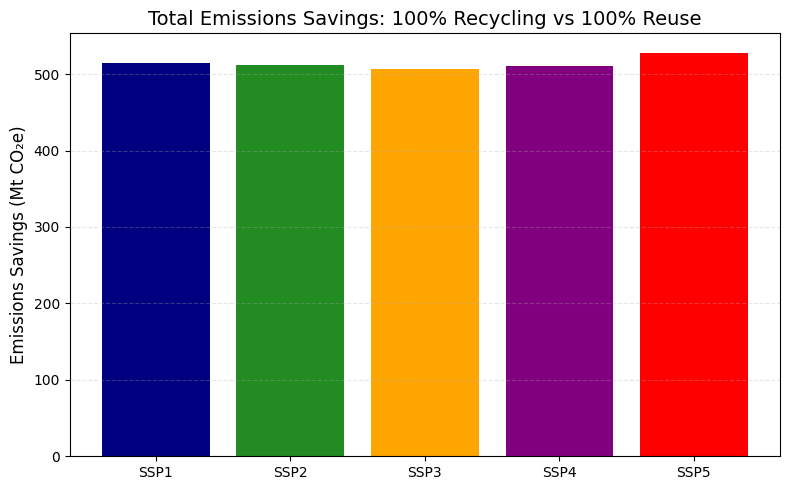

In [61]:
ssp1_savings = (total_flows['100% Recycling Emissions_ssp1'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp1'].loc[2024:2100].sum())/1e3
ssp2_savings = (total_flows['100% Recycling Emissions_ssp2'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp2'].loc[2024:2100].sum())/1e3
ssp3_savings = (total_flows['100% Recycling Emissions_ssp3'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp3'].loc[2024:2100].sum())/1e3
ssp4_savings = (total_flows['100% Recycling Emissions_ssp4'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp4'].loc[2024:2100].sum())/1e3
ssp5_savings = (total_flows['100% Recycling Emissions_ssp5'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp5'].loc[2024:2100].sum())/1e3

savings = [
    ssp1_savings,
    ssp2_savings,
    ssp3_savings,
    ssp4_savings,
    ssp5_savings
]

labels = ['SSP1', 'SSP2', 'SSP3', 'SSP4', 'SSP5']

plt.figure(figsize=(8,5))

plt.bar(labels, savings, color=[
    'navy', 'forestgreen', 'orange', 'purple', 'red'
])

plt.ylabel('Emissions Savings (Mt CO₂e)', fontsize=12)
plt.title('Total Emissions Savings: 100% Recycling vs 100% Reuse', fontsize=14)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

In [62]:
# fig,ax1 = plt.subplots(figsize = (10,5))

# years = total_flows.loc[2024:2100].index
# bar_vals = total_flows.loc[2024:2100, 'flows delta']

# bars = ax1.bar(years, bar_vals, label="Delta", alpha=0.6)
# ax1.set_xlabel("Year")
# ax1.set_ylabel("Difference between Inflows and Outflows", color='blue')
# ax1.tick_params(axis='y', labelcolor='blue')

# ax2 = ax1.twinx()

# line_vals = total_flows.loc[2024:2100, 'demand percentage']   # example second variable
# ax2.plot(years, line_vals, label="Percentage ", linewidth=2, color = 'red')
# ax2.set_ylabel("Percentage of Inflows Satisfied by Outflows", color='red')
# ax2.tick_params(axis='y', labelcolor='red')
# ax2.set_ylim(0,1)

# plt.title('Relationship between Inflows and Outflows')
# plt.show()

In [63]:
# plt1 = plt.bar(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, 'demand percentage'], color = 'goldenrod')
# plt.xlabel('Year') 
# plt.title('Percentage of Demand Satisfied by Outflows')
# plt.show()

In [64]:
# plt1 = plt.plot(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, '100% Reuse Emissions'])
# plt3 = plt.plot(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, '100% Recycling Emissions'])
# plt.xlabel('Year')
# plt.ylabel('kg CO2e')
# plt.title('Annual Emissions Of Different Scenarios')
# plt.legend([plt1,plt3], ['Reuse Emissions','Recycling Emissions'])
# plt.show()

In [65]:
# fig, ax = plt.subplots(2,3, sharey=True)

# ax[0,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']/1e3, color = 'firebrick')
# ax[0,0].set_title('0% Reuse')

# ax[0,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.8/1e3, color = 'firebrick')
# ax[0,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.2/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.8/1e3, color = 'goldenrod')
# ax[0,1].set_title('20% Reuse')

# ax[0,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.6/1e3, color = 'firebrick')
# ax[0,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.4/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.6/1e3, color = 'goldenrod')
# ax[0,2].set_title('40% Reuse')

# ax[1,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.4/1e3, color = 'firebrick')
# ax[1,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.6/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.4/1e3, color = 'goldenrod')
# ax[1,0].set_title('60% Reuse')

# ax[1,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.2/1e3, color = 'firebrick')
# ax[1,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.8/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.2/1e3, color = 'goldenrod')
# ax[1,1].set_title('80% Reuse')

# ax[1,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']/1e3,color = 'goldenrod')
# ax[1,2].set_title('100% Reuse')

# fig.suptitle('GWP of Steel Returning to Inflows at Different Reuse Rates')
# fig.text(0.001, 0.5, 'Megatons CO2e', ha='center', va='center', rotation = 'vertical', fontsize =12)

In [66]:
# total_flows['100% Recycling Emissions'].sum() - total_flows['100% Reuse Emissions'].sum()

In [67]:
pop_proj = pop_fore.to_frame()
population = pd.concat([df_population,pop_proj],axis=0)

In [68]:
population = population.iloc[31:201,:]

In [69]:
population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1962,1.865377e+08,186537737.0,186537737.0,186537737.0,186537737.0,U.S. Censusu Bureau
1963,1.892418e+08,189241798.0,189241798.0,189241798.0,189241798.0,U.S. Censusu Bureau
1964,1.918888e+08,191888791.0,191888791.0,191888791.0,191888791.0,U.S. Censusu Bureau
1965,1.943030e+08,194302963.0,194302963.0,194302963.0,194302963.0,U.S. Censusu Bureau
1966,1.965603e+08,196560338.0,196560338.0,196560338.0,196560338.0,U.S. Censusu Bureau
...,...,...,...,...,...,...
2050,3.761465e+08,NaN,NaN,NaN,NaN,NaN
2051,3.771170e+08,NaN,NaN,NaN,NaN,NaN
2052,3.780288e+08,NaN,NaN,NaN,NaN,NaN
2053,3.788892e+08,NaN,NaN,NaN,NaN,NaN


In [70]:
gdp_proj = pd.concat([df_gdp_SSP2,gdp_fore.to_frame()],axis=0)

In [71]:
gdp_proj = gdp_proj.iloc[0:170]

In [72]:
GFA_proj = 0.61 * (gdp_fore ** gdp_elast)* (pop_fore ** pop_elast) 


In [73]:
gfa_forecast = pd.DataFrame({
    "Total U.S. floor space (million sq ft)": GFA_proj,
}, index=forecast_years)

In [74]:
# gfa = pd.concat([df_floorspace,gfa_forecast], axis=0)

In [75]:
for name, obj in {
    "population": population,
    "gdp_proj": gdp_proj,
    "MFA_Data_Total": MFA_Data_Total,
}.items():
    print(name, "index is unique?", obj.index.is_unique)

population index is unique? False
gdp_proj index is unique? True
MFA_Data_Total index is unique? True


In [76]:
population_ssp2     = df_population['pop_ssp2']
gdp_proj_ssp2       = df_gdp['gdp_ssp2']
MFA_Data_Total_ssp2 = all_flows['inflow_ssp2']

df_normal = pd.concat([population_ssp2, gdp_proj_ssp2, MFA_Data_Total_ssp2], axis=1)


In [77]:
gdp_proj_ssp2

1931      9931.000000
1932      8381.000000
1933      8048.000000
1934      8667.000000
1935      9681.000000
            ...      
2096    119845.660276
2097    120715.274883
2098    121587.065352
2099    122460.443214
2100    123334.820000
Name: gdp_ssp2, Length: 170, dtype: float64

In [78]:
df_normal

,pop_ssp2,gdp_ssp2,inflow_ssp2
1931,1.240396e+08,9931.000000,2396.480000
1932,1.248405e+08,8381.000000,1263.680000
1933,1.255788e+08,8048.000000,2145.890000
1934,1.263738e+08,8667.000000,2406.640000
1935,1.272502e+08,9681.000000,3149.100000
...,...,...,...
2096,4.062801e+08,119845.660276,13953.868896
2097,4.061230e+08,120715.274883,14002.352993
2098,4.059405e+08,121587.065352,14049.959193
2099,4.057335e+08,122460.443214,14096.668125


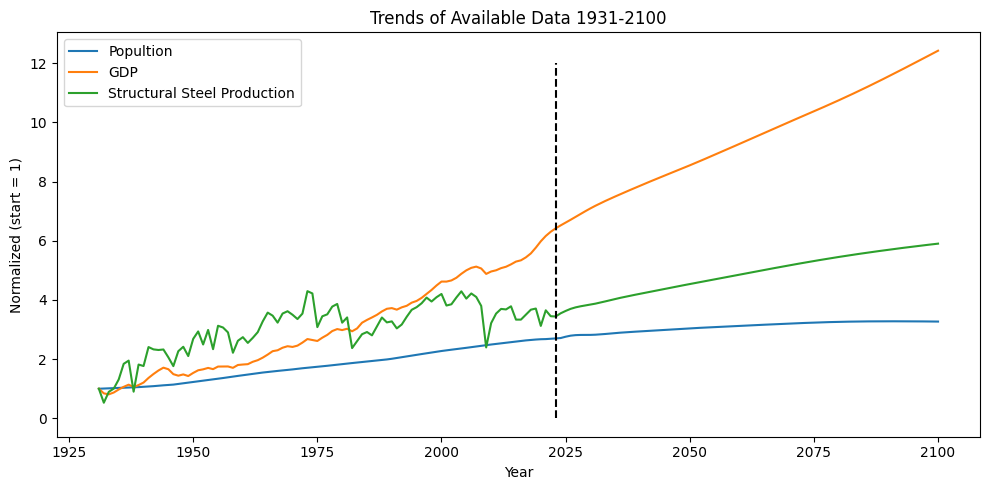

In [79]:
cols = ['pop_ssp2', 'gdp_ssp2','inflow_ssp2']

years = df_normal.index

labels = {'pop_ssp2': 'Popultion',
           'gdp_ssp2':'GDP',
           'inflow_ssp2':'Structural Steel Production'}

plt.figure(figsize=(10,5))

for col in cols:
    norm = df_normal[col] / df_normal[col].iloc[0]
    plt.plot(years, norm, label=labels[col])

plt.ylabel("Normalized (start = 1)")
plt.xlabel("Year")
plt.plot([2023,2023],[0,12], color = 'k', linestyle = '--')
plt.title("Trends of Available Data 1931-2100")
plt.legend()
plt.show()

In [80]:
df_normal

,pop_ssp2,gdp_ssp2,inflow_ssp2
1931,1.240396e+08,9931.000000,2396.480000
1932,1.248405e+08,8381.000000,1263.680000
1933,1.255788e+08,8048.000000,2145.890000
1934,1.263738e+08,8667.000000,2406.640000
1935,1.272502e+08,9681.000000,3149.100000
...,...,...,...
2096,4.062801e+08,119845.660276,13953.868896
2097,4.061230e+08,120715.274883,14002.352993
2098,4.059405e+08,121587.065352,14049.959193
2099,4.057335e+08,122460.443214,14096.668125


## Make simple sankey for 2019

In [81]:
df_recycling

,scrap,Exports,Imports
1998,73000,5950,3370
1999,71000,5560,4020
2000,74000,5810,3630
2001,71000,7530,2810
2002,69000,9000,3320
2003,65000,10900,3690
2004,66600,11800,4790
2005,65600,13000,4000
2006,65300,14100,5000
2007,65000,16700,3780


In [82]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [83]:
outflow = all_flows['outflow_ssp1'].loc[2019]*.98
waste = all_flows['outflow_ssp1'].loc[2019]*.02
inflow = all_flows['inflow_ssp1'].loc[2019]
scrap = df_recycling['scrap'].loc[2019]+df_recycling['Exports'].loc[2019]-df_recycling['Imports'].loc[2019] - outflow
virgin = 32000
other_use = scrap + virgin - inflow
inflow_reuse = inflow - outflow
other_reuse = scrap + virgin - inflow_reuse

In [84]:
outflow

np.float64(4335.319203568618)

In [85]:
import plotly.io as pio
pio.renderers.default = "browser"

In [86]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","Construction Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,1,8],
        "value" : [virgin,scrap,inflow,inflow,inflow,outflow,waste,outflow,other_use]
    }

))

fig.show()

In [87]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","structural Steel Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,4,8],
        "value" : [virgin,scrap,inflow_reuse,inflow_reuse,inflow,outflow,waste,outflow,other_reuse]
    }

))

fig.show()

## Rough Stock-Driven Validation

In [98]:
df_buildings = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\total_buildings_actual.csv', index_col=0)


In [99]:
df_buildings

,Number of Buildings (Thousands),Gross Floor Area (Millions sf)
1999,4657.0,67338.0
2003,4859.0,71658.0
2012,5557.0,87094.0
2018,5919.0,96422.0


In [100]:
steel_buildings = df_buildings
steel_buildings['Steel Buildings (Thousands)'] = df_buildings['Number of Buildings (Thousands)']*0.65
steel_buildings['Steel GFA (Millions sf)'] = df_buildings['Gross Floor Area (Millions sf)']*0.65


In [101]:
steel_buildings

,Number of Buildings (Thousands),Gross Floor Area (Millions sf),Steel Buildings (Thousands),Steel GFA (Millions sf)
1999,4657.0,67338.0,3027.05,43769.7
2003,4859.0,71658.0,3158.35,46577.7
2012,5557.0,87094.0,3612.05,56611.1
2018,5919.0,96422.0,3847.35,62674.3


In [102]:
steel_GFA = steel_buildings['Steel GFA (Millions sf)']*1e6 

In [103]:
steel_GFA = steel_GFA/10.7639

In [104]:
steel_GFA = pd.DataFrame(steel_GFA)

In [105]:
steel_GFA

,Steel GFA (Millions sf)
1999,4.066342e+09
2003,4.327214e+09
2012,5.259348e+09
2018,5.822639e+09


In [106]:
steel_MI_avg = 68
steel_MI_std= 15

steel_GFA['kg steel mid'] = steel_GFA['Steel GFA (Millions sf)']*68
steel_GFA['kg steel upper'] = steel_GFA['Steel GFA (Millions sf)']*83
steel_GFA['kg steel lower'] = steel_GFA['Steel GFA (Millions sf)']*53

In [107]:
steel_GFA = pd.DataFrame(steel_GFA)

In [108]:
steel_GFA

,Steel GFA (Millions sf),kg steel mid,kg steel upper,kg steel lower
1999,4.066342e+09,2.765113e+11,3.375064e+11,2.155161e+11
2003,4.327214e+09,2.942506e+11,3.591588e+11,2.293423e+11
2012,5.259348e+09,3.576357e+11,4.365259e+11,2.787455e+11
2018,5.822639e+09,3.959394e+11,4.832790e+11,3.085998e+11


In [109]:
steel_GFA['thousand tons steel lower'] = steel_GFA['kg steel lower']/1e6
steel_GFA['thousand tons steel upper'] = steel_GFA['kg steel upper']/1e6
steel_GFA['thousand tons steel mid'] = steel_GFA['kg steel mid']/1e6

tons_steel = steel_GFA.drop(columns = ['Steel GFA (Millions sf)','kg steel lower','kg steel mid','kg steel upper'])

In [110]:
tons_steel

,thousand tons steel lower,thousand tons steel upper,thousand tons steel mid
1999,215516.132629,337506.396380,276511.264505
2003,229342.348034,359158.771449,294250.559741
2012,278745.464005,436525.915328,357635.689666
2018,308599.847639,483279.006680,395939.427159


In [111]:
all_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5
Year,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14488.136793,9576.135461,14231.100943,9431.901240,13023.327638,9155.430387,11909.739051,9312.175139,20548.419477,10274.619955,0.660964,0.662767,0.703002,0.781896,0.500020
2097,14509.758840,9637.622512,14281.399071,9488.735330,13089.972737,9201.161115,11884.767213,9359.652173,20675.642745,10371.126041,0.664217,0.664412,0.702917,0.787533,0.501611
2098,14527.279917,9699.286227,14330.786455,9545.753564,13157.346662,9246.915032,11857.851342,9406.820366,20796.972289,10468.912800,0.667660,0.666101,0.702795,0.793299,0.503386


In [112]:
def stock_accumulation(df,ssps):
    '''
    ssps = {
    'out_col1': ('colA','colB'),
    'out_col1': ('colC','colD')}
    ...
    }
    ''' 

    df = df.copy()

    for out_col, (c1, c2) in ssps.items():
        df[out_col] = (df[c1] - df[c2]).cumsum()

    return df

In [113]:
ssps = {
    'stock_ssp1':('inflow_ssp1','outflow_ssp1'),
    'stock_ssp2':('inflow_ssp2','outflow_ssp2'),
    'stock_ssp3':('inflow_ssp3','outflow_ssp3'),
    'stock_ssp4':('inflow_ssp4','outflow_ssp4'),
    'stock_ssp5':('inflow_ssp1','outflow_ssp5'),
}

all_flows = stock_accumulation(all_flows,ssps)

In [114]:
all_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5,stock_ssp1,stock_ssp2,stock_ssp3,stock_ssp4,stock_ssp5
Year,,,,,,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2396.480000,2396.480000,2396.480000,2396.480000,2396.480000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086,3660.050763,3660.050763,3660.050763,3660.050763,3660.050763
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218,5805.472819,5805.472819,5805.472819,5805.472819,5805.472819
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452,8211.024647,8211.024647,8211.024647,8211.024647,8211.024647
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655,11358.062405,11358.062405,11358.062405,11358.062405,11358.062405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14488.136793,9576.135461,14231.100943,9431.901240,13023.327638,9155.430387,11909.739051,9312.175139,20548.419477,10274.619955,0.660964,0.662767,0.703002,0.781896,0.500020,874752.371750,852911.511150,800825.162710,808114.495869,863650.856674
2097,14509.758840,9637.622512,14281.399071,9488.735330,13089.972737,9201.161115,11884.767213,9359.652173,20675.642745,10371.126041,0.664217,0.664412,0.702917,0.787533,0.501611,879624.508078,857704.174891,804713.974331,810639.610909,867789.489473
2098,14527.279917,9699.286227,14330.786455,9545.753564,13157.346662,9246.915032,11857.851342,9406.820366,20796.972289,10468.912800,0.667660,0.666101,0.702795,0.793299,0.503386,884452.501769,862489.207782,808624.405962,813090.641885,871847.856591


In [115]:
all_flows['stock_ssp1'].loc[2018]

np.float64(511940.1635190111)

In [116]:
inflow_stock_comp = {'inflow stock' : [all_flows['stock_ssp1'].loc[1999],
                                       all_flows['stock_ssp1'].loc[2003],
                                       all_flows['stock_ssp1'].loc[2012],
                                       all_flows['stock_ssp1'].loc[2018]]}

inflow_stock_comp = pd.DataFrame(inflow_stock_comp)                    

In [117]:
inflow_stock_comp

,inflow stock
0,410351.231121
1,436954.337709
2,485586.572781
3,511940.163519


C:\Users\aorga\AppData\Local\Temp\ipykernel_64788\1568281055.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(tons_steel.index, rotation = 45)


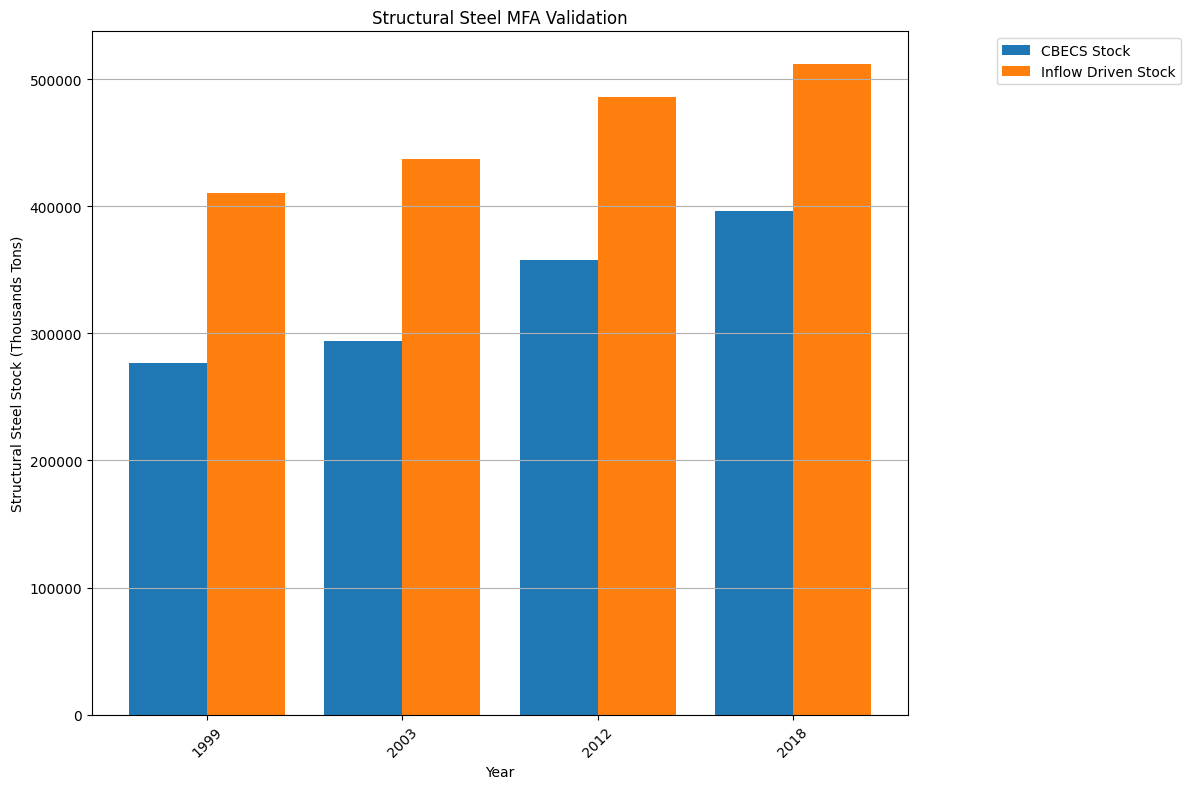

In [118]:
fig, ax = plt.subplots()

x = np.arange(len(steel_GFA))
width = 0.4

# Left axis bars
bars1 = ax.bar(x - width/2, tons_steel['thousand tons steel mid'], width,
               label='CBECS Stock', color='tab:blue')

# Right axis bars
bars2 = ax.bar(x + width/2, inflow_stock_comp['inflow stock'], width,
                label='Inflow Driven Stock', color='tab:orange')

# Labels & grid
ax.set_xlabel("Year")
ax.set_xticklabels(tons_steel.index, rotation = 45)
ax.set_title("Structural Steel MFA Validation")
ax.set_ylabel('Structural Steel Stock (Thousands Tons)')
ax.set_xticks(x)
ax.set_xticklabels(tons_steel.index)
ax.grid(True, axis='y')

# Combine legends manually
lines = [bars1, bars2]
labels = [b.get_label() for b in lines]
ax.legend(lines, labels, bbox_to_anchor=(1.1, 1))


In [119]:
delta_1999 = all_flows['stock_ssp1'].loc[1999]-tons_steel['thousand tons steel mid'].loc[1999]
delta_2003 = all_flows['stock_ssp1'].loc[2003]-tons_steel['thousand tons steel mid'].loc[2003]
delta_2012 = all_flows['stock_ssp1'].loc[2012]-tons_steel['thousand tons steel mid'].loc[2012]
delta_2018 = all_flows['stock_ssp1'].loc[2018]-tons_steel['thousand tons steel mid'].loc[2018]


In [120]:
difference = {'CBECS Stock': [tons_steel['thousand tons steel mid'].loc[1999],
                              tons_steel['thousand tons steel mid'].loc[2003],
                              tons_steel['thousand tons steel mid'].loc[2012],
                              tons_steel['thousand tons steel mid'].loc[2018]],
              'Inflow Driven stock' : [all_flows['stock_ssp1'].loc[1999],
                                       all_flows['stock_ssp1'].loc[2003],
                                       all_flows['stock_ssp1'].loc[2012],
                                       all_flows['stock_ssp1'].loc[2018]],
              'Delta (thousand tons)' : [delta_1999,delta_2003,delta_2012,delta_2018]}

index = tons_steel.index

df_stocks = pd.DataFrame(difference, index=index)

In [121]:
df_stocks

,CBECS Stock,Inflow Driven stock,Delta (thousand tons)
1999,276511.264505,410351.231121,133839.966616
2003,294250.559741,436954.337709,142703.777967
2012,357635.689666,485586.572781,127950.883115
2018,395939.427159,511940.163519,116000.736360


In [122]:
df_stocks['delta (percentage)'] = df_stocks['Delta (thousand tons)'] / ((df_stocks['Inflow Driven stock']+df_stocks['CBECS Stock'])/2)

In [123]:
df_stocks


,CBECS Stock,Inflow Driven stock,Delta (thousand tons),delta (percentage)
1999,276511.264505,410351.231121,133839.966616,0.389714
2003,294250.559741,436954.337709,142703.777967,0.390325
2012,357635.689666,485586.572781,127950.883115,0.303481
2018,395939.427159,511940.163519,116000.736360,0.255542


In [124]:
MUIS = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Material_data.xlsx', sheet_name='Steel_MI', usecols=['Steel_kgm2'])

In [125]:
MUIS

,Steel_kgm2
0,49.277204
1,71.145388
2,44.803057
3,71.798490
4,83.558017
...,...
3107,102.154526
3108,67.974600
3109,15.009278
3110,82.983878


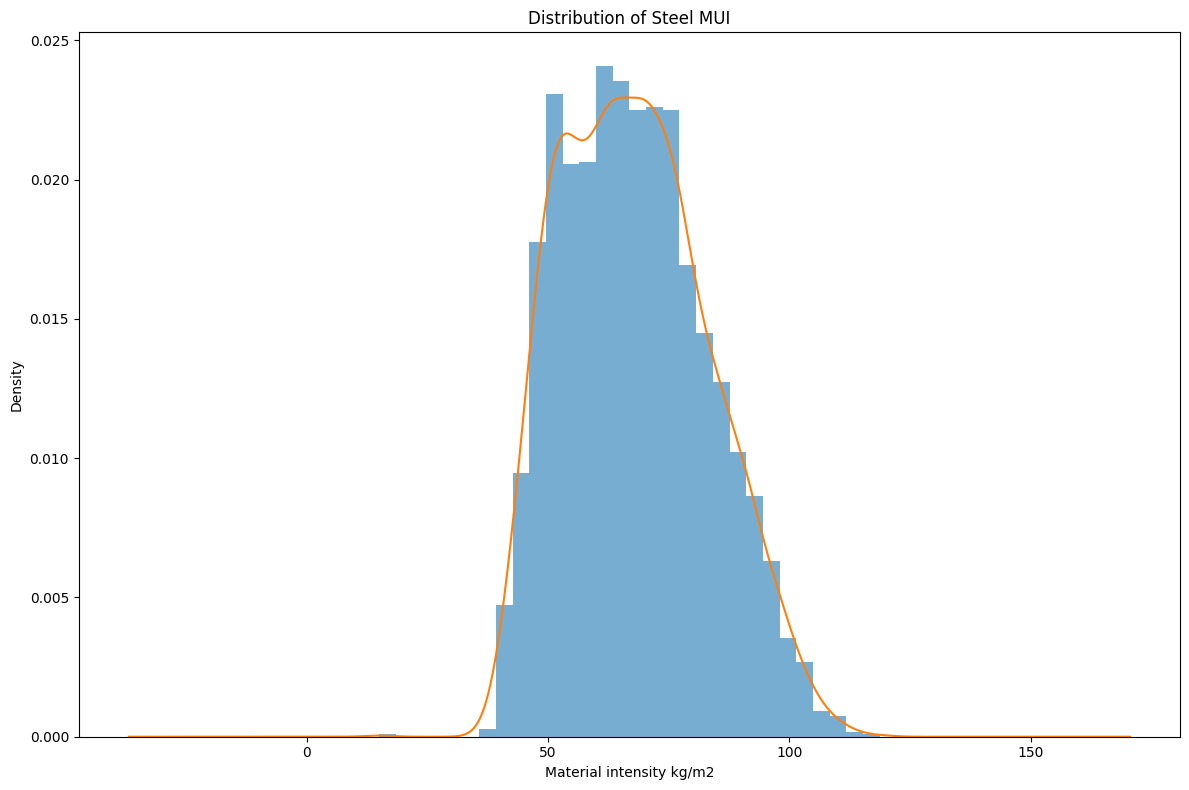

In [126]:
s = pd.Series(MUIS.squeeze())

plt.figure()
s.plot(kind="hist", bins=30, density=True, alpha=0.6)
s.plot(kind="kde")
plt.xlabel("Material intensity kg/m2")
plt.title("Distribution of Steel MUI")
plt.show()

In [127]:
GFA = pd.DataFrame(steel_GFA['Steel GFA (Millions sf)']).T

In [128]:
GFA

,1999,2003,2012,2018
Steel GFA (Millions sf),4.066342e+09,4.327214e+09,5.259348e+09,5.822639e+09


In [129]:
MUIS.mean(axis=0)

Steel_kgm2    67.95758
dtype: float64

In [130]:
MUI_dists = pd.DataFrame(
    MUIS.values @ GFA.values,
    columns=GFA.columns
)

In [131]:
MUI_dists

,1999,2003,2012,2018
0,2.003780e+11,2.132330e+11,2.591660e+11,2.869234e+11
1,2.893015e+11,3.078613e+11,3.741784e+11,4.142539e+11
2,1.821846e+11,1.938724e+11,2.356349e+11,2.608720e+11
3,2.919572e+11,3.106874e+11,3.776133e+11,4.180567e+11
4,3.397755e+11,3.615734e+11,4.394607e+11,4.865281e+11
...,...,...,...,...
3107,4.153953e+11,4.420445e+11,5.372662e+11,5.948089e+11
3108,2.764080e+11,2.941406e+11,3.575021e+11,3.957915e+11
3109,6.103286e+10,6.494836e+10,7.893902e+10,8.739360e+10
3110,3.374408e+11,3.590890e+11,4.364411e+11,4.831851e+11


In [132]:
MUI_dists = MUI_dists/1e6

In [133]:
MUI_dists

,1999,2003,2012,2018
0,200377.970987,213233.013232,259165.983622,286923.352617
1,289301.489563,307861.328508,374178.382666,414253.886760
2,182184.559176,193872.421834,235634.886645,260872.012309
3,291957.222916,310687.437698,377613.269961,418056.659657
4,339775.485791,361573.431952,439460.722912,486528.139994
...,...,...,...,...
3107,415395.253434,442044.507864,537266.241981,594808.891363
3108,276407.980232,294140.649373,357502.103275,395791.533309
3109,61032.860377,64948.360642,78939.023162,87393.603364
3110,337440.840610,359089.010015,436441.126437,483185.136672


In [134]:
MUI_dists.mean()

1999    276338.772289
2003    294067.001465
2012    357412.590717
2018    395692.433717
dtype: float64

In [135]:
stock_proj = df_stocks.drop(columns = ['Delta (thousand tons)', 'delta (percentage)'])

In [136]:
stock_proj = stock_proj.T

In [137]:
stock_proj

,1999,2003,2012,2018
CBECS Stock,276511.264505,294250.559741,357635.689666,395939.427159
Inflow Driven stock,410351.231121,436954.337709,485586.572781,511940.163519


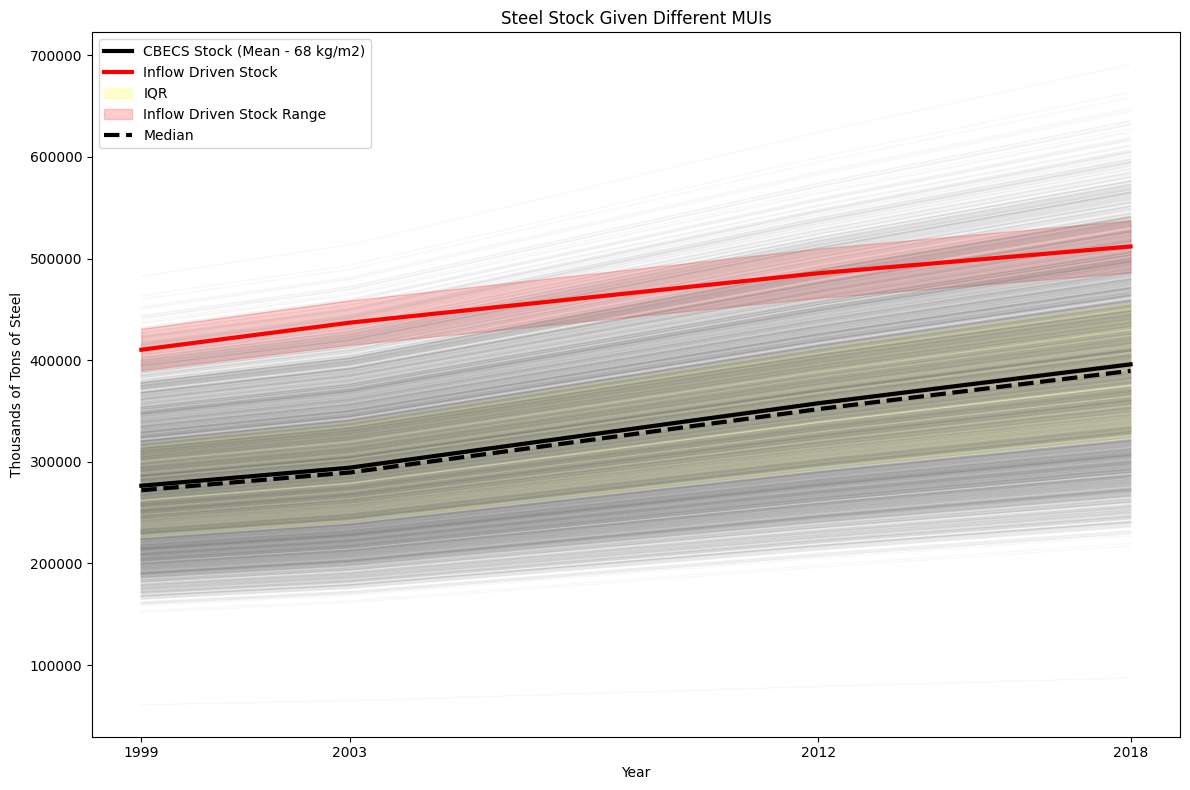

In [143]:
years = MUI_dists.columns
mean_line = MUI_dists.mean(axis=0)
q1 = MUI_dists.quantile(0.25, axis=0)
q3 = MUI_dists.quantile(0.75, axis=0)
median_line = MUI_dists.median(axis=0)

plt.plot(
    years,
    MUI_dists.values.T,
    alpha=0.05,
    linewidth=1,
    color = 'gray'
)

plt.plot(
    years,
    stock_proj.iloc[0].values,
    linewidth=3,
    color="black",
    label="CBECS Stock (Mean - 68 kg/m2)",
    zorder = 3
)


plt.plot(
    years,
    stock_proj.iloc[1].values,
    linewidth=3,
    color="red",
    label="Inflow Driven Stock",
    zorder = 3
)

plt.fill_between(years, q1.values, q3.values, color = 'yellow', alpha=0.2, label = "IQR")

plt.fill_between(
    years,
    stock_proj.iloc[1].values * 0.95,  # lower bound: -15%
    stock_proj.iloc[1].values * 1.05,  # upper bound: +15%
    color="red",
    alpha=0.2,
    label="Inflow Driven Stock Range"
)

plt.plot(years,
    median_line.values,
    linewidth=3,
    color = 'black',
    linestyle = '--',
    label = 'Median')


plt.xlabel("Year")
plt.xticks(years)
plt.ylabel("Thousands of Tons of Steel")
plt.title("Steel Stock Given Different MUIs")
plt.legend()
plt.show()

## Projections of different building types and building sizes 

### Sizes

In [139]:
sizes_pct_range = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\size_pct_range.csv', index_col=0)

In [140]:
sizes_pct_range


,low,mean,high
"5,001 to 10,000 Square Feet",19.51,22.1075,23.84
"10,001 to 25,000 Square Feet",15.20,16.0875,16.67
"25,001 to 50,000 Square Feet",5.37,5.8450,6.52
"50,001 to 100,000 Square Feet",3.03,3.3500,3.68
"100,001 to 200,000 Square Feet",1.27,1.4950,1.62
"200,001 to 500,000 Square Feet",0.49,0.5975,0.68
"Over 500,000 Square Feet",0.14,0.1500,0.16


In [141]:
def apply_percentages(df_ts, df_pct):
    df_pct = df_pct/100
    pct = df_pct
    scenario_frames = []
    
    for scenario_name, multiplier in pct.items():
        scaled = df_ts * multiplier
        scaled = scaled.add_suffix(f"_{scenario_name}")
        scenario_frames.append(scaled)
    
    result = pd.concat(scenario_frames, axis=1)
    return result 

In [142]:
df_5001_10000 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[0])
df_10001_25000 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[1])
df_25001_50000 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[2])
df_50001_100000 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[3])
df_100001_250001 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[4])
df_250001_500000 = apply_percentages(total_flows.iloc[:,0:10],sizes_pct_range.iloc[5])

NameError: name 'total_flows' is not defined

In [ ]:
df_5001_10000.iloc[93:,10]

Year
2024     8503.632389
2025     8695.374187
2026     8863.970291
2027     8984.564518
2028     9073.009697
            ...     
2096    14201.622937
2097    14222.465173
2098    14239.354343
2099    14252.025468
2100    14260.210080
Name: inflow_ssp1_mean, Length: 77, dtype: float64

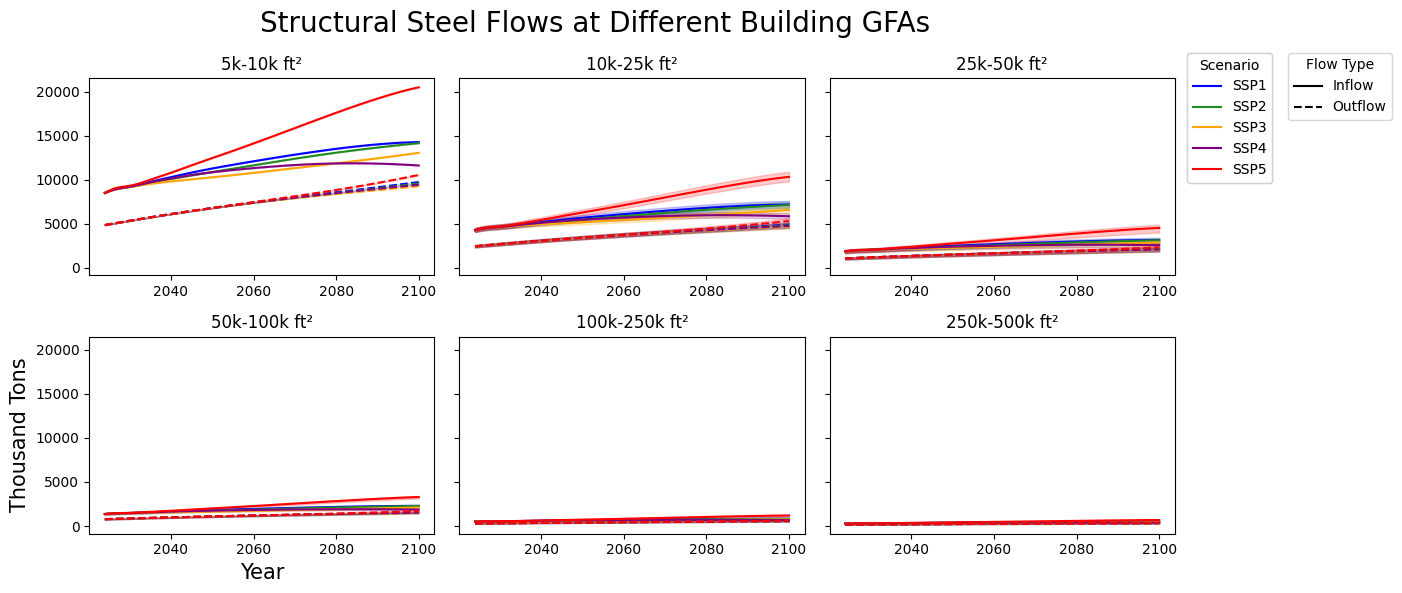

In [ ]:
years  = pd.Index(range(2024, 2101), name="Year")

fig, ax = plt.subplots(nrows = 2, ncols = 3, sharey = True, figsize = (12,6))

ax[0,0].plot(df_5001_10000.iloc[93:,10], color = 'blue')
ax[0,0].plot(df_5001_10000.iloc[93:,12], color = 'forestgreen')
ax[0,0].plot(df_5001_10000.iloc[93:,14], color = 'orange')
ax[0,0].plot(df_5001_10000.iloc[93:,16], color = 'purple')
ax[0,0].plot(df_5001_10000.iloc[93:,18], color = 'red')
ax[0,0].plot(df_5001_10000.iloc[93:,11], color = 'blue', ls = "--")
ax[0,0].plot(df_5001_10000.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,0].plot(df_5001_10000.iloc[93:,15], color = 'orange', ls = "--")
ax[0,0].plot(df_5001_10000.iloc[93:,17], color = 'purple', ls = "--")
ax[0,0].plot(df_5001_10000.iloc[93:,19], color = 'red', ls = "--")
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,0], df_5001_10000.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,2], df_5001_10000.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,4], df_5001_10000.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,6], df_5001_10000.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,8], df_5001_10000.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,1], df_5001_10000.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,3], df_5001_10000.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,5], df_5001_10000.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,7], df_5001_10000.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,0].fill_between(years, df_5001_10000.iloc[93:,9], df_5001_10000.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,0].set_title('5k-10k ft\u00b2')

ax[0,1].plot(df_10001_25000.iloc[93:,10], color = 'blue')
ax[0,1].plot(df_10001_25000.iloc[93:,12], color = 'forestgreen')
ax[0,1].plot(df_10001_25000.iloc[93:,14], color = 'orange')
ax[0,1].plot(df_10001_25000.iloc[93:,16], color = 'purple')
ax[0,1].plot(df_10001_25000.iloc[93:,18], color = 'red')
ax[0,1].plot(df_10001_25000.iloc[93:,11], color = 'blue', ls = "--")
ax[0,1].plot(df_10001_25000.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,1].plot(df_10001_25000.iloc[93:,15], color = 'orange', ls = "--")
ax[0,1].plot(df_10001_25000.iloc[93:,17], color = 'purple', ls = "--")
ax[0,1].plot(df_10001_25000.iloc[93:,19], color = 'red', ls = "--")
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,0], df_10001_25000.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,2], df_10001_25000.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,4], df_10001_25000.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,6], df_10001_25000.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,8], df_10001_25000.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,1], df_10001_25000.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,3], df_10001_25000.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,5], df_10001_25000.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,7], df_10001_25000.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,1].fill_between(years, df_10001_25000.iloc[93:,9], df_10001_25000.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,1].set_title('10k-25k ft\u00b2')

ax[0,2].plot(df_25001_50000.iloc[93:,10], color = 'blue')
ax[0,2].plot(df_25001_50000.iloc[93:,12], color = 'forestgreen')
ax[0,2].plot(df_25001_50000.iloc[93:,14], color = 'orange')
ax[0,2].plot(df_25001_50000.iloc[93:,16], color = 'purple')
ax[0,2].plot(df_25001_50000.iloc[93:,18], color = 'red')
ax[0,2].plot(df_25001_50000.iloc[93:,11], color = 'blue', ls = "--")
ax[0,2].plot(df_25001_50000.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,2].plot(df_25001_50000.iloc[93:,15], color = 'orange', ls = "--")
ax[0,2].plot(df_25001_50000.iloc[93:,17], color = 'purple', ls = "--")
ax[0,2].plot(df_25001_50000.iloc[93:,19], color = 'red', ls = "--")
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,0], df_25001_50000.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,2], df_25001_50000.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,4], df_25001_50000.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,6], df_25001_50000.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,8], df_25001_50000.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,1], df_25001_50000.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,3], df_25001_50000.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,5], df_25001_50000.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,7], df_25001_50000.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,2].fill_between(years, df_25001_50000.iloc[93:,9], df_25001_50000.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,2].set_title('25k-50k ft\u00b2')

ax[1,0].plot(df_50001_100000.iloc[93:,10], color = 'blue')
ax[1,0].plot(df_50001_100000.iloc[93:,12], color = 'forestgreen')
ax[1,0].plot(df_50001_100000.iloc[93:,14], color = 'orange')
ax[1,0].plot(df_50001_100000.iloc[93:,16], color = 'purple')
ax[1,0].plot(df_50001_100000.iloc[93:,18], color = 'red')
ax[1,0].plot(df_50001_100000.iloc[93:,11], color = 'blue', ls = "--")
ax[1,0].plot(df_50001_100000.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,0].plot(df_50001_100000.iloc[93:,15], color = 'orange', ls = "--")
ax[1,0].plot(df_50001_100000.iloc[93:,17], color = 'purple', ls = "--")
ax[1,0].plot(df_50001_100000.iloc[93:,19], color = 'red', ls = "--")
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,0], df_50001_100000.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,2], df_50001_100000.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,4], df_50001_100000.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,6], df_50001_100000.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,8], df_50001_100000.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,1], df_50001_100000.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,3], df_50001_100000.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,5], df_50001_100000.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,7], df_50001_100000.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,0].fill_between(years, df_50001_100000.iloc[93:,9], df_50001_100000.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,0].set_title('50k-100k ft\u00b2')

ax[1,1].plot(df_100001_250001.iloc[93:,10], color = 'blue')
ax[1,1].plot(df_100001_250001.iloc[93:,12], color = 'forestgreen')
ax[1,1].plot(df_100001_250001.iloc[93:,14], color = 'orange')
ax[1,1].plot(df_100001_250001.iloc[93:,16], color = 'purple')
ax[1,1].plot(df_100001_250001.iloc[93:,18], color = 'red')
ax[1,1].plot(df_100001_250001.iloc[93:,11], color = 'blue', ls = "--")
ax[1,1].plot(df_100001_250001.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,1].plot(df_100001_250001.iloc[93:,15], color = 'orange', ls = "--")
ax[1,1].plot(df_100001_250001.iloc[93:,17], color = 'purple', ls = "--")
ax[1,1].plot(df_100001_250001.iloc[93:,19], color = 'red', ls = "--")
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,0], df_100001_250001.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,2], df_100001_250001.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,4], df_100001_250001.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,6], df_100001_250001.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,8], df_100001_250001.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,1], df_100001_250001.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,3], df_100001_250001.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,5], df_100001_250001.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,7], df_100001_250001.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,1].fill_between(years, df_100001_250001.iloc[93:,9], df_100001_250001.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,1].set_title('100k-250k ft\u00b2')

ax[1,2].plot(df_250001_500000.iloc[93:,10], color = 'blue')
ax[1,2].plot(df_250001_500000.iloc[93:,12], color = 'forestgreen')
ax[1,2].plot(df_250001_500000.iloc[93:,14], color = 'orange')
ax[1,2].plot(df_250001_500000.iloc[93:,16], color = 'purple')
ax[1,2].plot(df_250001_500000.iloc[93:,18], color = 'red')
ax[1,2].plot(df_250001_500000.iloc[93:,11], color = 'blue', ls = "--")
ax[1,2].plot(df_250001_500000.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,2].plot(df_250001_500000.iloc[93:,15], color = 'orange', ls = "--")
ax[1,2].plot(df_250001_500000.iloc[93:,17], color = 'purple', ls = "--")
ax[1,2].plot(df_250001_500000.iloc[93:,19], color = 'red', ls = "--")
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,0], df_250001_500000.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,2], df_250001_500000.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,4], df_250001_500000.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,6], df_250001_500000.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,8], df_250001_500000.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,1], df_250001_500000.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,3], df_250001_500000.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,5], df_250001_500000.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,7], df_250001_500000.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,2].fill_between(years, df_250001_500000.iloc[93:,9], df_250001_500000.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,2].set_title('250k-500k ft\u00b2')

scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = fig.legend(handles=scenario_handles, title='Scenario', loc='upper right',bbox_to_anchor=(1.07,0.92) )
fig.add_artist(leg1)

inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

fig.suptitle('Structural Steel Flows at Different Building GFAs', fontsize = 20)
ax[1,0].set_xlabel('Year', fontsize = 15)
ax[1,0].set_ylabel('Thousand Tons',fontsize = 15)
fig.legend(handles=flow_handles, title='Flow Type', loc='upper right',bbox_to_anchor=(1.17,0.92))
plt.show()

### Use Type

In [153]:
use_type_pct_range = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\use_type_pct_range.csv', index_col=0)

In [154]:
use_type_pct_range

,low,mean,high
Education,14.05,15.162500,18.18
Food sales,1.04,1.540000,1.86
Food service,1.44,2.155000,2.70
Health care,4.17,4.922500,6.17
Lodging,6.69,7.487500,8.65
Mercantile,11.18,14.305000,16.83
Office,17.28,19.240000,23.69
Public assembly,5.70,6.950000,8.26
Public order and safety,1.58,1.742500,2.14
Religious worship,5.23,5.775000,6.77


In [ ]:
df_education= apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[0])
df_food_sales = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[1])
df_food_service = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[2])
df_health_care = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[3])
df_lodging = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[4])
df_mercantile = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[5])
df_office  = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[6])
df_public_assembly = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[7])
df_public_order_safety = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[8])
df_religious = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[9])
df_service = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[10])
df_warehouse = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[11])
df_other = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[12])
df_vacant = apply_percentages(total_flows.iloc[:,0:10],use_type_pct_range.iloc[13])

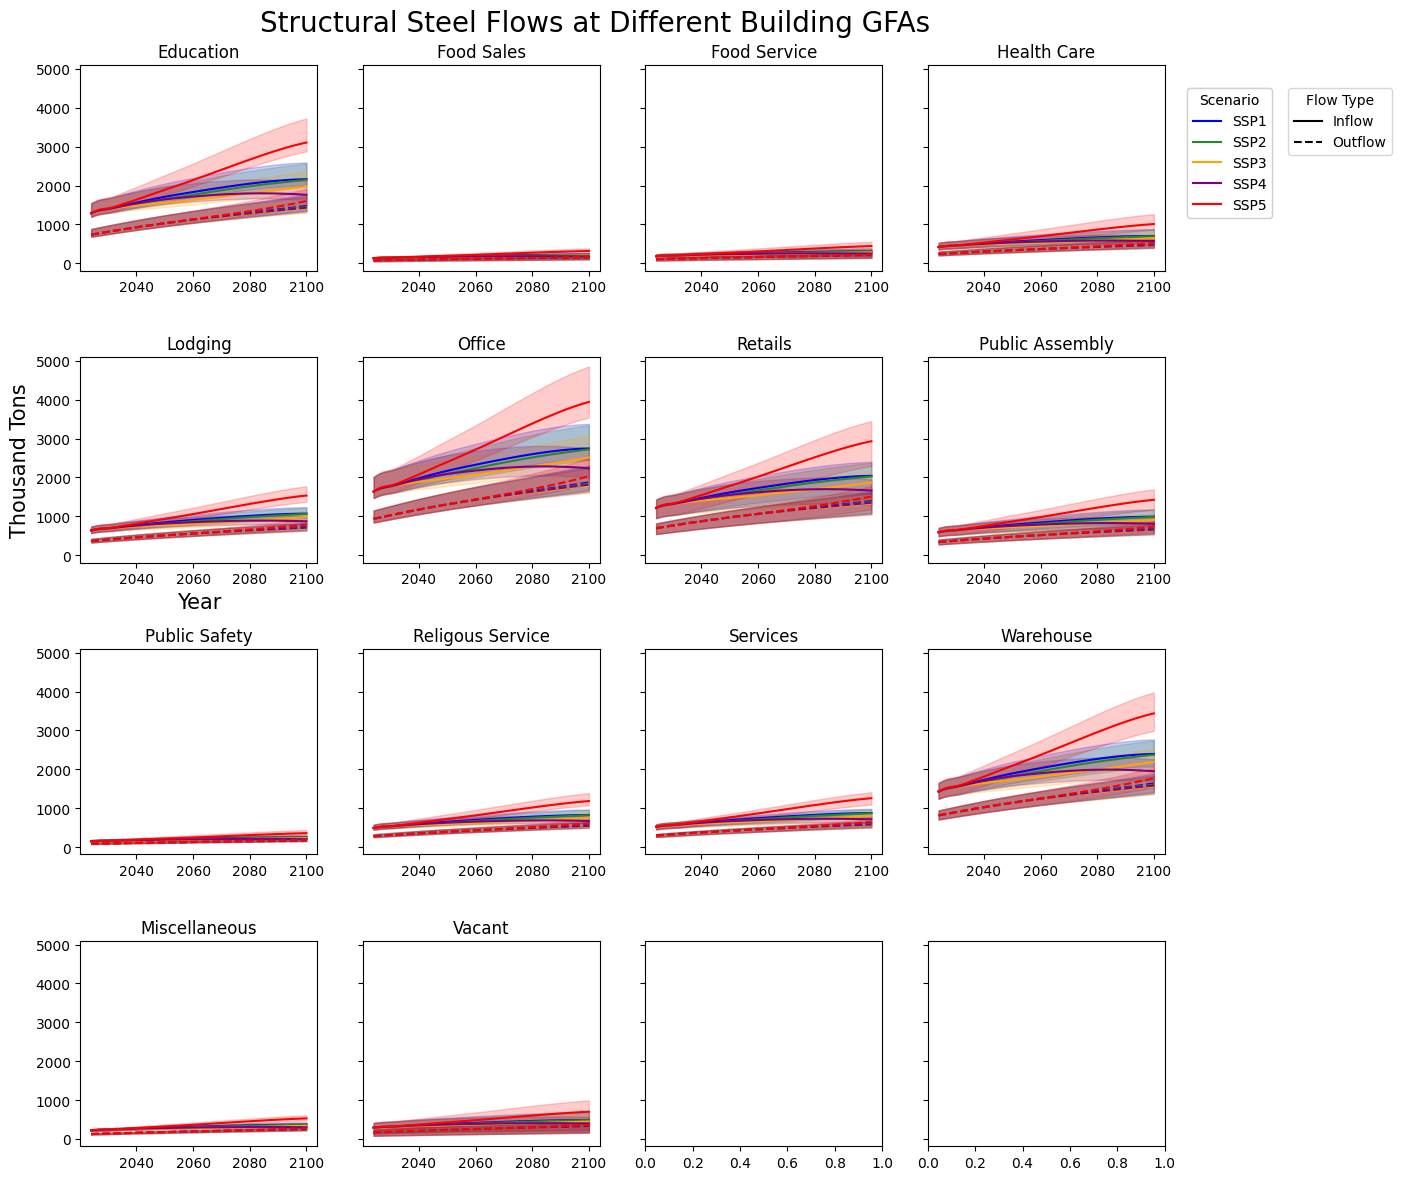

In [ ]:
years  = pd.Index(range(2024, 2101), name="Year")

fig, ax = plt.subplots(nrows = 4, ncols = 4, sharey = True, figsize = (12,12))

ax[0,0].plot(df_education.iloc[93:,10], color = 'blue')
ax[0,0].plot(df_education.iloc[93:,12], color = 'forestgreen')
ax[0,0].plot(df_education.iloc[93:,14], color = 'orange')
ax[0,0].plot(df_education.iloc[93:,16], color = 'purple')
ax[0,0].plot(df_education.iloc[93:,18], color = 'red')
ax[0,0].plot(df_education.iloc[93:,11], color = 'blue', ls = "--")
ax[0,0].plot(df_education.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,0].plot(df_education.iloc[93:,15], color = 'orange', ls = "--")
ax[0,0].plot(df_education.iloc[93:,17], color = 'purple', ls = "--")
ax[0,0].plot(df_education.iloc[93:,19], color = 'red', ls = "--")
ax[0,0].fill_between(years, df_education.iloc[93:,0], df_education.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,2], df_education.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,4], df_education.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,6], df_education.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,8], df_education.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,1], df_education.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,3], df_education.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,5], df_education.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,7], df_education.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,0].fill_between(years, df_education.iloc[93:,9], df_education.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,0].set_title('Education')

ax[0,1].plot(df_food_sales.iloc[93:,10], color = 'blue')
ax[0,1].plot(df_food_sales.iloc[93:,12], color = 'forestgreen')
ax[0,1].plot(df_food_sales.iloc[93:,14], color = 'orange')
ax[0,1].plot(df_food_sales.iloc[93:,16], color = 'purple')
ax[0,1].plot(df_food_sales.iloc[93:,18], color = 'red')
ax[0,1].plot(df_food_sales.iloc[93:,11], color = 'blue', ls = "--")
ax[0,1].plot(df_food_sales.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,1].plot(df_food_sales.iloc[93:,15], color = 'orange', ls = "--")
ax[0,1].plot(df_food_sales.iloc[93:,17], color = 'purple', ls = "--")
ax[0,1].plot(df_food_sales.iloc[93:,19], color = 'red', ls = "--")
ax[0,1].fill_between(years, df_food_sales.iloc[93:,0], df_food_sales.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,2], df_food_sales.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,4], df_food_sales.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,6], df_food_sales.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,8], df_food_sales.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,1], df_food_sales.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,3], df_food_sales.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,5], df_food_sales.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,7], df_food_sales.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,9], df_food_sales.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,1].set_title('Food Sales')

ax[0,2].plot(df_food_service.iloc[93:,10], color = 'blue')
ax[0,2].plot(df_food_service.iloc[93:,12], color = 'forestgreen')
ax[0,2].plot(df_food_service.iloc[93:,14], color = 'orange')
ax[0,2].plot(df_food_service.iloc[93:,16], color = 'purple')
ax[0,2].plot(df_food_service.iloc[93:,18], color = 'red')
ax[0,2].plot(df_food_service.iloc[93:,11], color = 'blue', ls = "--")
ax[0,2].plot(df_food_service.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,2].plot(df_food_service.iloc[93:,15], color = 'orange', ls = "--")
ax[0,2].plot(df_food_service.iloc[93:,17], color = 'purple', ls = "--")
ax[0,2].plot(df_food_service.iloc[93:,19], color = 'red', ls = "--")
ax[0,2].fill_between(years, df_food_service.iloc[93:,0], df_food_service.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,2], df_food_service.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,4], df_food_service.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,6], df_food_service.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,8], df_food_service.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,1], df_food_service.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,3], df_food_service.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,5], df_food_service.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,7], df_food_service.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,2].fill_between(years, df_food_service.iloc[93:,9], df_food_service.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,2].set_title('Food Service')

ax[0,3].plot(df_health_care.iloc[93:,10], color = 'blue')
ax[0,3].plot(df_health_care.iloc[93:,12], color = 'forestgreen')
ax[0,3].plot(df_health_care.iloc[93:,14], color = 'orange')
ax[0,3].plot(df_health_care.iloc[93:,16], color = 'purple')
ax[0,3].plot(df_health_care.iloc[93:,18], color = 'red')
ax[0,3].plot(df_health_care.iloc[93:,11], color = 'blue', ls = "--")
ax[0,3].plot(df_health_care.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[0,3].plot(df_health_care.iloc[93:,15], color = 'orange', ls = "--")
ax[0,3].plot(df_health_care.iloc[93:,17], color = 'purple', ls = "--")
ax[0,3].plot(df_health_care.iloc[93:,19], color = 'red', ls = "--")
ax[0,3].fill_between(years, df_health_care.iloc[93:,0], df_health_care.iloc[93:,20], color = 'blue', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,2], df_health_care.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,4], df_health_care.iloc[93:,24], color = 'orange', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,6], df_health_care.iloc[93:,26], color = 'purple', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,8], df_health_care.iloc[93:,28], color = 'red', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,1], df_health_care.iloc[93:,21], color = 'blue', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,3], df_health_care.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,5], df_health_care.iloc[93:,25], color = 'orange', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,7], df_health_care.iloc[93:,27], color = 'purple', alpha=0.2)
ax[0,3].fill_between(years, df_health_care.iloc[93:,9], df_health_care.iloc[93:,29], color = 'red', alpha=0.2)
ax[0,3].set_title('Health Care')

ax[1,0].plot(df_lodging.iloc[93:,10], color = 'blue')
ax[1,0].plot(df_lodging.iloc[93:,12], color = 'forestgreen')
ax[1,0].plot(df_lodging.iloc[93:,14], color = 'orange')
ax[1,0].plot(df_lodging.iloc[93:,16], color = 'purple')
ax[1,0].plot(df_lodging.iloc[93:,18], color = 'red')
ax[1,0].plot(df_lodging.iloc[93:,11], color = 'blue', ls = "--")
ax[1,0].plot(df_lodging.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,0].plot(df_lodging.iloc[93:,15], color = 'orange', ls = "--")
ax[1,0].plot(df_lodging.iloc[93:,17], color = 'purple', ls = "--")
ax[1,0].plot(df_lodging.iloc[93:,19], color = 'red', ls = "--")
ax[1,0].fill_between(years, df_lodging.iloc[93:,0], df_lodging.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,2], df_lodging.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,4], df_lodging.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,6], df_lodging.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,8], df_lodging.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,1], df_lodging.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,3], df_lodging.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,5], df_lodging.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,7], df_lodging.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,9], df_lodging.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,0].set_title('Lodging')

ax[1,1].plot(df_office.iloc[93:,10], color = 'blue')
ax[1,1].plot(df_office.iloc[93:,12], color = 'forestgreen')
ax[1,1].plot(df_office.iloc[93:,14], color = 'orange')
ax[1,1].plot(df_office.iloc[93:,16], color = 'purple')
ax[1,1].plot(df_office.iloc[93:,18], color = 'red')
ax[1,1].plot(df_office.iloc[93:,11], color = 'blue', ls = "--")
ax[1,1].plot(df_office.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,1].plot(df_office.iloc[93:,15], color = 'orange', ls = "--")
ax[1,1].plot(df_office.iloc[93:,17], color = 'purple', ls = "--")
ax[1,1].plot(df_office.iloc[93:,19], color = 'red', ls = "--")
ax[1,1].fill_between(years, df_office.iloc[93:,0], df_office.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,2], df_office.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,4], df_office.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,6], df_office.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,8], df_office.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,1], df_office.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,3], df_office.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,5], df_office.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,7], df_office.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,9], df_office.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,1].set_title('Office')

ax[1,2].plot(df_mercantile.iloc[93:,10], color = 'blue')
ax[1,2].plot(df_mercantile.iloc[93:,12], color = 'forestgreen')
ax[1,2].plot(df_mercantile.iloc[93:,14], color = 'orange')
ax[1,2].plot(df_mercantile.iloc[93:,16], color = 'purple')
ax[1,2].plot(df_mercantile.iloc[93:,18], color = 'red')
ax[1,2].plot(df_mercantile.iloc[93:,11], color = 'blue', ls = "--")
ax[1,2].plot(df_mercantile.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,2].plot(df_mercantile.iloc[93:,15], color = 'orange', ls = "--")
ax[1,2].plot(df_mercantile.iloc[93:,17], color = 'purple', ls = "--")
ax[1,2].plot(df_mercantile.iloc[93:,19], color = 'red', ls = "--")
ax[1,2].fill_between(years, df_mercantile.iloc[93:,0], df_mercantile.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,2], df_mercantile.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,4], df_mercantile.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,6], df_mercantile.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,8], df_mercantile.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,1], df_mercantile.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,3], df_mercantile.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,5], df_mercantile.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,7], df_mercantile.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,2].fill_between(years, df_mercantile.iloc[93:,9], df_mercantile.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,2].set_title('Retails')

ax[1,3].plot(df_public_assembly.iloc[93:,10], color = 'blue')
ax[1,3].plot(df_public_assembly.iloc[93:,12], color = 'forestgreen')
ax[1,3].plot(df_public_assembly.iloc[93:,14], color = 'orange')
ax[1,3].plot(df_public_assembly.iloc[93:,16], color = 'purple')
ax[1,3].plot(df_public_assembly.iloc[93:,18], color = 'red')
ax[1,3].plot(df_public_assembly.iloc[93:,11], color = 'blue', ls = "--")
ax[1,3].plot(df_public_assembly.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[1,3].plot(df_public_assembly.iloc[93:,15], color = 'orange', ls = "--")
ax[1,3].plot(df_public_assembly.iloc[93:,17], color = 'purple', ls = "--")
ax[1,3].plot(df_public_assembly.iloc[93:,19], color = 'red', ls = "--")
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,0], df_public_assembly.iloc[93:,20], color = 'blue', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,2], df_public_assembly.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,4], df_public_assembly.iloc[93:,24], color = 'orange', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,6], df_public_assembly.iloc[93:,26], color = 'purple', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,8], df_public_assembly.iloc[93:,28], color = 'red', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,1], df_public_assembly.iloc[93:,21], color = 'blue', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,3], df_public_assembly.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,5], df_public_assembly.iloc[93:,25], color = 'orange', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,7], df_public_assembly.iloc[93:,27], color = 'purple', alpha=0.2)
ax[1,3].fill_between(years, df_public_assembly.iloc[93:,9], df_public_assembly.iloc[93:,29], color = 'red', alpha=0.2)
ax[1,3].set_title('Public Assembly')

ax[2,0].plot(df_public_order_safety.iloc[93:,10], color = 'blue')
ax[2,0].plot(df_public_order_safety.iloc[93:,12], color = 'forestgreen')
ax[2,0].plot(df_public_order_safety.iloc[93:,14], color = 'orange')
ax[2,0].plot(df_public_order_safety.iloc[93:,16], color = 'purple')
ax[2,0].plot(df_public_order_safety.iloc[93:,18], color = 'red')
ax[2,0].plot(df_public_order_safety.iloc[93:,11], color = 'blue', ls = "--")
ax[2,0].plot(df_public_order_safety.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[2,0].plot(df_public_order_safety.iloc[93:,15], color = 'orange', ls = "--")
ax[2,0].plot(df_public_order_safety.iloc[93:,17], color = 'purple', ls = "--")
ax[2,0].plot(df_public_order_safety.iloc[93:,19], color = 'red', ls = "--")
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,0], df_public_order_safety.iloc[93:,20], color = 'blue', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,2], df_public_order_safety.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,4], df_public_order_safety.iloc[93:,24], color = 'orange', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,6], df_public_order_safety.iloc[93:,26], color = 'purple', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,8], df_public_order_safety.iloc[93:,28], color = 'red', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,1], df_public_order_safety.iloc[93:,21], color = 'blue', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,3], df_public_order_safety.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,5], df_public_order_safety.iloc[93:,25], color = 'orange', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,7], df_public_order_safety.iloc[93:,27], color = 'purple', alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,9], df_public_order_safety.iloc[93:,29], color = 'red', alpha=0.2)
ax[2,0].set_title('Public Safety')

ax[2,1].plot(df_religious.iloc[93:,10], color = 'blue')
ax[2,1].plot(df_religious.iloc[93:,12], color = 'forestgreen')
ax[2,1].plot(df_religious.iloc[93:,14], color = 'orange')
ax[2,1].plot(df_religious.iloc[93:,16], color = 'purple')
ax[2,1].plot(df_religious.iloc[93:,18], color = 'red')
ax[2,1].plot(df_religious.iloc[93:,11], color = 'blue', ls = "--")
ax[2,1].plot(df_religious.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[2,1].plot(df_religious.iloc[93:,15], color = 'orange', ls = "--")
ax[2,1].plot(df_religious.iloc[93:,17], color = 'purple', ls = "--")
ax[2,1].plot(df_religious.iloc[93:,19], color = 'red', ls = "--")
ax[2,1].fill_between(years, df_religious.iloc[93:,0], df_religious.iloc[93:,20], color = 'blue', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,2], df_religious.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,4], df_religious.iloc[93:,24], color = 'orange', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,6], df_religious.iloc[93:,26], color = 'purple', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,8], df_religious.iloc[93:,28], color = 'red', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,1], df_religious.iloc[93:,21], color = 'blue', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,3], df_religious.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,5], df_religious.iloc[93:,25], color = 'orange', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,7], df_religious.iloc[93:,27], color = 'purple', alpha=0.2)
ax[2,1].fill_between(years, df_religious.iloc[93:,9], df_religious.iloc[93:,29], color = 'red', alpha=0.2)
ax[2,1].set_title('Religous Service')

ax[2,2].plot(df_service.iloc[93:,10], color = 'blue')
ax[2,2].plot(df_service.iloc[93:,12], color = 'forestgreen')
ax[2,2].plot(df_service.iloc[93:,14], color = 'orange')
ax[2,2].plot(df_service.iloc[93:,16], color = 'purple')
ax[2,2].plot(df_service.iloc[93:,18], color = 'red')
ax[2,2].plot(df_service.iloc[93:,11], color = 'blue', ls = "--")
ax[2,2].plot(df_service.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[2,2].plot(df_service.iloc[93:,15], color = 'orange', ls = "--")
ax[2,2].plot(df_service.iloc[93:,17], color = 'purple', ls = "--")
ax[2,2].plot(df_service.iloc[93:,19], color = 'red', ls = "--")
ax[2,2].fill_between(years, df_service.iloc[93:,0], df_service.iloc[93:,20], color = 'blue', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,2], df_service.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,4], df_service.iloc[93:,24], color = 'orange', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,6], df_service.iloc[93:,26], color = 'purple', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,8], df_service.iloc[93:,28], color = 'red', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,1], df_service.iloc[93:,21], color = 'blue', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,3], df_service.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,5], df_service.iloc[93:,25], color = 'orange', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,7], df_service.iloc[93:,27], color = 'purple', alpha=0.2)
ax[2,2].fill_between(years, df_service.iloc[93:,9], df_service.iloc[93:,29], color = 'red', alpha=0.2)
ax[2,2].set_title('Services')

ax[2,3].plot(df_warehouse.iloc[93:,10], color = 'blue')
ax[2,3].plot(df_warehouse.iloc[93:,12], color = 'forestgreen')
ax[2,3].plot(df_warehouse.iloc[93:,14], color = 'orange')
ax[2,3].plot(df_warehouse.iloc[93:,16], color = 'purple')
ax[2,3].plot(df_warehouse.iloc[93:,18], color = 'red')
ax[2,3].plot(df_warehouse.iloc[93:,11], color = 'blue', ls = "--")
ax[2,3].plot(df_warehouse.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[2,3].plot(df_warehouse.iloc[93:,15], color = 'orange', ls = "--")
ax[2,3].plot(df_warehouse.iloc[93:,17], color = 'purple', ls = "--")
ax[2,3].plot(df_warehouse.iloc[93:,19], color = 'red', ls = "--")
ax[2,3].fill_between(years, df_warehouse.iloc[93:,0], df_warehouse.iloc[93:,20], color = 'blue', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,2], df_warehouse.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,4], df_warehouse.iloc[93:,24], color = 'orange', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,6], df_warehouse.iloc[93:,26], color = 'purple', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,8], df_warehouse.iloc[93:,28], color = 'red', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,1], df_warehouse.iloc[93:,21], color = 'blue', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,3], df_warehouse.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,5], df_warehouse.iloc[93:,25], color = 'orange', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,7], df_warehouse.iloc[93:,27], color = 'purple', alpha=0.2)
ax[2,3].fill_between(years, df_warehouse.iloc[93:,9], df_warehouse.iloc[93:,29], color = 'red', alpha=0.2)
ax[2,3].set_title('Warehouse')

ax[3,0].plot(df_other.iloc[93:,10], color = 'blue')
ax[3,0].plot(df_other.iloc[93:,12], color = 'forestgreen')
ax[3,0].plot(df_other.iloc[93:,14], color = 'orange')
ax[3,0].plot(df_other.iloc[93:,16], color = 'purple')
ax[3,0].plot(df_other.iloc[93:,18], color = 'red')
ax[3,0].plot(df_other.iloc[93:,11], color = 'blue', ls = "--")
ax[3,0].plot(df_other.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[3,0].plot(df_other.iloc[93:,15], color = 'orange', ls = "--")
ax[3,0].plot(df_other.iloc[93:,17], color = 'purple', ls = "--")
ax[3,0].plot(df_other.iloc[93:,19], color = 'red', ls = "--")
ax[3,0].fill_between(years, df_other.iloc[93:,0], df_other.iloc[93:,20], color = 'blue', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,2], df_other.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,4], df_other.iloc[93:,24], color = 'orange', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,6], df_other.iloc[93:,26], color = 'purple', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,8], df_other.iloc[93:,28], color = 'red', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,1], df_other.iloc[93:,21], color = 'blue', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,3], df_other.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,5], df_other.iloc[93:,25], color = 'orange', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,7], df_other.iloc[93:,27], color = 'purple', alpha=0.2)
ax[3,0].fill_between(years, df_other.iloc[93:,9], df_other.iloc[93:,29], color = 'red', alpha=0.2)
ax[3,0].set_title('Miscellaneous')

ax[3,1].plot(df_vacant.iloc[93:,10], color = 'blue')
ax[3,1].plot(df_vacant.iloc[93:,12], color = 'forestgreen')
ax[3,1].plot(df_vacant.iloc[93:,14], color = 'orange')
ax[3,1].plot(df_vacant.iloc[93:,16], color = 'purple')
ax[3,1].plot(df_vacant.iloc[93:,18], color = 'red')
ax[3,1].plot(df_vacant.iloc[93:,11], color = 'blue', ls = "--")
ax[3,1].plot(df_vacant.iloc[93:,13], color = 'forestgreen', ls = "--")
ax[3,1].plot(df_vacant.iloc[93:,15], color = 'orange', ls = "--")
ax[3,1].plot(df_vacant.iloc[93:,17], color = 'purple', ls = "--")
ax[3,1].plot(df_vacant.iloc[93:,19], color = 'red', ls = "--")
ax[3,1].fill_between(years, df_vacant.iloc[93:,0], df_vacant.iloc[93:,20], color = 'blue', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,2], df_vacant.iloc[93:,22], color = 'forestgreen', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,4], df_vacant.iloc[93:,24], color = 'orange', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,6], df_vacant.iloc[93:,26], color = 'purple', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,8], df_vacant.iloc[93:,28], color = 'red', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,1], df_vacant.iloc[93:,21], color = 'blue', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,3], df_vacant.iloc[93:,23], color = 'forestgreen', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,5], df_vacant.iloc[93:,25], color = 'orange', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,7], df_vacant.iloc[93:,27], color = 'purple', alpha=0.2)
ax[3,1].fill_between(years, df_vacant.iloc[93:,9], df_vacant.iloc[93:,29], color = 'red', alpha=0.2)
ax[3,1].set_title('Vacant')


scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = fig.legend(handles=scenario_handles, title='Scenario', loc='upper right',bbox_to_anchor=(1.07,0.92) )
fig.add_artist(leg1)

inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

fig.suptitle('Structural Steel Flows at Different Building GFAs', fontsize = 20)
ax[1,0].set_xlabel('Year', fontsize = 15)
ax[1,0].set_ylabel('Thousand Tons',fontsize = 15)
fig.legend(handles=flow_handles, title='Flow Type', loc='upper right',bbox_to_anchor=(1.17,0.92))
plt.show()

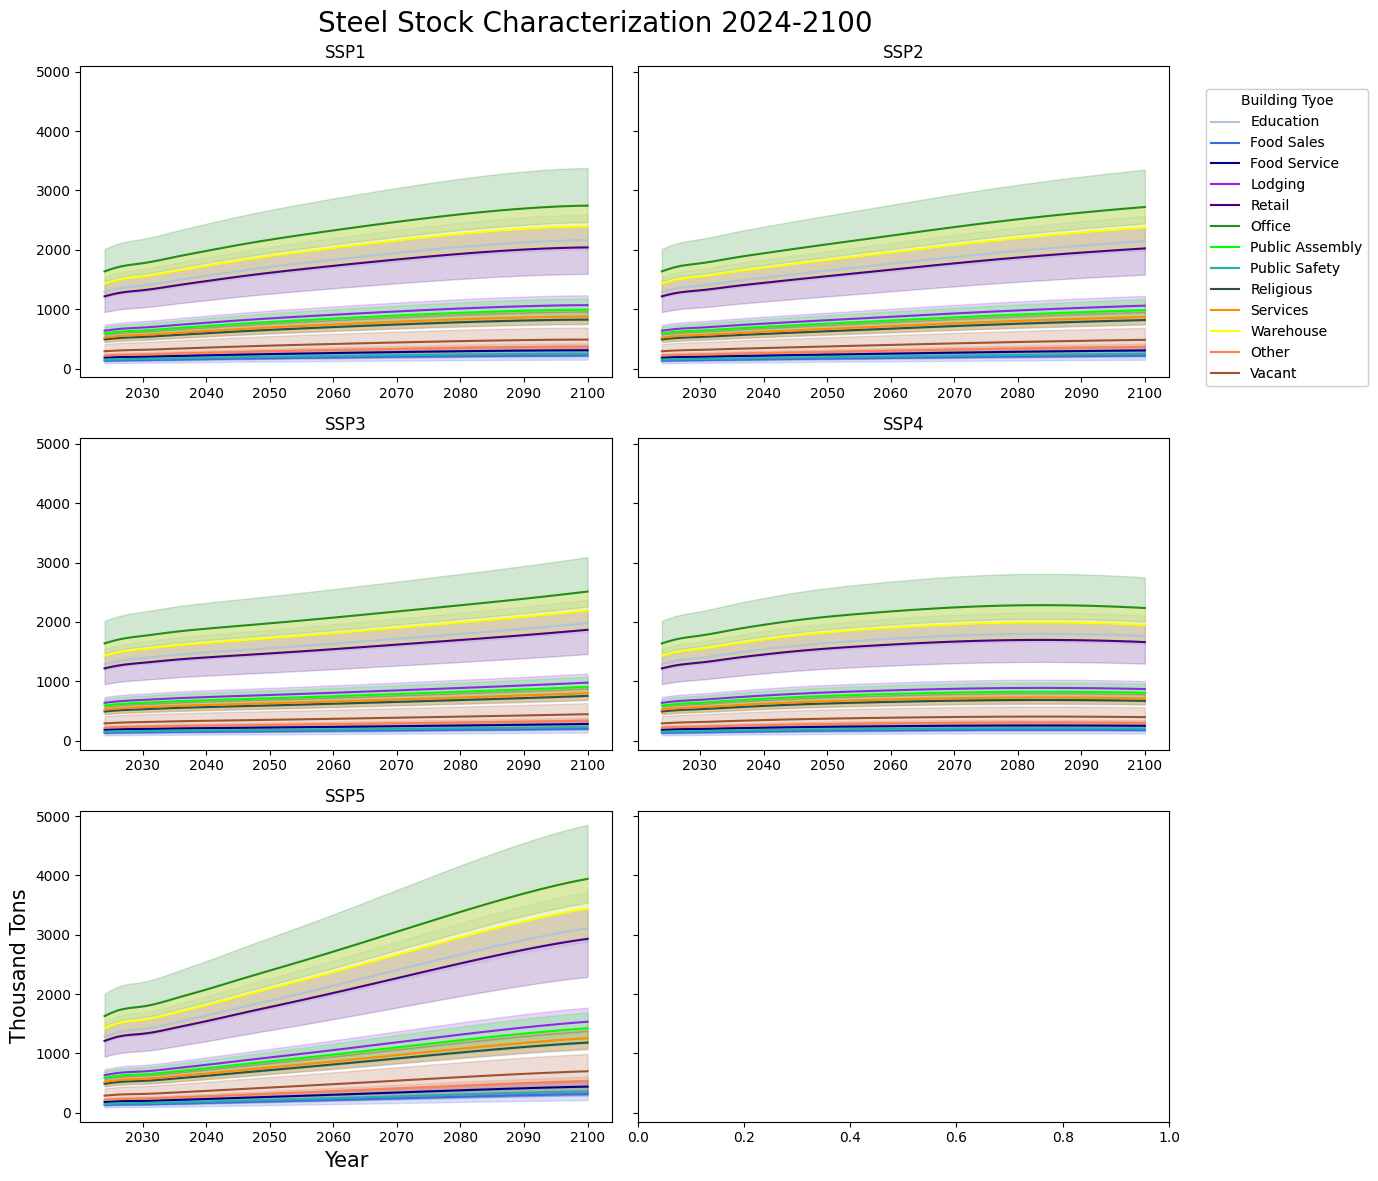

In [ ]:
fig, ax = plt.subplots(nrows = 3, ncols = 2, sharey = True, figsize = (12,12))

ax[0,0].plot(df_education.iloc[93:,10],color = 'lightsteelblue')
ax[0,0].plot(df_food_sales.iloc[93:,10],color = 'royalblue')
ax[0,0].plot(df_food_service.iloc[93:,10],color = 'darkblue')
ax[0,0].plot(df_lodging.iloc[93:,10],color = 'blueviolet')
ax[0,0].plot(df_mercantile.iloc[93:,10],color = 'indigo')
ax[0,0].plot(df_office.iloc[93:,10],color = 'forestgreen')
ax[0,0].plot(df_public_assembly.iloc[93:,10],color = 'lime')
ax[0,0].plot(df_public_order_safety.iloc[93:,10],color = 'lightseagreen')
ax[0,0].plot(df_religious.iloc[93:,10],color = 'darkslategray')
ax[0,0].plot(df_service.iloc[93:,10],color = 'darkorange')
ax[0,0].plot(df_warehouse.iloc[93:,10],color = 'yellow')
ax[0,0].plot(df_other.iloc[93:,10],color = 'coral')
ax[0,0].plot(df_vacant.iloc[93:,10],color = 'sienna')
ax[0,0].fill_between(years, df_education.iloc[93:,0],df_education.iloc[93:,20],color = 'lightsteelblue',alpha=0.2)
ax[0,0].fill_between(years, df_food_sales.iloc[93:,0],df_food_sales.iloc[93:,20],color = 'royalblue',alpha=0.2)
ax[0,0].fill_between(years, df_food_service.iloc[93:,0],df_food_service.iloc[93:,20],color = 'darkblue',alpha=0.2)
ax[0,0].fill_between(years, df_lodging.iloc[93:,0],df_lodging.iloc[93:,20],color = 'blueviolet',alpha=0.2)
ax[0,0].fill_between(years, df_mercantile.iloc[93:,0],df_mercantile.iloc[93:,20],color = 'indigo',alpha=0.2)
ax[0,0].fill_between(years, df_office.iloc[93:,0],df_office.iloc[93:,20],color = 'forestgreen',alpha=0.2)
ax[0,0].fill_between(years, df_public_assembly.iloc[93:,0],df_public_assembly.iloc[93:,20],color = 'lime',alpha=0.2)
ax[0,0].fill_between(years, df_public_order_safety.iloc[93:,0],df_public_order_safety.iloc[93:,20],color = 'lightseagreen',alpha=0.2)
ax[0,0].fill_between(years, df_religious.iloc[93:,0],df_religious.iloc[93:,20],color = 'darkslategray',alpha=0.2)
ax[0,0].fill_between(years, df_service.iloc[93:,0],df_service.iloc[93:,20],color = 'darkorange',alpha=0.2)
ax[0,0].fill_between(years, df_warehouse.iloc[93:,0],df_warehouse.iloc[93:,20],color = 'yellow',alpha=0.2)
ax[0,0].fill_between(years, df_other.iloc[93:,0],df_other.iloc[93:,20],color = 'coral',alpha=0.2)
ax[0,0].fill_between(years, df_vacant.iloc[93:,0],df_vacant.iloc[93:,20],color = 'sienna',alpha=0.2)
ax[0,0].set_title('SSP1')

ax[0,1].plot(df_education.iloc[93:,12],color = 'lightsteelblue')
ax[0,1].plot(df_food_sales.iloc[93:,12],color = 'royalblue')
ax[0,1].plot(df_food_service.iloc[93:,12],color = 'darkblue')
ax[0,1].plot(df_lodging.iloc[93:,12],color = 'blueviolet')
ax[0,1].plot(df_mercantile.iloc[93:,12],color = 'indigo')
ax[0,1].plot(df_office.iloc[93:,12],color = 'forestgreen')
ax[0,1].plot(df_public_assembly.iloc[93:,12],color = 'lime')
ax[0,1].plot(df_public_order_safety.iloc[93:,12],color = 'lightseagreen')
ax[0,1].plot(df_religious.iloc[93:,12],color = 'darkslategray')
ax[0,1].plot(df_service.iloc[93:,12],color = 'darkorange')
ax[0,1].plot(df_warehouse.iloc[93:,12],color = 'yellow')
ax[0,1].plot(df_other.iloc[93:,12],color = 'coral')
ax[0,1].plot(df_vacant.iloc[93:,12],color = 'sienna')
ax[0,1].fill_between(years, df_education.iloc[93:,2],df_education.iloc[93:,22],color = 'lightsteelblue',alpha=0.2)
ax[0,1].fill_between(years, df_food_sales.iloc[93:,2],df_food_sales.iloc[93:,22],color = 'royalblue',alpha=0.2)
ax[0,1].fill_between(years, df_food_service.iloc[93:,2],df_food_service.iloc[93:,22],color = 'darkblue',alpha=0.2)
ax[0,1].fill_between(years, df_lodging.iloc[93:,2],df_lodging.iloc[93:,22],color = 'blueviolet',alpha=0.2)
ax[0,1].fill_between(years, df_mercantile.iloc[93:,2],df_mercantile.iloc[93:,22],color = 'indigo',alpha=0.2)
ax[0,1].fill_between(years, df_office.iloc[93:,2],df_office.iloc[93:,22],color = 'forestgreen',alpha=0.2)
ax[0,1].fill_between(years, df_public_assembly.iloc[93:,2],df_public_assembly.iloc[93:,22],color = 'lime',alpha=0.2)
ax[0,1].fill_between(years, df_public_order_safety.iloc[93:,2],df_public_order_safety.iloc[93:,22],color = 'lightseagreen',alpha=0.2)
ax[0,1].fill_between(years, df_religious.iloc[93:,2],df_religious.iloc[93:,22],color = 'darkslategray',alpha=0.2)
ax[0,1].fill_between(years, df_service.iloc[93:,2],df_service.iloc[93:,22],color = 'darkorange',alpha=0.2)
ax[0,1].fill_between(years, df_warehouse.iloc[93:,2],df_warehouse.iloc[93:,22],color = 'yellow',alpha=0.2)
ax[0,1].fill_between(years, df_other.iloc[93:,2],df_other.iloc[93:,22],color = 'coral',alpha=0.2)
ax[0,1].fill_between(years, df_vacant.iloc[93:,2],df_vacant.iloc[93:,22],color = 'sienna',alpha=0.2)
ax[0,1].set_title('SSP2')

ax[1,0].plot(df_education.iloc[93:,14],color = 'lightsteelblue')
ax[1,0].plot(df_food_sales.iloc[93:,14],color = 'royalblue')
ax[1,0].plot(df_food_service.iloc[93:,14],color = 'darkblue')
ax[1,0].plot(df_lodging.iloc[93:,14],color = 'blueviolet')
ax[1,0].plot(df_mercantile.iloc[93:,14],color = 'indigo')
ax[1,0].plot(df_office.iloc[93:,14],color = 'forestgreen')
ax[1,0].plot(df_public_assembly.iloc[93:,14],color = 'lime')
ax[1,0].plot(df_public_order_safety.iloc[93:,14],color = 'lightseagreen')
ax[1,0].plot(df_religious.iloc[93:,14],color = 'darkslategray')
ax[1,0].plot(df_service.iloc[93:,14],color = 'darkorange')
ax[1,0].plot(df_warehouse.iloc[93:,14],color = 'yellow')
ax[1,0].plot(df_other.iloc[93:,14],color = 'coral')
ax[1,0].plot(df_vacant.iloc[93:,14],color = 'sienna')
ax[1,0].fill_between(years, df_education.iloc[93:,4],df_education.iloc[93:,24],color = 'lightsteelblue',alpha=0.2)
ax[1,0].fill_between(years, df_food_sales.iloc[93:,4],df_food_sales.iloc[93:,24],color = 'royalblue',alpha=0.2)
ax[1,0].fill_between(years, df_food_service.iloc[93:,4],df_food_service.iloc[93:,24],color = 'darkblue',alpha=0.2)
ax[1,0].fill_between(years, df_lodging.iloc[93:,4],df_lodging.iloc[93:,24],color = 'blueviolet',alpha=0.2)
ax[1,0].fill_between(years, df_mercantile.iloc[93:,4],df_mercantile.iloc[93:,24],color = 'indigo',alpha=0.2)
ax[1,0].fill_between(years, df_office.iloc[93:,4],df_office.iloc[93:,24],color = 'forestgreen',alpha=0.2)
ax[1,0].fill_between(years, df_public_assembly.iloc[93:,4],df_public_assembly.iloc[93:,24],color = 'lime',alpha=0.2)
ax[1,0].fill_between(years, df_public_order_safety.iloc[93:,4],df_public_order_safety.iloc[93:,24],color = 'lightseagreen',alpha=0.2)
ax[1,0].fill_between(years, df_religious.iloc[93:,4],df_religious.iloc[93:,24],color = 'darkslategray',alpha=0.2)
ax[1,0].fill_between(years, df_service.iloc[93:,4],df_service.iloc[93:,24],color = 'darkorange',alpha=0.2)
ax[1,0].fill_between(years, df_warehouse.iloc[93:,4],df_warehouse.iloc[93:,24],color = 'yellow',alpha=0.2)
ax[1,0].fill_between(years, df_other.iloc[93:,4],df_other.iloc[93:,24],color = 'coral',alpha=0.2)
ax[1,0].fill_between(years, df_vacant.iloc[93:,4],df_vacant.iloc[93:,24],color = 'sienna',alpha=0.2)
ax[1,0].set_title('SSP3')

ax[1,1].plot(df_education.iloc[93:,16],color = 'lightsteelblue')
ax[1,1].plot(df_food_sales.iloc[93:,16],color = 'royalblue')
ax[1,1].plot(df_food_service.iloc[93:,16],color = 'darkblue')
ax[1,1].plot(df_lodging.iloc[93:,16],color = 'blueviolet')
ax[1,1].plot(df_mercantile.iloc[93:,16],color = 'indigo')
ax[1,1].plot(df_office.iloc[93:,16],color = 'forestgreen')
ax[1,1].plot(df_public_assembly.iloc[93:,16],color = 'lime')
ax[1,1].plot(df_public_order_safety.iloc[93:,16],color = 'lightseagreen')
ax[1,1].plot(df_religious.iloc[93:,16],color = 'darkslategray')
ax[1,1].plot(df_service.iloc[93:,16],color = 'darkorange')
ax[1,1].plot(df_warehouse.iloc[93:,16],color = 'yellow')
ax[1,1].plot(df_other.iloc[93:,16],color = 'coral')
ax[1,1].plot(df_vacant.iloc[93:,16],color = 'sienna')
ax[1,1].fill_between(years, df_education.iloc[93:,6],df_education.iloc[93:,26],color = 'lightsteelblue',alpha=0.2)
ax[1,1].fill_between(years, df_food_sales.iloc[93:,6],df_food_sales.iloc[93:,26],color = 'royalblue',alpha=0.2)
ax[1,1].fill_between(years, df_food_service.iloc[93:,6],df_food_service.iloc[93:,26],color = 'darkblue',alpha=0.2)
ax[1,1].fill_between(years, df_lodging.iloc[93:,6],df_lodging.iloc[93:,26],color = 'blueviolet',alpha=0.2)
ax[1,1].fill_between(years, df_mercantile.iloc[93:,6],df_mercantile.iloc[93:,26],color = 'indigo',alpha=0.2)
ax[1,1].fill_between(years, df_office.iloc[93:,6],df_office.iloc[93:,26],color = 'forestgreen',alpha=0.2)
ax[1,1].fill_between(years, df_public_assembly.iloc[93:,6],df_public_assembly.iloc[93:,26],color = 'lime',alpha=0.2)
ax[1,1].fill_between(years, df_public_order_safety.iloc[93:,6],df_public_order_safety.iloc[93:,26],color = 'lightseagreen',alpha=0.2)
ax[1,1].fill_between(years, df_religious.iloc[93:,6],df_religious.iloc[93:,26],color = 'darkslategray',alpha=0.2)
ax[1,1].fill_between(years, df_service.iloc[93:,6],df_service.iloc[93:,26],color = 'darkorange',alpha=0.2)
ax[1,1].fill_between(years, df_warehouse.iloc[93:,6],df_warehouse.iloc[93:,26],color = 'yellow',alpha=0.2)
ax[1,1].fill_between(years, df_other.iloc[93:,6],df_other.iloc[93:,26],color = 'coral',alpha=0.2)
ax[1,1].fill_between(years, df_vacant.iloc[93:,6],df_vacant.iloc[93:,26],color = 'sienna',alpha=0.2)
ax[1,1].set_title('SSP4')

ax[2,0].plot(df_education.iloc[93:,18],color = 'lightsteelblue')
ax[2,0].plot(df_food_sales.iloc[93:,18],color = 'royalblue')
ax[2,0].plot(df_food_service.iloc[93:,18],color = 'darkblue')
ax[2,0].plot(df_lodging.iloc[93:,18],color = 'blueviolet')
ax[2,0].plot(df_mercantile.iloc[93:,18],color = 'indigo')
ax[2,0].plot(df_office.iloc[93:,18],color = 'forestgreen')
ax[2,0].plot(df_public_assembly.iloc[93:,18],color = 'lime')
ax[2,0].plot(df_public_order_safety.iloc[93:,18],color = 'lightseagreen')
ax[2,0].plot(df_religious.iloc[93:,18],color = 'darkslategray')
ax[2,0].plot(df_service.iloc[93:,18],color = 'darkorange')
ax[2,0].plot(df_warehouse.iloc[93:,18],color = 'yellow')
ax[2,0].plot(df_other.iloc[93:,18],color = 'coral')
ax[2,0].plot(df_vacant.iloc[93:,18],color = 'sienna')
ax[2,0].fill_between(years, df_education.iloc[93:,8],df_education.iloc[93:,28],color = 'lightsteelblue',alpha=0.2)
ax[2,0].fill_between(years, df_food_sales.iloc[93:,8],df_food_sales.iloc[93:,28],color = 'royalblue',alpha=0.2)
ax[2,0].fill_between(years, df_food_service.iloc[93:,8],df_food_service.iloc[93:,28],color = 'darkblue',alpha=0.2)
ax[2,0].fill_between(years, df_lodging.iloc[93:,8],df_lodging.iloc[93:,28],color = 'blueviolet',alpha=0.2)
ax[2,0].fill_between(years, df_mercantile.iloc[93:,8],df_mercantile.iloc[93:,28],color = 'indigo',alpha=0.2)
ax[2,0].fill_between(years, df_office.iloc[93:,8],df_office.iloc[93:,28],color = 'forestgreen',alpha=0.2)
ax[2,0].fill_between(years, df_public_assembly.iloc[93:,8],df_public_assembly.iloc[93:,28],color = 'lime',alpha=0.2)
ax[2,0].fill_between(years, df_public_order_safety.iloc[93:,8],df_public_order_safety.iloc[93:,28],color = 'lightseagreen',alpha=0.2)
ax[2,0].fill_between(years, df_religious.iloc[93:,8],df_religious.iloc[93:,28],color = 'darkslategray',alpha=0.2)
ax[2,0].fill_between(years, df_service.iloc[93:,8],df_service.iloc[93:,28],color = 'darkorange',alpha=0.2)
ax[2,0].fill_between(years, df_warehouse.iloc[93:,8],df_warehouse.iloc[93:,28],color = 'yellow',alpha=0.2)
ax[2,0].fill_between(years, df_other.iloc[93:,8],df_other.iloc[93:,28],color = 'coral',alpha=0.2)
ax[2,0].fill_between(years, df_vacant.iloc[93:,8],df_vacant.iloc[93:,28],color = 'sienna',alpha=0.2)
ax[2,0].set_title('SSP5')

scenario_handles = [
    mlines.Line2D([], [], color='lightsteelblue', linestyle='-', label='Education'),
    mlines.Line2D([], [], color='royalblue', linestyle='-', label='Food Sales'),
    mlines.Line2D([], [], color='darkblue',linestyle='-', label='Food Service'),
    mlines.Line2D([], [], color='blueviolet',linestyle='-', label='Lodging'),
    mlines.Line2D([], [], color='indigo', linestyle='-', label='Retail'),
    mlines.Line2D([], [], color='forestgreen',linestyle='-', label='Office'),
    mlines.Line2D([], [], color='lime',linestyle='-', label='Public Assembly'),
    mlines.Line2D([], [], color='lightseagreen',linestyle='-', label='Public Safety'),
    mlines.Line2D([], [], color='darkslategray',linestyle='-', label='Religious'),
    mlines.Line2D([], [], color='darkorange',linestyle='-', label='Services'),
    mlines.Line2D([], [], color='yellow',linestyle='-', label='Warehouse'),
    mlines.Line2D([], [], color='coral',linestyle='-', label='Other'),
    mlines.Line2D([], [], color='sienna',linestyle='-', label='Vacant'),
]

leg1 = fig.legend(handles=scenario_handles, 
                  title='Building Tyoe', 
                  loc='upper right',
                  bbox_to_anchor=(1.15,0.92) )
fig.add_artist(leg1)

# inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
# outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

# flow_handles = [
#     mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
#     mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
# ]

fig.suptitle('Steel Stock Characterization 2024-2100', fontsize = 20)
ax[2,0].set_xlabel('Year', fontsize = 15)
ax[2,0].set_ylabel('Thousand Tons',fontsize = 15)
# fig.legend(handles=flow_handles, title='Flow Type', loc='upper right',bbox_to_anchor=(1.17,0.92))
plt.show()



In [155]:
use_type_pct_range.columns.tolist()

['low', 'mean', 'high']

In [156]:
use_type_pct_range['mean']

Education                   15.162500
Food sales                   1.540000
Food service                 2.155000
Health care                  4.922500
Lodging                      7.487500
Mercantile                  14.305000
Office                      19.240000
Public assembly              6.950000
Public order and safety      1.742500
Religious worship            5.775000
Service                      6.132500
Warehouse and storage       16.787500
Other                        2.580000
Vacant                       3.416667
Name: mean, dtype: float64

In [157]:
use_type_2018_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\use_type_2018_pct.csv', index_col = 0)
use_type_2018_pct = use_type_2018_pct.T


In [158]:
sizes_pct_range

,low,mean,high
index,,,
10001 to 25000 Square Feet,15.20,16.0875,16.67
25001 to 50000 Square Feet,5.37,5.8450,6.52
50001 to 100000 Square Feet,3.03,3.3500,3.68
100001 to 200000 Square Feet,1.27,1.4950,1.62
200001 to 500000 Square Feet,0.49,0.5975,0.68
Over 500000 Square Feet,0.14,0.1500,0.16


In [159]:
use_type_2018_pct = use_type_2018_pct.sort_values('All Buildings')

In [160]:
use_type_2018_pct

index,All Buildings,1001 to 5000 Square Feet,5001 to 10000 Square Feet,10001 to 25000 Square Feet,25001 to 50000 Square Feet,50001 to 100000 Square Feet,100001 to 200000 Square Feet,200001 to 500000 Square Feet,Over 500000 Square Feet
Food sales,1.04,3.49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Food service,1.44,7.23,6.69,NaN,NaN,NaN,NaN,NaN,NaN
Public order and safety,1.60,NaN,NaN,NaN,NaN,NaN,NaN,2.82,NaN
Vacant,1.67,4.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Other,2.53,NaN,NaN,NaN,NaN,NaN,3.60,4.29,NaN
Health care,4.17,2.25,2.78,2.54,2.54,3.37,3.23,6.99,15.17
Religious worship,5.67,6.10,9.05,13.77,10.72,4.06,NaN,NaN,NaN
Service,6.47,18.81,18.04,10.22,6.56,3.88,NaN,NaN,NaN
Lodging,7.23,NaN,NaN,4.43,11.50,10.71,11.17,6.90,9.18
Public assembly,7.46,8.63,9.72,10.49,11.74,6.99,3.81,3.64,8.63


In [161]:
sizes_pct_range = sizes_pct_range.iloc[1:8]

In [162]:
def index_cleaning(df):
    df_reset = df.reset_index()
    df_reset['index'] = df_reset['index'].str.replace('\n',' ').str.replace('square','Square').str.replace('feet','Feet').str.replace(',','').str.replace('.','')
    df_new_index = df_reset.set_index('index')
    
    return df_new_index

sizes_pct_range = index_cleaning(sizes_pct_range)

In [163]:
pct_barchart_df = pd.concat([sizes_pct_range['mean'],use_type_2018_pct], axis = 1)

In [164]:
pct_barchart_df.iloc[0,3:17].sum()

np.float64(0.0)

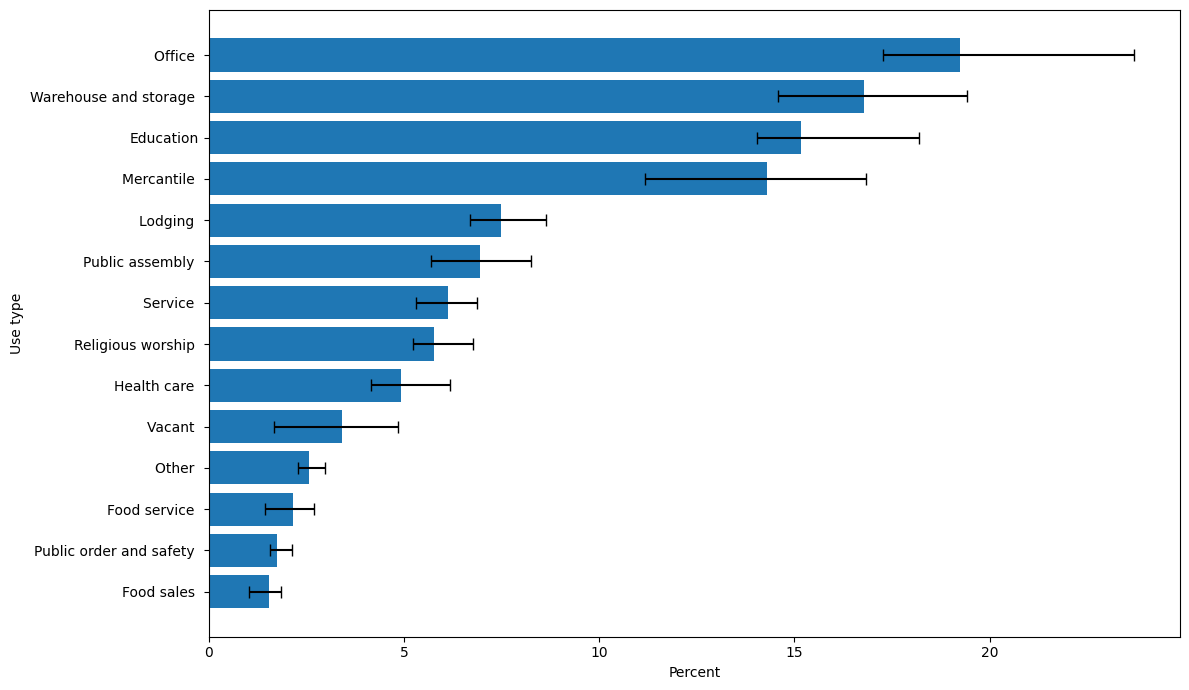

In [165]:
use_type_pct_range = use_type_pct_range.sort_values("mean", ascending=True)

y = np.arange(len(use_type_pct_range))
means = use_type_pct_range["mean"].to_numpy()

x_err_plus  = (use_type_pct_range["high"] - use_type_pct_range["mean"]).to_numpy()
x_err_minus = (use_type_pct_range["mean"] - use_type_pct_range["low"]).to_numpy()
xerr = np.vstack([x_err_minus, x_err_plus])

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(y, means, xerr=xerr, align="center", capsize=4)

ax.set_yticks(y)
ax.set_yticklabels(use_type_pct_range.index)
ax.set_xlabel("Percent")
ax.set_ylabel("Use type")

plt.tight_layout()
plt.show()

In [166]:
use_type_2018_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\2018_pct.csv', index_col = 0)
use_type_2018_pct = use_type_2018_pct.T
use_type_2018_pct

index,All Buildings,1001 to 5000 Square Feet,5001 to 10000 Square Feet,10001 to 25000 Square Feet,25001 to 50000 Square Feet,50001 to 100000 Square Feet,100001 to 200000 Square Feet,200001 to 500000 Square Feet,Over 500000 Square Feet,Unknown size
Education,14.1,2.9,5.6,9.0,11.1,29.5,24.4,15.8,1.7,0.0
Food sales,1.0,26.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.7
Food service,1.4,39.6,44.0,NaN,NaN,NaN,NaN,NaN,NaN,16.3
Health care,4.2,4.3,6.3,9.3,8.1,12.3,9.9,19.9,29.9,0.0
Lodging,7.2,NaN,NaN,9.4,21.3,22.5,19.8,11.3,10.4,5.4
Mercantile,11.2,5.0,7.5,20.2,16.1,16.3,17.2,12.3,5.5,-0.0
Office,17.3,8.3,8.7,13.0,11.4,14.3,14.5,15.3,14.6,0.0
Public assembly,7.5,9.1,12.3,21.5,21.1,14.2,6.5,5.8,9.5,-0.0
Public order and safety,1.6,NaN,NaN,NaN,NaN,NaN,NaN,20.9,NaN,79.1
Religious worship,5.7,8.5,15.1,37.1,25.3,10.9,NaN,NaN,NaN,3.2


In [167]:
def plot_stock_by_bin(df, 
                      df_range = None, 
                      total_col=None, 
                      assume_bins_are_percent=True, 
                      sort = True,
                      title='', 
                      xlabel ='',
                      ylabel = ''):

    # 1) identify columns
    if total_col is None:
        total_col = df.columns[0]  # first column is total height

    bin_cols = [c for c in df.columns if c != total_col]

    # 2) clean numeric + fill NaNs in bins as 0
    df2 = df.copy()
    df2[bin_cols] = df2[bin_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
    df2[total_col] = pd.to_numeric(df2[total_col], errors="coerce").fillna(0)

    # 3) convert within-type bin % -> fractions if needed
    bin_frac = df2[bin_cols] / 100 if assume_bins_are_percent else df2[bin_cols]

    # 4) scale bins so stacks sum to total_col
    stacks = bin_frac.mul(df2[total_col], axis=0)

    # 5) sort by total for nicer view (small -> big)
    if sort:
        order = df2[total_col].sort_values().index
    else:
        order = df2[total_col].index

    stacks = stacks.loc[order]
    totals = df2.loc[order, total_col]

    if df_range is not None:
        df_range_ord = df_range.loc[order]

        # build asymmetric x-errors for totals
        x_err_plus  = (df_range_ord["high"] - df_range_ord["mean"]).to_numpy()
        x_err_minus = (df_range_ord["mean"] - df_range_ord["low"]).to_numpy()

        # prevent negative whiskers if rounding/unit mismatch
        x_err_minus = np.minimum(x_err_minus, totals.to_numpy())

        xerr = np.vstack([x_err_minus, x_err_plus])
    else:
        xerr = None

    # 6) plot
    n = len(stacks.columns)
    cmap = plt.get_cmap("tab20")
    colors = cmap(np.linspace(0, 1, n))

    fig, ax = plt.subplots(figsize=(13, 8))

    left = pd.Series(0, index=stacks.index)
    for i, c in enumerate(stacks.columns):
        ax.barh(
            stacks.index,
            stacks[c],
            left=left,
            label=c,
            color=colors[i]   # <-- THIS is the key
        )
        left = left + stacks[c]

    # Single errorbar per row, at the total (end of stack)
    ax.errorbar(
        x=totals.to_numpy(),
        y=np.arange(len(totals)),      # numeric y positions that match the bar order
        xerr=xerr,
        fmt="none",
        ecolor="black",
        elinewidth=1.5,
        capsize=4,
        zorder=10,
    )

    # Make sure y tick labels match those numeric positions
    ax.set_yticks(np.arange(len(totals)))
    ax.set_yticklabels(totals.index)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(title="Area", bbox_to_anchor=(1.07, 1), loc="upper left")
    ax.set_title(title)
    for i, (label, value) in enumerate(totals.items()):
        ax.text(
            value + 0.3,
            i+0.2,
            f"{value:.1f}%",
            va="center",
            ha="left",
            fontsize=10,
            color="black"
        )
    ax.set_xlim(0,)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='x', alpha=0.25)
    plt.tight_layout()
    plt.show()

    return fig, ax

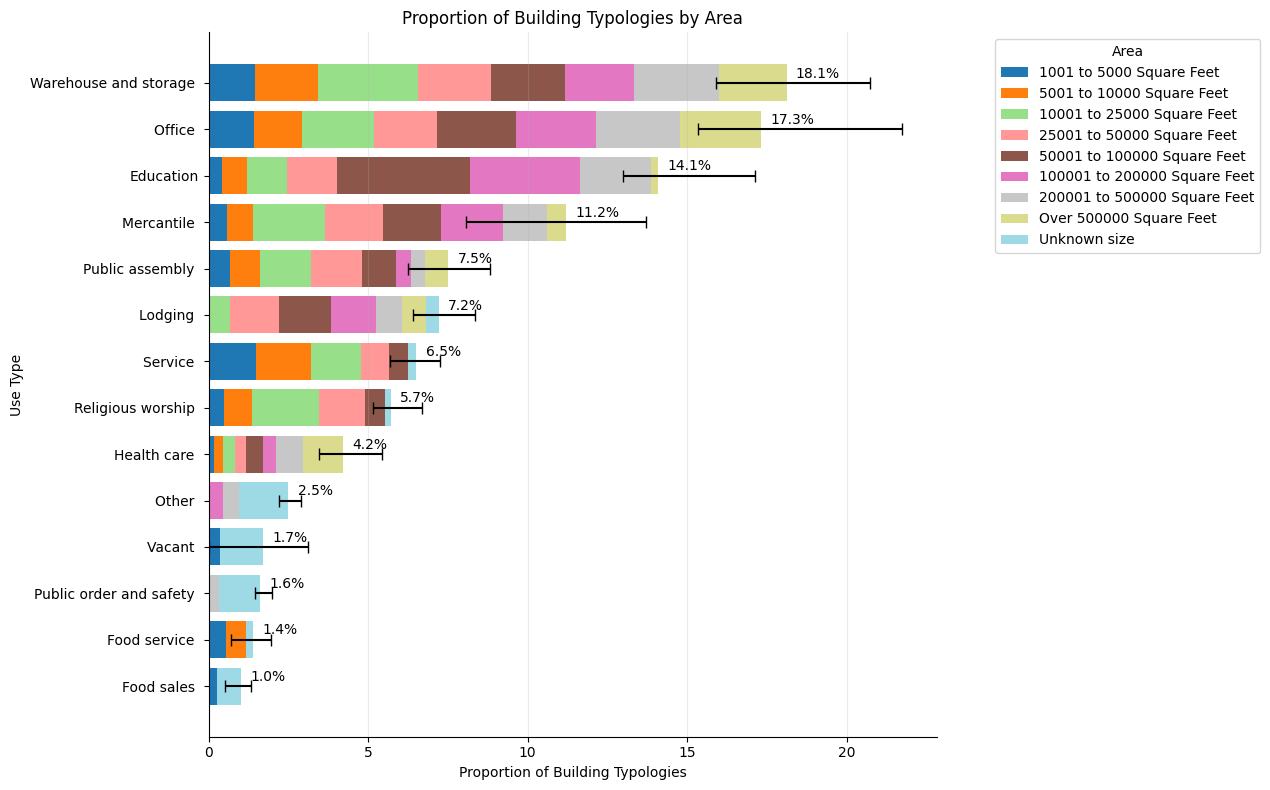

(<Figure size 1300x800 with 1 Axes>,
 <Axes: title={'center': 'Proportion of Building Typologies by Area'}, xlabel='Proportion of Building Typologies', ylabel='Use Type'>)

In [168]:
plot_stock_by_bin(use_type_2018_pct, 
                  df_range = use_type_pct_range, 
                  total_col='All Buildings', 
                  assume_bins_are_percent=True,
                  sort = True,
                  title="Proportion of Building Typologies by Area",
                  xlabel="Proportion of Building Typologies",
                  ylabel="Use Type",
                  )


In [169]:
plot_stock_by_bin(pct_barchart_df.iloc[4:8], sizes_pct_range, total_col='mean', assume_bins_are_percent=True, )



KeyError: "['Food sales ', 'Food service ', 'Public order and safety '] not in index"

In [170]:
all_heights_pct_range = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\heights_pct_range.csv', index_col = 0)
heights_2018_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\2018_heights_pct.csv', index_col = 0)
heights_2018_pct = heights_2018_pct.T

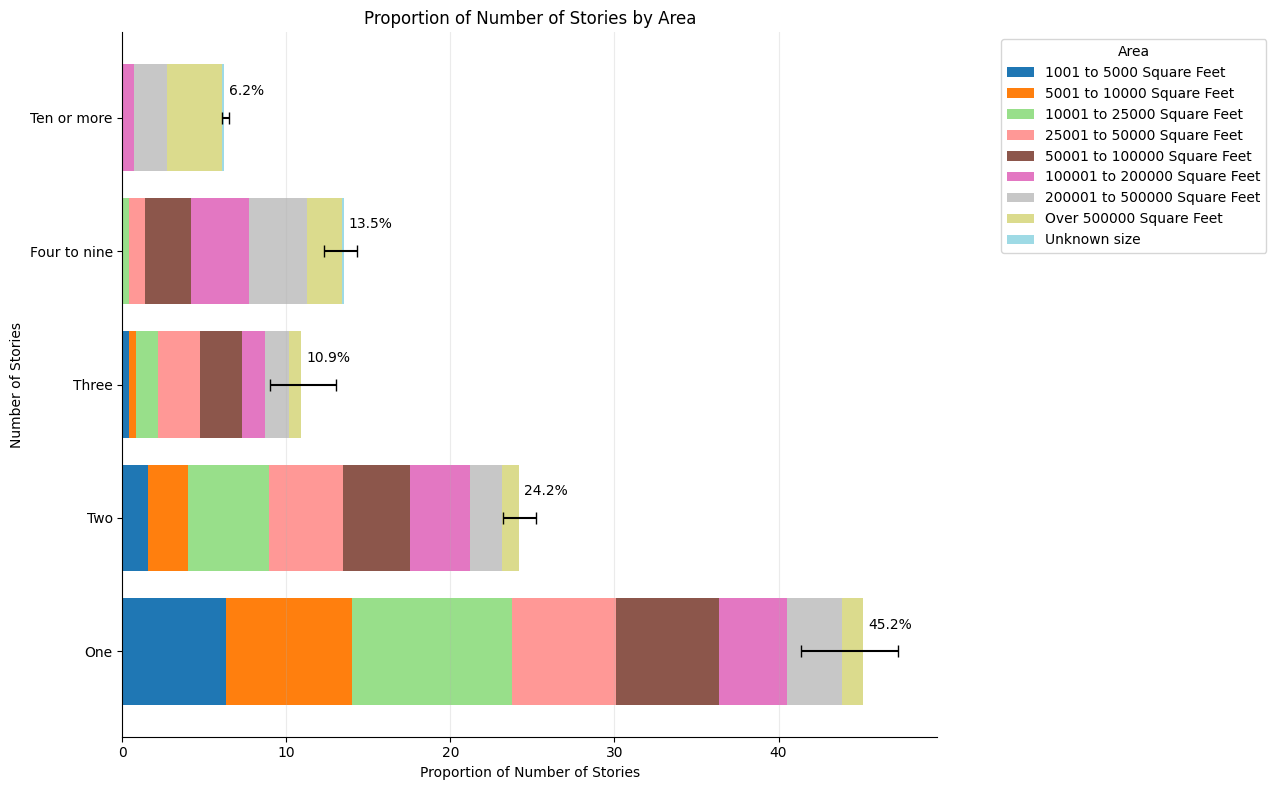

(<Figure size 1300x800 with 1 Axes>,
 <Axes: title={'center': 'Proportion of Number of Stories by Area'}, xlabel='Proportion of Number of Stories', ylabel='Number of Stories'>)

In [172]:
plot_stock_by_bin(heights_2018_pct, 
                  df_range = all_heights_pct_range, 
                  total_col='All Buildings', 
                  assume_bins_are_percent=True, 
                  sort = False,
                  title="Proportion of Number of Stories by Area",
                  xlabel="Proportion of Number of Stories",
                  ylabel="Number of Stories",
                  )


In [173]:
bldg_vintage_2018_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\bldg_vintage_2018_pct.csv', index_col=0)
bldg_vintage_2018_pct = bldg_vintage_2018_pct.T

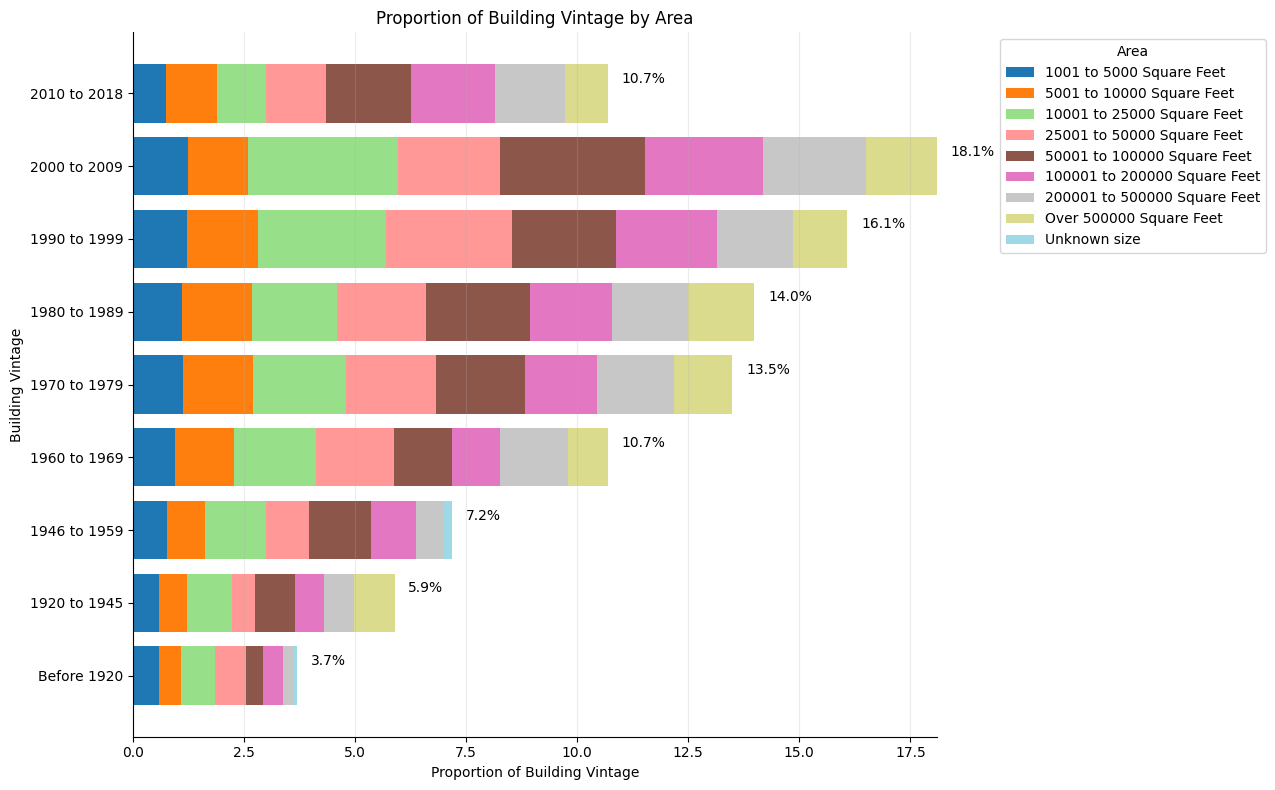

(<Figure size 1300x800 with 1 Axes>,
 <Axes: title={'center': 'Proportion of Building Vintage by Area'}, xlabel='Proportion of Building Vintage', ylabel='Building Vintage'>)

In [174]:
plot_stock_by_bin(bldg_vintage_2018_pct,
                  df_range = None,
                  total_col='All Buildings', 
                  assume_bins_are_percent=True, 
                  sort = False,
                  title="Proportion of Building Vintage by Area",
                  xlabel="Proportion of Building Vintage",
                  ylabel="Building Vintage",
                  )

In [175]:
sizes_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\df_sizes_pct.csv', index_col=0)
use_type_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\use_type_pct.csv', index_col=0)
heights_pct = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\heights_pct.csv', index_col =0)

In [176]:
sizes_pct

,1999,2003,2012,2018
"5,001 to 10,000 Square Feet",23.84,19.51,22.12,22.96
"10,001 to 25,000 Square Feet",15.20,16.67,15.91,16.57
"25,001 to 50,000 Square Feet",5.52,5.37,5.97,6.52
"50,001 to 100,000 Square Feet",3.11,3.03,3.58,3.68
"100,001 to 200,000 Square Feet",1.27,1.52,1.62,1.57
"200,001 to 500,000 Square Feet",0.49,0.54,0.68,0.68
"Over 500,000 Square Feet",0.15,0.16,0.14,0.15


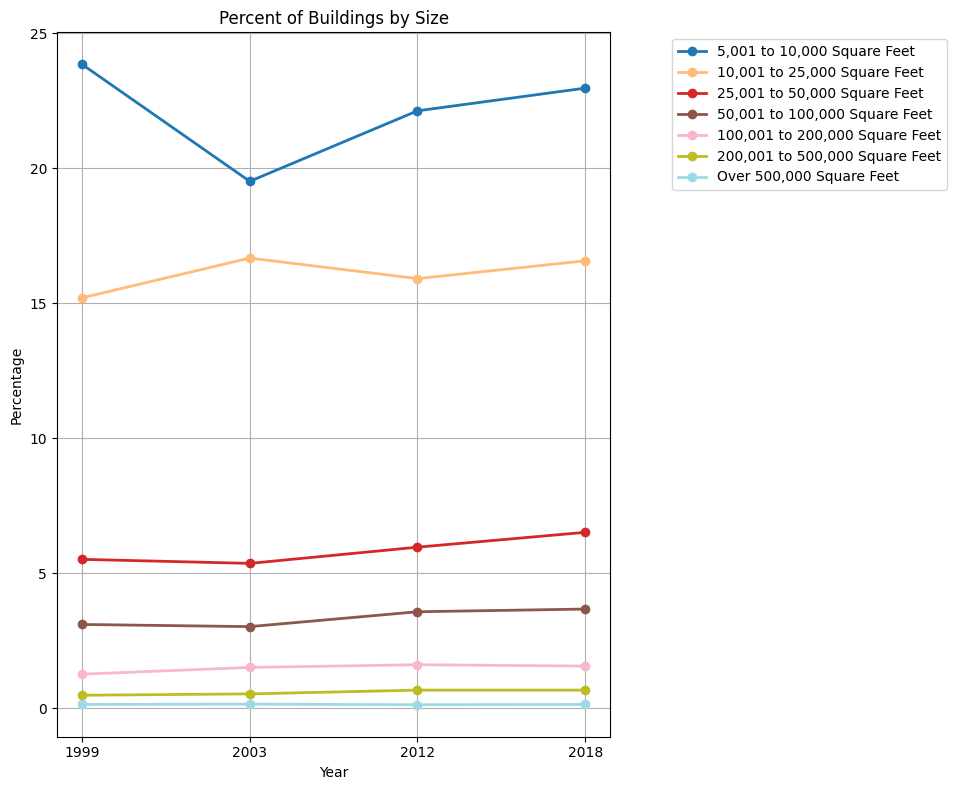

In [ ]:
fig, ax = plt.subplots()
n = len(sizes_pct.index)
cmap = plt.get_cmap("tab20")
colors = cmap(np.linspace(0, 1, n))
for i, idx in enumerate(sizes_pct.index):
    ax.plot(
        sizes_pct.columns,        # x = years
        sizes_pct.loc[idx],       # y = that building type
        label=idx,
        marker="o",
        color=colors[i],          # <-- THIS is the important part
        linewidth=2
    )

ax.set_title("Percent of Buildings by Size")
ax.set_xlabel("Year")
ax.set_ylabel("Percentage")
ax.legend(loc = 'upper right', bbox_to_anchor = (1.62,1))
ax.grid(True)
plt.show()

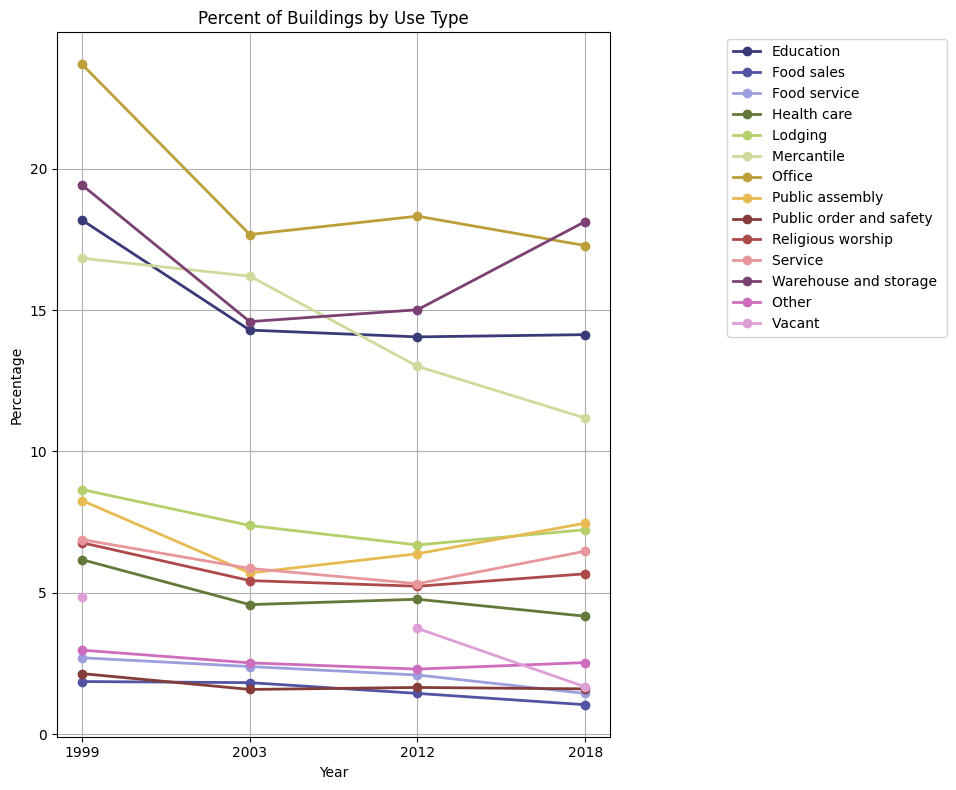

In [ ]:
fig, ax = plt.subplots()
n = len(use_type_pct.index)
cmap = plt.get_cmap("tab20b")
colors = cmap(np.linspace(0, 1, n))
for i, idx in enumerate(use_type_pct.index):
    ax.plot(
        use_type_pct.columns,        # x = years
        use_type_pct.loc[idx],       # y = that building type
        label=idx,
        marker="o",
        color=colors[i],          # <-- THIS is the important part
        linewidth=2
    )

ax.set_title("Percent of Buildings by Use Type")
ax.set_xlabel("Year")
ax.set_ylabel("Percentage")
ax.legend(loc = 'upper right', bbox_to_anchor = (1.62,1))
ax.grid(True)
plt.show()

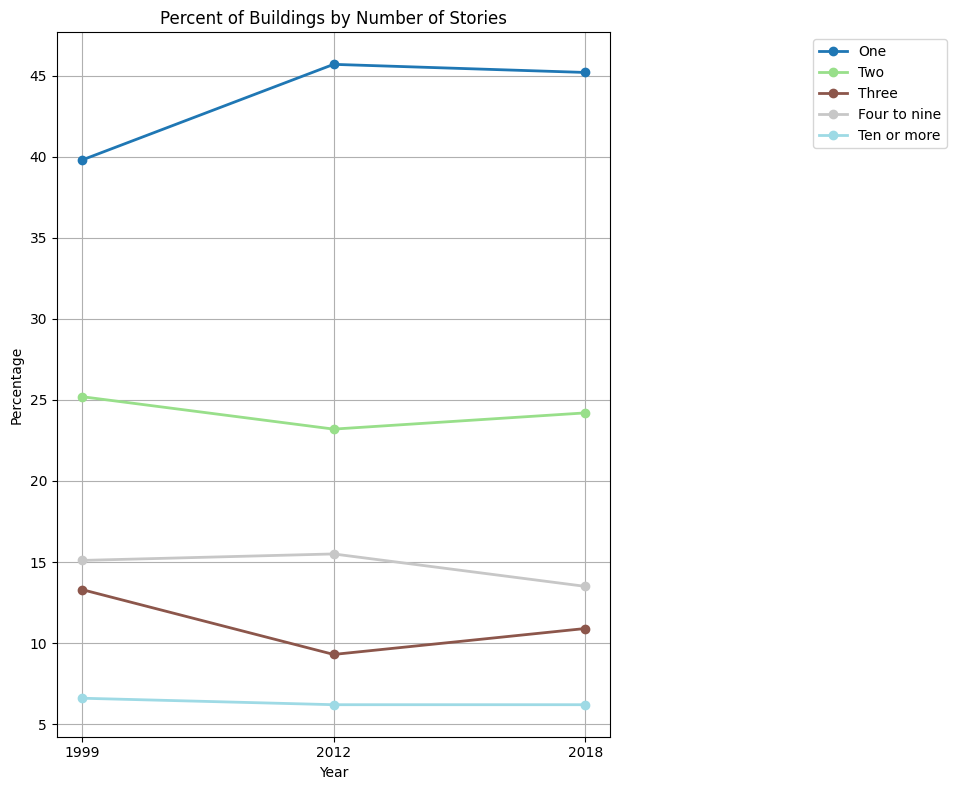

In [ ]:
fig, ax = plt.subplots()
n = len(heights_pct.index)
cmap = plt.get_cmap("tab20")
colors = cmap(np.linspace(0, 1, n))
for i, idx in enumerate(heights_pct.index):
    ax.plot(
        heights_pct.columns,        # x = years
        heights_pct.loc[idx],       # y = that building type
        label=idx,
        marker="o",
        color=colors[i],          # <-- THIS is the important part
        linewidth=2
    )

ax.set_title("Percent of Buildings by Number of Stories")
ax.set_xlabel("Year")
ax.set_ylabel("Percentage")
ax.legend(loc = 'upper right', bbox_to_anchor = (1.62,1))
ax.grid(True)
plt.show()

## Use type projections

In [252]:
use_type_count = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\use_type_2018.csv', index_col=0)
use_type_count = use_type_count.iloc[0]
use_type_count = use_type_count.T
use_type_count = use_type_count.sort_values(ascending = False)
use_type_count.index = use_type_count.index.str.strip()

In [253]:
use_type_count

Warehouse and storage      17483.0
Office                     16662.0
Education                  13623.0
Mercantile                 10781.0
Public assembly             7192.0
Lodging                     6976.0
Service                     6240.0
Religious worship           5471.0
Health care                 4018.0
Other                       2435.0
Vacant                      1612.0
Public order and safety     1538.0
Food service                1385.0
Food sales                  1006.0
Name: All Buildings, dtype: float64

In [258]:
reuse_scenarios = pd.read_excel('C:/Users/aorga/OneDrive/Documents/01_CU/00_Research/02_US Structural Steel MFA/reuse scenarios by type.xlsx', sheet_name='Sheet2', index_col=0)

In [259]:
reuse_scenarios

,BAU Growth,Predicted Growth,Green Growth,High Reuse,Mid Reuse,Low Reuse
Use type,,,,,,
Warehouse and storage,1.21,2.18,0.18,1,1,1
Office,0.95,2.18,2.70,1,1,0
Education,0.89,2.18,0.13,1,1,0
Mercantile,0.84,2.18,0.13,1,1,0
Public assembly,0.00,2.18,0.00,1,1,1
Lodging,2.81,2.18,0.42,1,1,1
Service,0.84,2.18,0.13,1,0,0
Religious worship,0.00,2.18,0.00,0,0,0
Health care,2.02,2.18,0.23,1,0,0


In [260]:
growth_rates = reuse_scenarios.iloc[:,0:3]

In [261]:
growth_rates

,BAU Growth,Predicted Growth,Green Growth
Use type,,,
Warehouse and storage,1.21,2.18,0.18
Office,0.95,2.18,2.70
Education,0.89,2.18,0.13
Mercantile,0.84,2.18,0.13
Public assembly,0.00,2.18,0.00
Lodging,2.81,2.18,0.42
Service,0.84,2.18,0.13
Religious worship,0.00,2.18,0.00
Health care,2.02,2.18,0.23


In [262]:
print(growth_rates.index.tolist())

['Warehouse and storage ', 'Office ', 'Education ', 'Mercantile ', 'Public assembly ', 'Lodging ', 'Service ', 'Religious worship ', 'Health care ', 'Other ', 'Vacant ', 'Public order and safety ', 'Food service ', 'Food sales ']


In [263]:
years_buildings = list(range(2018, 2101))
scenarios_buildings = ["BAU Growth", "Predicted Growth", "Green Growth"]
use_types = list(use_type_count.keys())

growth_rates_lookup = growth_rates.copy()
growth_rates_lookup.index = growth_rates_lookup.index.str.strip().str.lower()

def project_scenario(scenario: str) -> pd.DataFrame:
    data = {}
    for ut in use_type_count.keys():
        key = ut.strip().lower()
        rate = growth_rates_lookup.loc[key, scenario] / 100
        base = use_type_count[ut]
        data[ut] = [base * (1 + rate) ** (yr - 2018) for yr in years_buildings]

    df = pd.DataFrame(data, index=years_buildings).T
    df.index.name = "Use Type"
    df.columns.name = "Year"
    return df

projections = {scenario: project_scenario(scenario) for scenario in scenarios_buildings}

In [264]:
projections

{'BAU Growth': Year                        2018        2019          2020          2021  \
 Use Type                                                                   
 Warehouse and storage    17483.0  17694.5443  17908.648286  18125.342930   
 Office                   16662.0  16820.2890  16980.081745  17141.392522   
 Education                13623.0  13744.2447  13866.568478  13989.980937   
 Mercantile               10781.0  10871.5604  10962.881507  11054.969712   
 Public assembly           7192.0   7192.0000   7192.000000   7192.000000   
 Lodging                   6976.0   7172.0256   7373.559519   7580.756542   
 Service                   6240.0   6292.4160   6345.272294   6398.572582   
 Religious worship         5471.0   5471.0000   5471.000000   5471.000000   
 Health care               4018.0   4099.1636   4181.966705   4266.442432   
 Other                     2435.0   2435.0000   2435.000000   2435.000000   
 Vacant                    1612.0   1612.0000   1612.000000   

In [265]:
projections_pct = {
    scenario: df.div(df.sum(axis=0), axis=1) * 100
    for scenario, df in projections.items()
}

In [266]:
projections_pct.keys()

dict_keys(['BAU Growth', 'Predicted Growth', 'Green Growth'])

In [267]:
bau_pct       = projections_pct["BAU Growth"]
predicted_pct = projections_pct["Predicted Growth"]
green_pct     = projections_pct["Green Growth"]

In [286]:
bau_pct = bau_pct.T
predicted_pct = predicted_pct.T
green_pct = green_pct.T

In [287]:
bau_pct

Use Type,Warehouse and storage,Office,Education,Mercantile,Public assembly,Lodging,Service,Religious worship,Health care,Other,Vacant,Public order and safety,Food service,Food sales
Year,,,,,,,,,,,,,,
2018,18.131754,17.280289,14.128518,11.181058,7.458879,7.234863,6.471552,5.674016,4.167099,2.525357,1.671818,1.595072,1.436394,1.043330
2019,18.172825,17.274939,14.115750,11.165417,7.386399,7.365884,6.462499,5.618880,4.209963,2.500818,1.655572,1.579572,1.422436,1.069044
2020,18.212986,17.268640,14.102216,11.149184,7.314220,7.498865,6.453103,5.563974,4.253035,2.476380,1.639394,1.564137,1.408537,1.095331
2021,18.252222,17.261384,14.087912,11.132355,7.242345,7.633822,6.443363,5.509297,4.296308,2.452045,1.623284,1.548766,1.394695,1.122201
2022,18.290518,17.253165,14.072835,11.114930,7.170774,7.770774,6.433277,5.454853,4.339778,2.427813,1.607242,1.533461,1.380912,1.149667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,17.649341,13.762767,10.742656,8.179104,2.841418,23.935907,4.734033,2.161484,7.553535,0.962021,0.636869,0.607634,0.547186,5.686046
2097,17.586635,13.678639,10.670644,8.120250,2.797473,24.227917,4.699968,2.128055,7.586935,0.947142,0.627020,0.598236,0.538724,5.792362
2098,17.522497,13.593743,10.598114,8.061058,2.753948,24.521174,4.665709,2.094946,7.619764,0.932406,0.617264,0.588928,0.530342,5.900108


### Get Reuse Rates by Building Type

In [280]:
all_flows.index

Index([1931, 1932, 1933, 1934, 1935, 1936, 1937, 1938, 1939, 1940,
       ...
       2091, 2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099, 2100],
      dtype='int64', name='Year', length=170)

In [283]:
ssp1_flows = all_flows.iloc[:,0:2]
ssp2_flows = all_flows.iloc[:,2:4]
ssp3_flows = all_flows.iloc[:,4:6]
ssp4_flows = all_flows.iloc[:,6:8]
ssp5_flows = all_flows.iloc[:,8:10]

In [284]:
ssp5_flows

,inflow_ssp5,outflow_ssp5
Year,,
1931,2396.480000,0.000000
1932,1263.680000,0.109237
1933,2145.890000,0.467943
1934,2406.640000,1.088172
1935,3149.100000,2.062242
...,...,...
2096,20548.419477,10274.619955
2097,20675.642745,10371.126041
2098,20796.972289,10468.912800


In [346]:
# Filter inflows/outflows to 2024-2100
ssp1_flows_future = ssp1_flows.loc[2024:2100]
ssp1_flows_future = ssp1_flows.loc[2024:2100]
ssp2_flows_future = ssp2_flows.loc[2024:2100]
ssp2_flows_future = ssp2_flows.loc[2024:2100]
ssp3_flows_future = ssp3_flows.loc[2024:2100]
ssp3_flows_future = ssp3_flows.loc[2024:2100]
ssp4_flows_future = ssp4_flows.loc[2024:2100]
ssp4_flows_future = ssp4_flows.loc[2024:2100]
ssp5_flows_future = ssp5_flows.loc[2024:2100]
ssp5_flows_future = ssp5_flows.loc[2024:2100]


# Align bau_pct to same year range (already transposed, so index=years, columns=use types)
bau_pct_aligned = bau_pct.loc[2024:2100]
predicted_pct_aligned = predicted_pct.loc[2024:2100]
green_pct_aligned = green_pct.loc[2024:2100]

# Multiply each year's total by the % share for each use type
# SSP1
green_inflows_ssp1  = green_pct_aligned.multiply(ssp1_flows_future["inflow_ssp1"],  axis=0) / 100
green_outflows_ssp1 = green_pct_aligned.multiply(ssp1_flows_future["outflow_ssp1"], axis=0) / 100

# SSP2
bau_inflows_ssp2 = bau_pct_aligned.multiply(ssp2_flows_future["inflow_ssp2"],  axis=0) / 100
bau_outflows_ssp2 = bau_pct_aligned.multiply(ssp2_flows_future["outflow_ssp2"],  axis=0) / 100
green_inflows_ssp2 = green_pct_aligned.multiply(ssp2_flows_future["inflow_ssp2"],  axis=0) / 100
green_outflows_ssp2 = green_pct_aligned.multiply(ssp2_flows_future["outflow_ssp2"],  axis=0) / 100
predicted_inflows_ssp2 = predicted_pct_aligned.multiply(ssp2_flows_future["inflow_ssp2"],  axis=0) / 100
predicted_outflows_ssp2 = predicted_pct_aligned.multiply(ssp2_flows_future["outflow_ssp2"],  axis=0) / 100

# SSP3
bau_inflows_ssp3 = bau_pct_aligned.multiply(ssp3_flows_future["inflow_ssp3"],  axis=0) / 100
bau_outflows_ssp3 = bau_pct_aligned.multiply(ssp3_flows_future["outflow_ssp3"],  axis=0) / 100
predicted_inflows_ssp3 = predicted_pct_aligned.multiply(ssp3_flows_future["inflow_ssp3"],  axis=0) / 100
predicted_outflows_ssp3 = predicted_pct_aligned.multiply(ssp3_flows_future["outflow_ssp3"],  axis=0) / 100

# SSP4
bau_inflows_ssp4 = bau_pct_aligned.multiply(ssp4_flows_future["inflow_ssp4"],  axis=0) / 100
bau_outflows_ssp4 = bau_pct_aligned.multiply(ssp4_flows_future["outflow_ssp4"],  axis=0) / 100
green_inflows_ssp4 = green_pct_aligned.multiply(ssp4_flows_future["inflow_ssp4"],  axis=0) / 100
green_outflows_ssp4 = green_pct_aligned.multiply(ssp4_flows_future["outflow_ssp4"],  axis=0) / 100
predicted_inflows_ssp4 = predicted_pct_aligned.multiply(ssp4_flows_future["inflow_ssp4"],  axis=0) / 100
predicted_outflows_ssp4 = predicted_pct_aligned.multiply(ssp4_flows_future["outflow_ssp4"],  axis=0) / 100

# SSP5
bau_inflows_ssp5 = bau_pct_aligned.multiply(ssp5_flows_future["inflow_ssp5"],  axis=0) / 100
bau_outflows_ssp5 = bau_pct_aligned.multiply(ssp5_flows_future["outflow_ssp5"],  axis=0) / 100
predicted_inflows_ssp5 = predicted_pct_aligned.multiply(ssp5_flows_future["inflow_ssp5"],  axis=0) / 100
predicted_outflows_ssp5 = predicted_pct_aligned.multiply(ssp5_flows_future["outflow_ssp5"],  axis=0) / 100


In [347]:
bau_inflows_ssp2

Use Type,Warehouse and storage,Office,Education,Mercantile,Public assembly,Lodging,Service,Religious worship,Health care,Other,Vacant,Public order and safety,Food service,Food sales
Year,,,,,,,,,,,,,,
2024,1565.107385,1468.766315,1196.600343,944.155880,599.014469,686.129767,546.473675,455.674105,377.319701,202.808709,134.261864,128.098478,115.355261,102.818748
2025,1612.155813,1509.032089,1228.674069,968.982619,609.644641,717.928291,560.843293,463.760544,391.772771,206.407773,136.644489,130.371727,117.402368,108.274505
2026,1649.207296,1539.747854,1252.938124,987.628544,616.199824,746.038493,571.635480,468.747113,403.984197,208.627165,138.113754,131.773544,118.664732,113.236246
2027,1675.683820,1560.448121,1269.027840,999.815520,618.607205,769.998713,578.689254,470.578423,413.754852,209.442233,138.653339,132.288359,119.128334,117.623289
2028,1695.439407,1574.789209,1279.929486,1007.904730,618.417465,791.392865,583.371256,470.434086,421.983229,209.377993,138.610811,132.247784,119.091795,121.667487
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,2511.695524,1958.593194,1528.798227,1163.976541,404.365015,3406.343030,673.705001,307.603031,1074.951140,136.906119,90.633538,86.472941,77.870626,809.187014
2097,2511.617510,1953.501055,1523.917226,1159.685295,399.518284,3460.085460,671.221245,303.916092,1083.520493,135.265159,89.547202,85.436474,76.937267,827.230311
2098,2511.111656,1948.090238,1518.793036,1155.213044,394.662403,3514.077066,668.632724,300.222193,1091.972109,133.621100,88.458815,84.398050,76.002145,845.531877


In [348]:
bau_inflows_ssp2.iloc[:,0]

Year
2024    1565.107385
2025    1612.155813
2026    1649.207296
2027    1675.683820
2028    1695.439407
           ...     
2096    2511.695524
2097    2511.617510
2098    2511.111656
2099    2510.175621
2100    2508.807473
Name: Warehouse and storage, Length: 77, dtype: float64

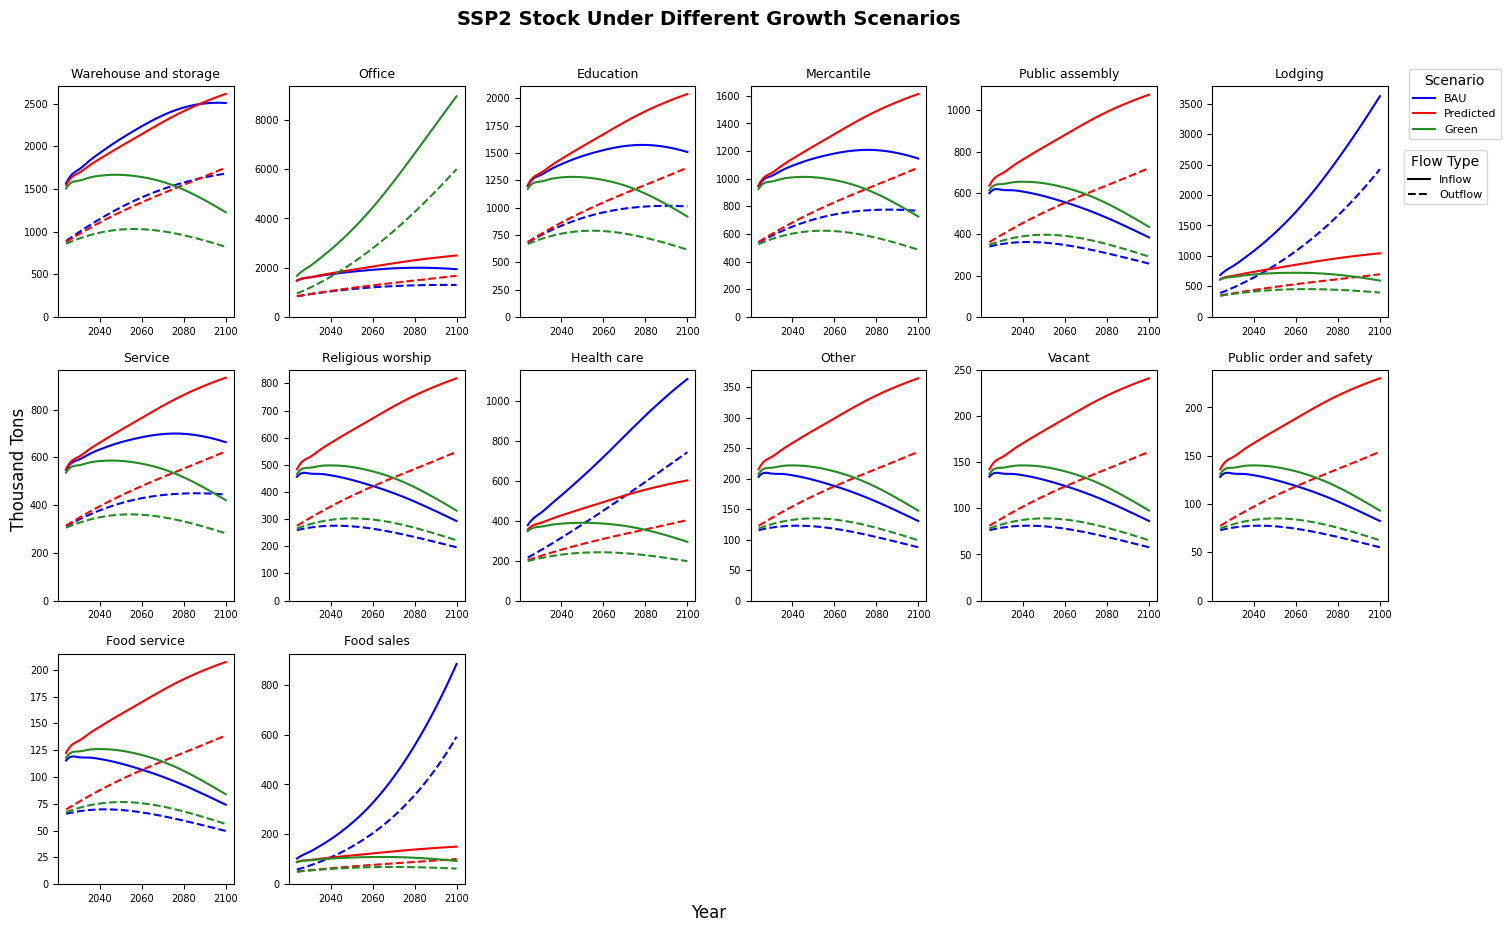

In [350]:
use_types = bau_inflows_ssp2.columns.tolist()
 
colors = {
    "BAU":       "blue",
    "Predicted": "red",
    "Green":     "forestgreen",
}
 
inflows = {
    "BAU":       bau_inflows_ssp2,
    "Predicted": predicted_inflows_ssp2,
    "Green":     green_inflows_ssp2,
}
 
outflows = {
    "BAU":       bau_outflows_ssp2,
    "Predicted": predicted_outflows_ssp2,
    "Green":     green_outflows_ssp2,
}
 
# === Layout ===
ncols = 6
nrows = -(-len(use_types) // ncols)  # ceiling division
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, nrows * 3))
axes_flat = axes.flatten()
 
for i, ut in enumerate(use_types):
    ax = axes_flat[i]
    for scenario, color in colors.items():
        ax.plot(inflows[scenario].index,  inflows[scenario][ut],  color=color, linestyle="-",  lw=1.5)
        ax.plot(outflows[scenario].index, outflows[scenario][ut], color=color, linestyle="--", lw=1.5)
    ax.set_title(ut, fontsize=9)
    ax.set_ylim(0,)
    ax.tick_params(labelsize=7)
 
# Hide any unused subplots
for j in range(len(use_types), len(axes_flat)):
    axes_flat[j].set_visible(False)
 
# === Shared axis labels ===
fig.text(0.5, 0.001, "Year",          ha="center", fontsize=12)
fig.text(0.001, 0.5, "Thousand Tons", va="center", rotation="vertical", fontsize=12)
 
# === Legend ===
scenario_handles = [
    mlines.Line2D([], [], color=color, linestyle="-", label=scenario)
    for scenario, color in colors.items()
]
flow_handles = [
    mlines.Line2D([], [], color="black", linestyle="-",  label="Inflow"),
    mlines.Line2D([], [], color="black", linestyle="--", label="Outflow"),
]
 
fig.subplots_adjust(right=0.85)  # make room on the right for legends

fig.legend(handles=scenario_handles, title="Scenario",  
           loc="upper right", bbox_to_anchor=(1.07, 0.95), fontsize=8)
fig.legend(handles=flow_handles,     title="Flow Type", 
           loc="upper right", bbox_to_anchor=(1.06, 0.86), fontsize=8)
 
fig.suptitle("SSP2 Stock Under Different Growth Scenarios", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
 

In [357]:
for df in [
    green_inflows_ssp1, green_outflows_ssp1,
    bau_inflows_ssp2, bau_outflows_ssp2, green_inflows_ssp2, green_outflows_ssp2, predicted_inflows_ssp2, predicted_outflows_ssp2,
    bau_inflows_ssp3, predicted_inflows_ssp3, predicted_outflows_ssp3,
    bau_inflows_ssp4, bau_outflows_ssp4, green_inflows_ssp4, green_outflows_ssp4, predicted_inflows_ssp4, predicted_outflows_ssp4,
    bau_inflows_ssp5, bau_outflows_ssp5, predicted_inflows_ssp5, predicted_outflows_ssp5,
]:
    df["total"] = df.sum(axis=1)

In [358]:
reuse_flags = {
    "Warehouse and Storage":     {"High": 1, "Mid": 1, "Low": 1},
    "Office":                  {"High": 1, "Mid": 1, "Low": 0},
    "Education":               {"High": 1, "Mid": 1, "Low": 0},
    "Mercantile":              {"High": 1, "Mid": 1, "Low": 0},
    "Public Assembly":         {"High": 1, "Mid": 1, "Low": 1},
    "Lodging":                 {"High": 1, "Mid": 1, "Low": 1},
    "Service":                 {"High": 1, "Mid": 0, "Low": 0},
    "Religious Worship":       {"High": 0, "Mid": 0, "Low": 0},
    "Health Care":             {"High": 1, "Mid": 0, "Low": 0},
    "Other":                   {"High": 0, "Mid": 0, "Low": 0},
    "Vacant":                  {"High": 0, "Mid": 0, "Low": 0},
    "Public Order and Safety": {"High": 0, "Mid": 0, "Low": 0},
    "Food Service":            {"High": 1, "Mid": 0, "Low": 0},
    "Food Sales":              {"High": 1, "Mid": 1, "Low": 1},
}

In [359]:
predicted_outflows_ssp5

Use Type,Warehouse and storage,Office,Education,Mercantile,Public assembly,Lodging,Service,Religious worship,Health care,Other,Vacant,Public order and safety,Food service,Food sales,total
Year,,,,,,,,,,,,,,,
2024,879.159933,837.874667,685.053810,542.139406,361.660941,350.799044,313.788136,275.117771,202.051399,122.447774,81.061935,77.340730,69.646886,50.588280,4848.730711
2025,894.252784,852.258760,696.814373,551.446506,367.869703,356.821336,319.175049,279.840816,205.520087,124.549879,82.453554,78.668466,70.842539,51.456747,4931.970599
2026,909.228161,866.530894,708.483397,560.681165,374.030140,362.796754,324.520032,284.527099,208.961777,126.635622,83.834342,79.985867,72.028885,52.318454,5014.562589
2027,924.086265,880.691263,720.061042,569.843507,380.142334,368.725378,329.823159,289.176683,212.376515,128.705031,85.204316,81.292952,73.205942,53.173413,5096.507799
2028,938.826883,894.739663,731.547139,578.933400,386.206197,374.607123,335.084353,293.789503,215.764252,130.758077,86.563458,82.589701,74.373691,54.021612,5177.805052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,1862.968831,1775.483994,1451.651570,1148.811244,766.371437,743.354720,664.927387,582.983611,428.153564,259.470863,171.772908,163.887551,147.584043,107.198229,10274.619955
2097,1880.467078,1792.160525,1465.286450,1159.601645,773.569709,750.336803,671.172829,588.459382,432.175068,261.907987,173.386314,165.426893,148.970251,108.205107,10371.126041
2098,1898.197533,1809.058359,1479.102270,1170.535240,780.863505,757.411542,677.501150,594.007819,436.249939,264.377452,175.021130,166.986662,150.374855,109.225346,10468.912800


In [360]:
high_reuse_types = [ut.lower() for ut in reuse_flags if reuse_flags[ut]["High"] == 1]
mid_reuse_types  = [ut.lower() for ut in reuse_flags if reuse_flags[ut]["Mid"]  == 1]
low_reuse_types  = [ut.lower() for ut in reuse_flags if reuse_flags[ut]["Low"]  == 1]

for df in [
    green_outflows_ssp1,
    bau_outflows_ssp2, green_outflows_ssp2, predicted_outflows_ssp2,
    bau_outflows_ssp3, predicted_outflows_ssp3,
    bau_outflows_ssp4, green_outflows_ssp4, predicted_outflows_ssp4,
    bau_outflows_ssp5, predicted_outflows_ssp5,
]:
    df.columns = [c.lower() if c != "total" else c for c in df.columns]
    df["total"]      = df[[c for c in df.columns if c not in ("total", "high_reuse", "mid_reuse", "low_reuse")]].sum(axis=1)
    df["high_reuse"] = df[high_reuse_types].sum(axis=1) / df["total"] * 100
    df["mid_reuse"]  = df[mid_reuse_types].sum(axis=1)  / df["total"] * 100
    df["low_reuse"]  = df[low_reuse_types].sum(axis=1)  / df["total"] * 100

In [361]:
green_outflows_ssp1

,warehouse and storage,office,education,mercantile,public assembly,lodging,service,religious worship,health care,other,vacant,public order and safety,food service,food sales,total,high_reuse,mid_reuse,low_reuse
Year,,,,,,,,,,,,,,,,,,
2024,856.858755,947.887745,665.679481,526.806906,348.703893,346.844563,304.913746,265.261262,197.516523,118.060898,78.157769,74.569881,67.151681,50.317607,4848.730711,88.944533,77.197501,33.054523
2025,867.545583,983.851131,673.645516,533.111085,352.418609,352.011738,308.562580,268.087070,200.079779,119.318592,78.990378,75.364269,67.867043,51.118075,4931.971447,89.015340,77.326111,32.909639
2026,877.911920,1020.651429,681.354699,539.211995,355.988893,357.071327,312.093762,270.803008,202.571594,120.527385,79.790614,76.127769,68.554591,51.904450,5014.563435,89.086811,77.456288,32.762106
2027,887.954580,1058.294820,688.804935,545.107979,359.414196,362.021174,315.506334,273.408658,204.991122,121.687092,80.558354,76.860266,69.214219,52.676371,5096.500100,89.158945,77.588031,32.611916
2028,897.670215,1096.786637,695.994011,550.797286,362.693910,366.859041,318.799283,275.903557,207.337482,122.797507,81.293463,77.561629,69.845810,53.433468,5177.773298,89.231739,77.721336,32.459062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,864.739986,5722.307355,648.083654,512.881881,309.171269,415.846309,296.853997,235.188545,206.624754,104.676313,69.297009,66.115880,59.538683,64.809827,9576.135461,95.036852,89.157472,17.278028
2097,857.485923,5817.040064,642.326314,508.325625,306.026869,413.345771,294.216854,232.796580,204.993699,103.611711,68.592229,65.443455,58.933150,64.484268,9637.622512,95.118672,89.327371,17.030578
2098,850.145076,5912.314336,636.509585,503.722369,302.861854,410.788931,291.552507,230.388933,203.340206,102.540130,67.882829,64.766620,58.323647,64.149204,9699.286227,95.199868,89.496187,16.784174


In [362]:
def make_scenario_df(inflow_df, outflow_df):
    return pd.DataFrame({
        "inflow_total":  inflow_df["total"],
        "outflow_total": outflow_df["total"],
        "high_reuse":    outflow_df["high_reuse"],
        "mid_reuse":     outflow_df["mid_reuse"],
        "low_reuse":     outflow_df["low_reuse"],
    })

green_ssp1      = make_scenario_df(green_inflows_ssp1,     green_outflows_ssp1)
bau_ssp2        = make_scenario_df(bau_inflows_ssp2,       bau_outflows_ssp2)
green_ssp2      = make_scenario_df(green_inflows_ssp2,     green_outflows_ssp2)
predicted_ssp2  = make_scenario_df(predicted_inflows_ssp2, predicted_outflows_ssp2)
bau_ssp3        = make_scenario_df(bau_inflows_ssp3,       bau_outflows_ssp3)
predicted_ssp3  = make_scenario_df(predicted_inflows_ssp3, predicted_outflows_ssp3)
bau_ssp4        = make_scenario_df(bau_inflows_ssp4,       bau_outflows_ssp4)
green_ssp4      = make_scenario_df(green_inflows_ssp4,     green_outflows_ssp4)
predicted_ssp4  = make_scenario_df(predicted_inflows_ssp4, predicted_outflows_ssp4)
bau_ssp5        = make_scenario_df(bau_inflows_ssp5,       bau_outflows_ssp5)
predicted_ssp5  = make_scenario_df(predicted_inflows_ssp5, predicted_outflows_ssp5)

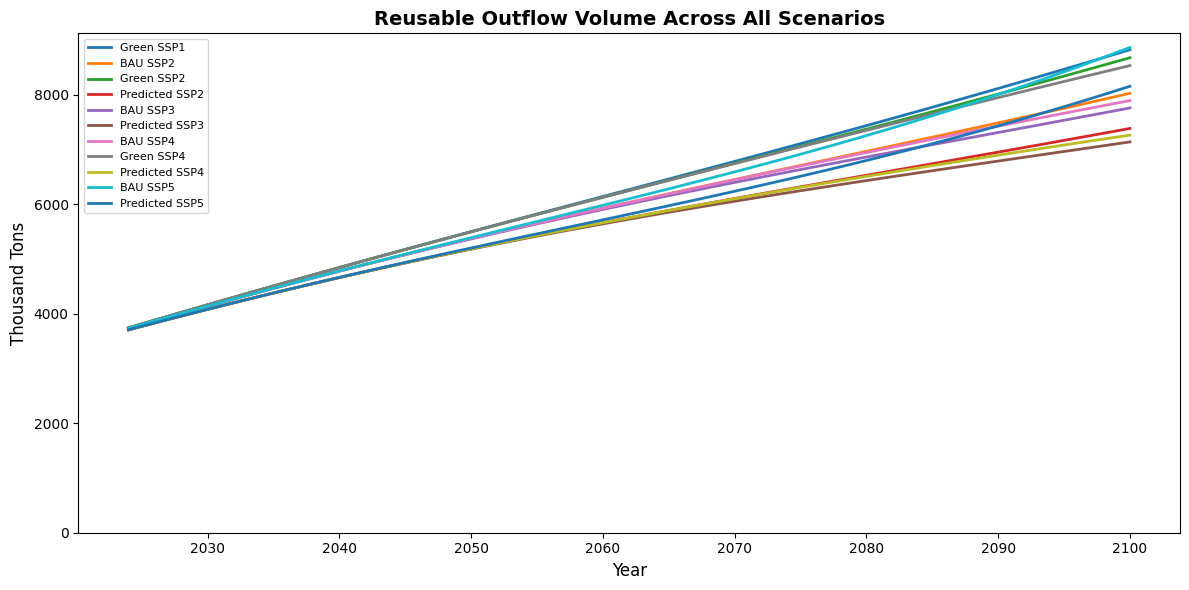

In [363]:
for df in [
    green_ssp1,
    bau_ssp2, green_ssp2, predicted_ssp2,
    bau_ssp3, predicted_ssp3,
    bau_ssp4, green_ssp4, predicted_ssp4,
    bau_ssp5, predicted_ssp5,
]:
    df["high_reuse_vol"] = df["outflow_total"] * df["high_reuse"] / 100
    df["mid_reuse_vol"]  = df["outflow_total"] * df["mid_reuse"]  / 100
    df["low_reuse_vol"]  = df["outflow_total"] * df["low_reuse"]  / 100

# === Plot ===
fig, ax = plt.subplots(figsize=(12, 6))

colors = plt.cm.tab10.colors

for i, (label, df) in enumerate(scenarios.items()):
    color = colors[i % len(colors)]
    ax.plot(df.index, df["mid_reuse_vol"], color=color, lw=2, label=label)
    #ax.fill_between(df.index, df["low_reuse_vol"], df["high_reuse_vol"], color=color, alpha=0.15)

ax.set_ylim(0,)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Thousand Tons", fontsize=12)
ax.set_title("Reusable Outflow Volume Across All Scenarios", fontsize=14, fontweight="bold")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

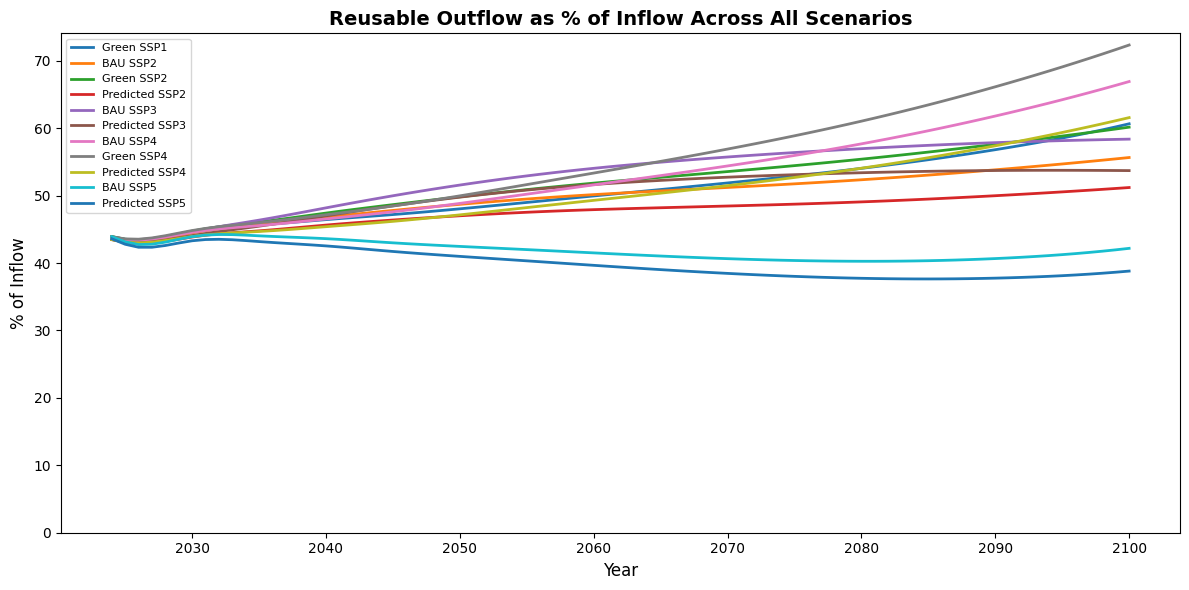

In [364]:
for df in [
    green_ssp1,
    bau_ssp2, green_ssp2, predicted_ssp2,
    bau_ssp3, predicted_ssp3,
    bau_ssp4, green_ssp4, predicted_ssp4,
    bau_ssp5, predicted_ssp5,
]:
    df["high_reuse_pct_inflow"] = (df["outflow_total"] * df["high_reuse"] / 100) / df["inflow_total"] * 100
    df["mid_reuse_pct_inflow"]  = (df["outflow_total"] * df["mid_reuse"]  / 100) / df["inflow_total"] * 100
    df["low_reuse_pct_inflow"]  = (df["outflow_total"] * df["low_reuse"]  / 100) / df["inflow_total"] * 100

# === Plot ===
fig, ax = plt.subplots(figsize=(12, 6))

for i, (label, df) in enumerate(scenarios.items()):
    color = colors[i % len(colors)]
    ax.plot(df.index, df["mid_reuse_pct_inflow"], color=color, lw=2, label=label)
    # ax.fill_between(df.index, df["low_reuse_pct_inflow"], df["high_reuse_pct_inflow"], color=color, alpha=0.15)

ax.set_ylim(0,)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("% of Inflow", fontsize=12)
ax.set_title("Reusable Outflow as % of Inflow Across All Scenarios", fontsize=14, fontweight="bold")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()